# Projeto Final — Segmentação do Mercado Imobiliário da Califórnia com Clusterização

### Seis tipos de bairro, uma estratégia para cada um

**Disciplina:** Aprendizado Não Supervisionado (Prof. Sergio Polimante) · MBA em Inteligência Artificial e Analytics Aplicadas a Negócios · FGV

**Integrantes:**

1. Jorge Adriano Fontes de Almeida Filho
2. Rafael Collet
3. Stephanie Santin Padovesi
4. Thaís Pereira de Vasconcelos Moreira
5. Yan Samuray Siepamann Vieira

**Dados:** California Housing (Censo dos EUA, 1990), com 20.640 vizinhanças, enriquecido com dados de litoral, condados e cidades · **Stack:** Python, pandas, scikit-learn, GeoPandas, Matplotlib

# Resumo executivo

**A pergunta:** a imobiliária segmenta a Califórnia por cidade e por faixa de preço. Existe uma divisão melhor, baseada no comportamento real dos bairros?

**A resposta:** sim. Agrupamos 20.555 vizinhanças com clusterização e encontramos **seis tipos de bairro**. Eles se repetem em todo o estado, são estáveis e pedem estratégias diferentes.

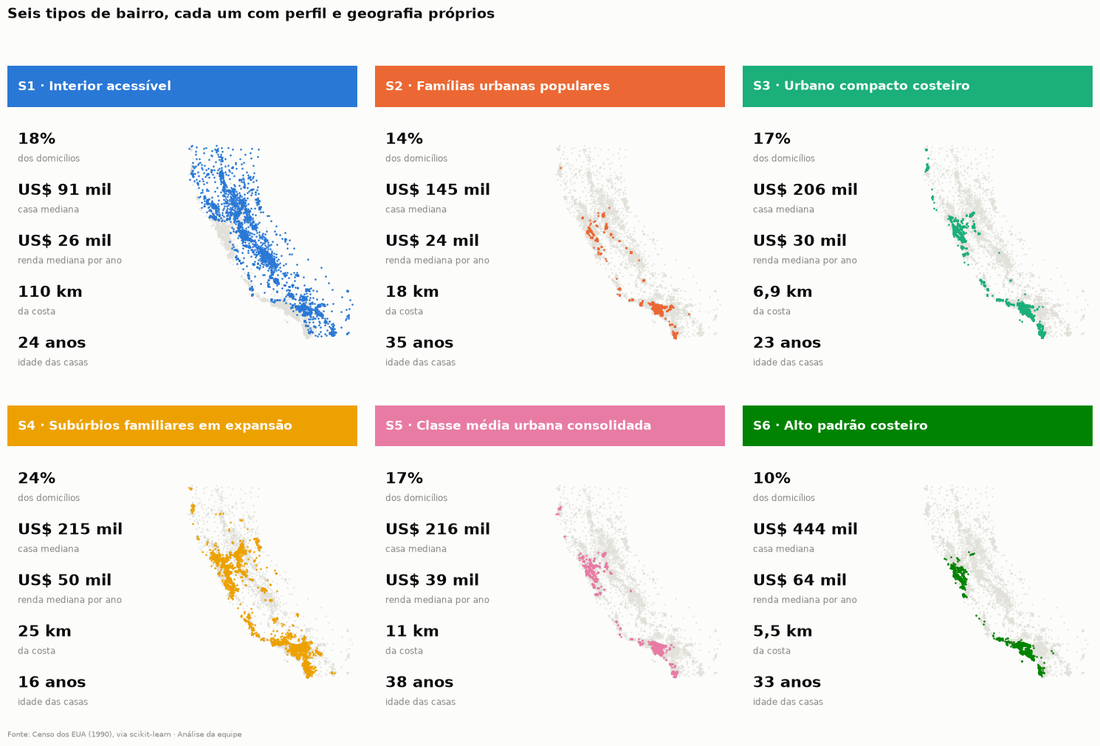

### Cinco achados

1. **Preço não define o cliente.** Três segmentos têm o mesmo preço mediano (cerca de US\$ 210 mil): apartamentos compactos perto do mar, casas novas de famílias no subúrbio e casas antigas da classe média. A segmentação por faixa de preço mistura os três.
2. **O mar vale por si só.** A casa mediana custa US\$ 256 mil até 5 km da costa e US\$ 87 mil a mais de 80 km, embora a renda dos moradores quase não mude.
3. **O crescimento está nos subúrbios.** O segmento S4 tem 23% dos bairros com casas de até 10 anos e é o maior mercado do estado, com 24% dos domicílios.
4. **O alto padrão é pequeno em clientes e grande em valor.** O segmento S6 tem 10% dos domicílios e 21% do valor do estoque de imóveis.
5. **Há oportunidades mapeadas.** Cerca de 1.700 bairros estão pelo menos 20% abaixo do preço que os seus fundamentos indicam, concentrados nos segmentos S3 e S1.

### Os seis segmentos

| Segmento | Domicílios | Casa mediana | Quem é | Papel na estratégia |
|---|---|---|---|---|
| **S1 · Interior acessível** | 18% | US\$ 91 mil | famílias de renda baixa a média no Vale Central, a 110 km do mar | volume e financiamento |
| **S2 · Famílias urbanas populares** | 14% | US\$ 145 mil | famílias grandes nos bairros mais densos de Los Angeles | locação e acesso à moradia |
| **S3 · Urbano compacto costeiro** | 17% | US\$ 206 mil | solteiros e casais em apartamentos a 7 km do mar | investidores e captação |
| **S4 · Subúrbios familiares em expansão** | 24% | US\$ 215 mil | famílias de renda média-alta em casas novas e grandes | **prioridade nº 1:** lançamentos |
| **S5 · Classe média urbana consolidada** | 17% | US\$ 216 mil | classe média nos bairros antigos de Los Angeles e San Francisco | revenda e reforma |
| **S6 · Alto padrão costeiro** | 10% | US\$ 444 mil ou mais | a maior renda do estado, em casas grandes a 5,5 km do mar | margem e relacionamento |

### Três recomendações

1. **Substituir a segmentação por cidade e preço pelos seis segmentos**, aplicando a mesma estratégia por segmento em todas as cidades.
2. **Concentrar cerca de um terço do orçamento e das equipes em S4**, com foco em lançamentos e na troca de imóvel.
3. **Abrir uma frente de investimento em S3**, usando o modelo de valor esperado para captar imóveis subvalorizados, e **tratar S6 como uma operação de luxo** dedicada.

**Como chegamos lá:** 20.555 vizinhanças · 7 variáveis · 4 algoritmos comparados · K-Means com 6 segmentos · estabilidade de 0,94 em 30 reamostragens.

### Como navegar

| Seção | Pergunta que responde |
|---|---|
| 2. Exploração e Análise dos Dados | Como é o mercado? Existem dados faltantes ou estranhos? |
| 3. Pré-processamento | Como preparar os dados para que as distâncias façam sentido? |
| 4. Engenharia de Features | Quais variáveis novas descrevem melhor um tipo de vizinhança? Quais usar? |
| 5. Redução de Dimensionalidade | Quantas dimensões reais o mercado tem? |
| 6. Algoritmos de Clusterização | Qual algoritmo e quantos segmentos? |
| 7. Avaliação e Validação | Os segmentos são bem separados, estáveis e fazem sentido no mapa? |
| 8. Interpretação e Caracterização | Quem é cada segmento? |
| 9. Estratégias de Negócio | O que a empresa deve fazer em cada segmento? |
| 10. Conclusão Final | Qualidade, insights, limitações, próximos passos e recomendações |

# 1. Introdução e Objetivos

## Contexto de negócio

Somos a equipe de análise de dados da **California Real Estate Analytics**, consultoria de mercado imobiliário que atende uma grande imobiliária da Califórnia, além de investidores institucionais, fundos imobiliários e construtoras. Hoje esses clientes segmentam o mercado do jeito tradicional: por **localização** (norte vs. sul, cidade) ou por **faixa de preço**. Essa divisão esconde diferenças importantes. Dois bairros com o mesmo preço podem ter clientes completamente diferentes (por exemplo, um apartamento pequeno perto da praia e uma casa grande no interior).

A empresa precisa de uma segmentação **baseada em padrões naturais dos dados** para:

- desenvolver **estratégias de marketing** direcionadas;
- **alocar equipes de vendas** e orçamento onde há mais potencial;
- identificar **oportunidades de investimento** (áreas em crescimento e subvalorizadas);
- **personalizar produtos e serviços** para cada tipo de cliente;
- definir **estratégias de precificação** por segmento.

**Metas de negócio** que a segmentação deve apoiar:

- aumentar a taxa de conversão de vendas de **12% para 25 a 30%**, com estratégias por segmento;
- reduzir o tempo médio de venda em **40%**, com marketing direcionado;
- identificar nichos subexplorados que representem **US\$ 50 a 100 milhões** em novos investimentos por ano.

Na conclusão (seção 10) avaliamos o que os resultados permitem afirmar sobre cada meta.

## Objetivo do projeto

Agrupar as vizinhanças da Califórnia em **segmentos de mercado acionáveis**, usando técnicas de clusterização (aprendizado não supervisionado), e traduzir cada segmento em uma estratégia de negócio.

**O que queremos que um segmento represente:** um *tipo* de vizinhança (quem mora lá, como é a moradia e qual é o entorno), e não apenas uma região do mapa. Um "bairro rico no litoral" deve ser reconhecido como tal, esteja ele perto de Los Angeles ou de San Francisco.

## Os dados

O **California Housing Dataset** (Censo dos EUA de 1990) tem 20.640 linhas. Cada linha é um **block group**: uma pequena vizinhança de 600 a 3.000 pessoas, descrita por renda, idade das casas, tamanho das moradias, população, localização e valor mediano das casas.

> **Nota sobre os números:** no texto e nas tabelas de resultados usamos o formato brasileiro (vírgula decimal: 0,5; ponto para milhar: 20.640). As saídas técnicas intermediárias do Python (como `describe()`) mantêm o formato americano (0.5; 20,640).

## Setup

Importamos as bibliotecas e fixamos uma semente aleatória (`RANDOM_STATE`), para que cada execução produza exatamente os mesmos resultados.

Também definimos a identidade visual do relatório:

- **Paleta acessível**, a mesma em todos os gráficos.
- **Títulos que já dizem a conclusão.** O título de cada eixo diz o que está sendo medido.
- **Fonte dos dados** no rodapé de cada figura.
- **Tabelas de resultados** com números no formato brasileiro.

In [1]:
from pathlib import Path
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
import seaborn as sns
import geopandas as gpd
from shapely.geometry import box
from IPython.display import display

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import squareform, cdist
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import IsolationForest, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.neighbors import BallTree, NearestNeighbors
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score, r2_score)
from sklearn.model_selection import KFold, cross_val_predict

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42          # mesma aleatoriedade em toda execução
DATA_DIR = Path("data")    # arquivos externos são baixados aqui uma única vez
DATA_DIR.mkdir(exist_ok=True)
EARTH_RADIUS_KM = 6371

In [2]:
# Paleta acessível (segura para daltonismo nos 3 primeiros tons) e estilo dos gráficos
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
PALETTE = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
GRAY, LIGHT_GRAY, INK, INK_2, SURFACE = "#898781", "#c3c2b7", "#0b0b0b", "#52514e", "#fcfcfb"

BLUES = LinearSegmentedColormap.from_list(
    "azuis", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("divergente", [BLUE, "#f0efec", RED])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 100, "axes.edgecolor": LIGHT_GRAY, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.labelsize": 9,
    "xtick.color": GRAY, "ytick.color": GRAY, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "figure.titlesize": 14, "figure.titleweight": "bold",
    "text.parse_math": False,
})
SOURCE_NOTE = "Fonte: Censo dos EUA (1990), via scikit-learn · Análise da equipe"


def finish(fig, note=SOURCE_NOTE, tight=True):
    """Ajusta o layout, escreve a fonte dos dados no rodapé e exibe a figura."""
    if tight:
        fig.tight_layout()
    fig.text(0.01, 0.0, note, ha="left", va="top", fontsize=7.5, color=GRAY)
    plt.show()


def action_title(fig, text):
    """Título da figura que já diz a conclusão (o título de cada eixo diz o que está sendo medido)."""
    fig.suptitle(text, x=0.01, ha="left")


def br(value, decimals=0):
    """Formata um número no padrão brasileiro: ponto para milhar e vírgula decimal."""
    if round(value, decimals) == 0:
        value = 0.0
    return f"{value:,.{decimals}f}".replace(",", "_").replace(".", ",").replace("_", ".")


# Formatos das tabelas executivas
TABLE_FORMATS = {
    "int": lambda v: br(v),
    "dec1": lambda v: br(v, 1),
    "dec2": lambda v: br(v, 2),
    "dec3": lambda v: br(v, 3),
    "pct": lambda v: f"{br(v, 1)}%",
    "pct0": lambda v: f"{br(v)}%",
    "usd": lambda v: f"US$ {br(v)}",
    "usd_mil": lambda v: f"US$ {br(v / 1000)} mil",
    "usd_bi": lambda v: f"US$ {br(v, 1)} bi",
    "km": lambda v: f"{br(v, 1)} km",
    "anos": lambda v: f"{br(v, 1)} anos",
}


def exec_table(df, formats, labels=None, highlight=None, caption=None, index=False):
    """Tabela de resultados: números no padrão brasileiro, rótulos legíveis e realce opcional numa coluna.

    `formats` associa colunas (ou linhas, em tabelas transpostas) a um formato de TABLE_FORMATS.
    `index=True` mantém os rótulos das linhas visíveis (por exemplo, o nome de cada métrica).
    """
    styler = df.style
    for key, kind in formats.items():
        subset = [key] if key in df.columns else pd.IndexSlice[[key], :]
        styler = styler.format(TABLE_FORMATS[kind], subset=subset, na_rep="–")
    if highlight is not None:
        styler = styler.background_gradient(cmap=BLUES, subset=[highlight], low=0, high=0.6)
    if labels:
        styler = styler.relabel_index([labels.get(c, c) for c in df.columns], axis="columns")
    if caption:
        styler = styler.set_caption(caption)
    styler = styler.hide(axis="index", names=True) if index else styler.hide(axis="index")
    # A classe tex2jax_ignore impede que o Jupyter interprete "US$ ... US$" como fórmula
    return (styler
            .set_table_attributes('class="tex2jax_ignore"')
            .set_table_styles([{"selector": "caption", "props": "text-align: left; font-weight: bold;"},
                               {"selector": "th", "props": "text-align: left;"}], overwrite=False))


def style_map(ax, title=None):
    """Enquadra a Califórnia com a proporção correta entre latitude e longitude."""
    ax.set_xlim(-124.6, -114.0)
    ax.set_ylim(32.4, 42.1)
    ax.set_aspect(1.25)
    ax.set_axis_off()
    if title:
        ax.set_title(title)


def boxplot_style():
    """Parâmetros comuns dos boxplots."""
    return dict(color="#cde2fb", linecolor=GRAY, linewidth=0.8, fliersize=2,
                flierprops={"markerfacecolor": ORANGE, "markeredgecolor": "none", "alpha": 0.5},
                medianprops={"color": BLUE, "linewidth": 2})


def download(url, filename):
    """Baixa um arquivo externo uma única vez e o guarda na pasta data/."""
    path = DATA_DIR / filename
    if not path.exists():
        print(f"Baixando {filename} ...")
        urllib.request.urlretrieve(url, path)
    return path

## Carregar os dados

Usamos a versão do dataset que vem com o **scikit-learn**. Se o download for bloqueado (por um firewall corporativo, por exemplo), a função reconstrói exatamente a mesma tabela a partir de uma cópia pública do arquivo original.

In [3]:
def load_california_housing():
    """Retorna o California Housing como um único DataFrame (8 variáveis + valor das casas)."""
    try:
        return fetch_california_housing(as_frame=True).frame
    except Exception as error:
        print(f"Download do scikit-learn falhou ({error}). Usando a cópia do GitHub.")
        url = ("https://media.githubusercontent.com/media/EpistasisLab/pmlb/"
               "master/datasets/537_houses/537_houses.tsv.gz")
        raw = pd.read_csv(url, sep="\t")
        households = raw["households"].round()
        return pd.DataFrame({
            "MedInc": raw["median_income"].round(4),
            "HouseAge": raw["housing_median_age"].round(),
            "AveRooms": raw["total_rooms"].round() / households,
            "AveBedrms": raw["total_bedrooms"].round() / households,
            "Population": raw["population"].round(),
            "AveOccup": raw["population"].round() / households,
            "Latitude": raw["latitude"].round(2),
            "Longitude": raw["longitude"].round(2),
            "MedHouseVal": raw["target"].round() / 100_000,
        })


df_raw = load_california_housing()
print(f"Linhas: {df_raw.shape[0]:,}  |  Colunas: {df_raw.shape[1]}")
df_raw.head()

Linhas: 20,640  |  Colunas: 9


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.325,41.000,6.984,1.024,322.000,2.556,37.880,-122.230,4.526
1,8.301,21.000,6.238,0.972,"2,401.000",2.110,37.860,-122.220,3.585
2,7.257,52.000,8.288,1.073,496.000,2.802,37.850,-122.240,3.521
3,5.643,52.000,5.817,1.073,558.000,2.548,37.850,-122.250,3.413
4,3.846,52.000,6.282,1.081,565.000,2.181,37.850,-122.250,3.422


### Dicionário de dados

| Coluna | Significado | Unidade |
|---|---|---|
| `MedInc` | Renda mediana dos domicílios | dezenas de milhares de US\$ (3,5 = US\$ 35.000 por ano) |
| `HouseAge` | Idade mediana das casas | anos |
| `AveRooms` | Número médio de cômodos por domicílio | cômodos |
| `AveBedrms` | Número médio de quartos por domicílio | quartos |
| `Population` | Pessoas que moram no block group | pessoas |
| `AveOccup` | Número médio de pessoas por domicílio | pessoas |
| `Latitude` / `Longitude` | Localização do block group | graus |
| `MedHouseVal` | Valor mediano das casas | centenas de milhares de US\$ (2,0 = US\$ 200.000) |

**`MedHouseVal` não é um "alvo" aqui.** Em clustering não existe variável a prever. O preço é tratado como mais uma característica da vizinhança, e uma das mais importantes para o negócio.

---
# 2. Exploração e Análise dos Dados

Antes de agrupar, precisamos entender o mercado: como cada variável se distribui, como elas se relacionam, onde ficam os preços altos e baixos e quais valores são estranhos.

## 2.1 Estrutura, tipos e valores ausentes

In [4]:
# Tipos de dado e contagem de valores preenchidos em cada coluna
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
# Quantidade de nulos, percentual de nulos e número de valores distintos por coluna
data_quality = pd.DataFrame({
    "valores_nulos": df_raw.isna().sum(),
    "pct_nulos": 100 * df_raw.isna().mean(),
    "valores_distintos": df_raw.nunique(),
})
print(f"Total de valores nulos: {df_raw.isna().sum().sum()}")
print(f"Linhas duplicadas: {df_raw.duplicated().sum()}")
data_quality

Total de valores nulos: 0
Linhas duplicadas: 0


,valores_nulos,pct_nulos,valores_distintos
MedInc,0,0.000,12928
HouseAge,0,0.000,52
AveRooms,0,0.000,19392
AveBedrms,0,0.000,14233
Population,0,0.000,3888
AveOccup,0,0.000,18841
Latitude,0,0.000,862
Longitude,0,0.000,844
MedHouseVal,0,0.000,3842


**Verificação de valores ausentes (documentada):**

- As 9 colunas são numéricas (`float64`) e têm 20.640 valores preenchidos.
- **Não há nenhum valor nulo** e não há linhas duplicadas. Portanto, **nenhuma imputação é necessária** (seção 3.1).
- Ausência de nulos não significa ausência de problemas: valores impossíveis ou extremos podem estar "escondidos" como números válidos. Investigamos isso na seção 2.6.

## 2.2 Estatísticas descritivas de todas as variáveis

Além das estatísticas usuais, mostramos a **assimetria (skew)**: perto de 0 significa uma distribuição simétrica; acima de 1 indica uma cauda longa à direita (poucos valores muito grandes).

In [6]:
# Estatísticas descritivas de todas as variáveis, acrescidas da assimetria (skew)
descriptive = df_raw.describe().T
descriptive["skew"] = df_raw.skew()
descriptive

,count,mean,std,min,25%,50%,75%,max,skew
MedInc,"20,640.000",3.871,1.900,0.500,2.563,3.535,4.743,15.000,1.647
HouseAge,"20,640.000",28.639,12.586,1.000,18.000,29.000,37.000,52.000,0.060
AveRooms,"20,640.000",5.429,2.474,0.846,4.441,5.229,6.052,141.909,20.698
AveBedrms,"20,640.000",1.097,0.474,0.333,1.006,1.049,1.100,34.067,31.317
Population,"20,640.000","1,425.477","1,132.462",3.000,787.000,"1,166.000","1,725.000","35,682.000",4.936
AveOccup,"20,640.000",3.071,10.386,0.692,2.430,2.818,3.282,"1,243.333",97.640
Latitude,"20,640.000",35.632,2.136,32.540,33.930,34.260,37.710,41.950,0.466
Longitude,"20,640.000",-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310,-0.298
MedHouseVal,"20,640.000",2.069,1.154,0.150,1.196,1.797,2.647,5.000,0.978


**O que a tabela mostra:**

- **Renda (`MedInc`):** a mediana é US\$ 35 mil por ano, mas a média (US\$ 38,7 mil) é puxada para cima por poucos bairros muito ricos (skew 1,6). O máximo de 15,0 é suspeito: é um teto do Censo (seção 2.6).
- **Valor das casas (`MedHouseVal`):** mediana de US\$ 180 mil, indo de US\$ 15 mil a exatamente US\$ 500 mil, outro teto.
- **Idade das casas (`HouseAge`):** a única variável simétrica (skew 0,06), de 1 a 52 anos. O 52 também é um teto.
- **`AveRooms`, `AveBedrms`, `AveOccup` e `Population`:** valores típicos razoáveis (5,2 cômodos e 2,8 pessoas por domicílio), mas máximos absurdos: 142 cômodos, 34 quartos e **1.243 pessoas por domicílio**. As assimetrias de 21, 31 e 98 indicam caudas extremas, que investigamos na seção 2.6.

## 2.3 Distribuições

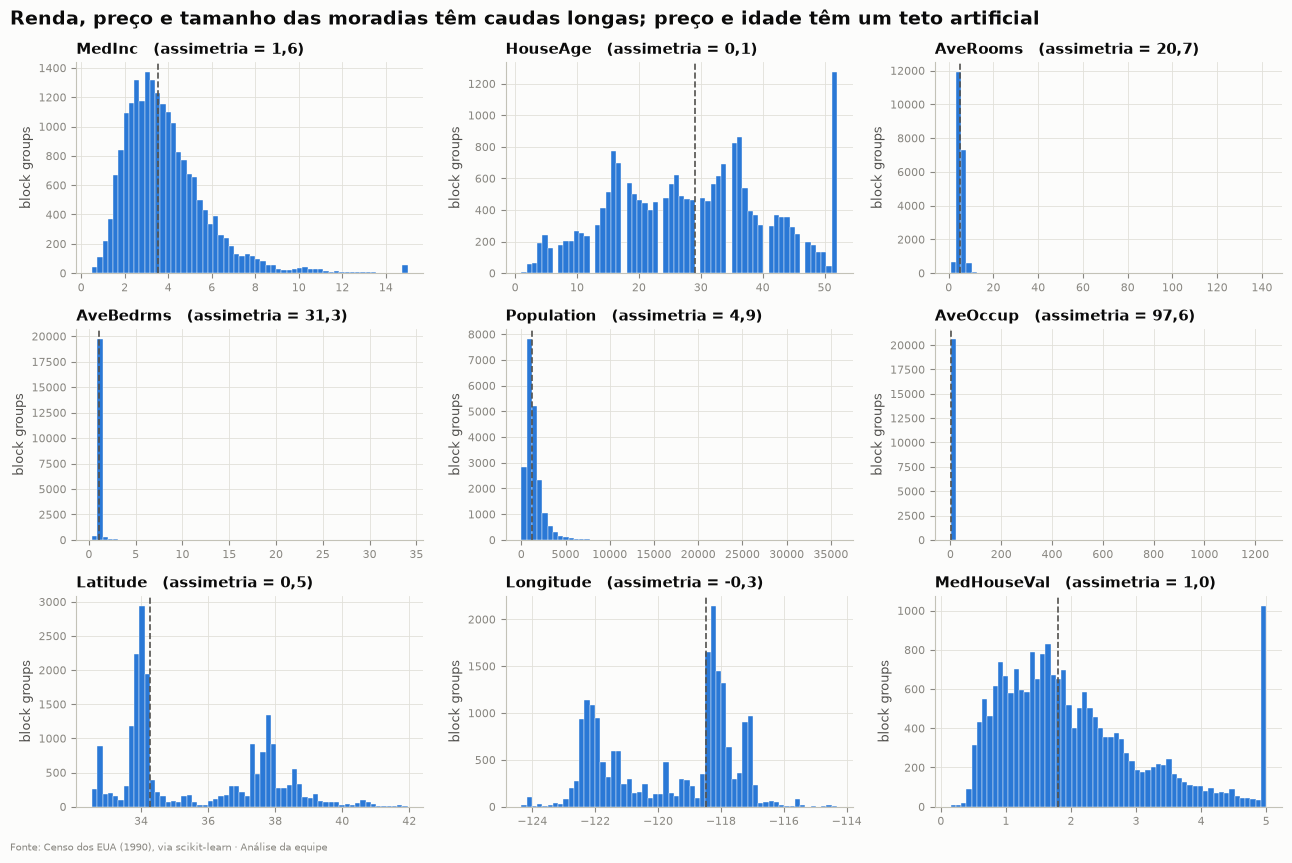

In [7]:
# Um histograma por variável, com a mediana marcada
fig, axes = plt.subplots(3, 3, figsize=(13, 8.5))
for ax, col in zip(axes.flat, df_raw.columns):
    ax.hist(df_raw[col], bins=60, color=BLUE, edgecolor=SURFACE, linewidth=0.3)
    ax.axvline(df_raw[col].median(), color=INK_2, linewidth=1.2, linestyle="--")
    ax.set_title(f"{col}   (assimetria = {br(df_raw[col].skew(), 1)})")
    ax.set_ylabel("block groups")
action_title(fig, "Renda, preço e tamanho das moradias têm caudas longas; preço e idade têm um teto artificial")
finish(fig)

- **Renda e valor** têm cauda longa à direita: a maioria dos bairros é de classe média ou baixa, com poucos bairros muito ricos. O valor das casas mostra um **pico artificial em US\$ 500 mil**, que é o teto.
- **`HouseAge`** tem um pico em 52 anos, também artificial.
- **`AveRooms`, `AveBedrms`, `AveOccup` e `Population`** aparecem "espremidos" à esquerda: alguns valores gigantes esticam o eixo e escondem a distribuição real.
- **Latitude e longitude** são bimodais: os dois picos são as regiões de **Los Angeles** (~34°N) e da **Baía de San Francisco** (~38°N). A população se concentra em duas grandes metrópoles.

## 2.4 Correlações entre as variáveis

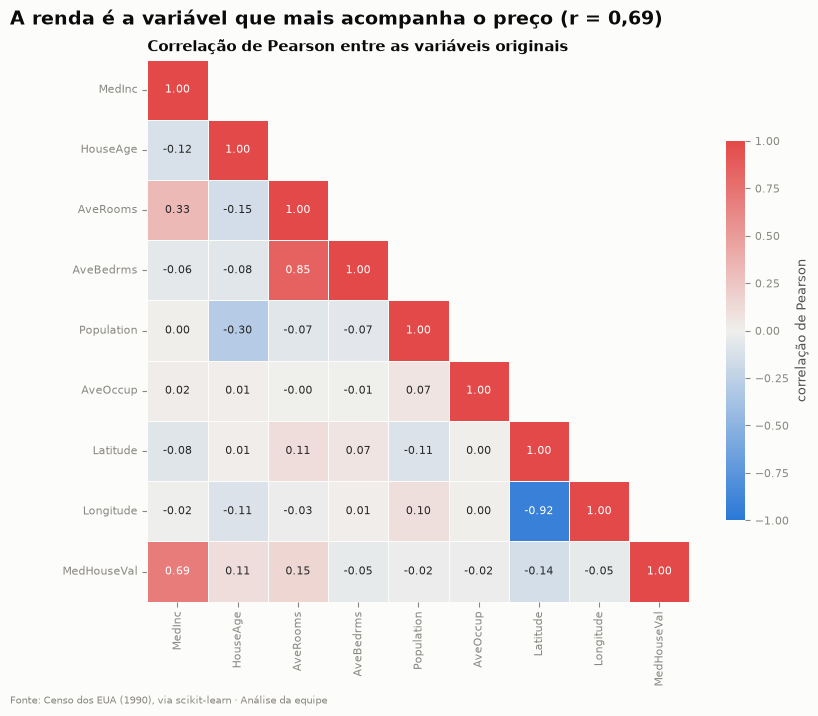

correlação
Latitude Longitude        -0.925
AveRooms AveBedrms         0.848
MedInc   MedHouseVal       0.688
         AveRooms          0.327
HouseAge Population       -0.296
         AveRooms         -0.153

In [8]:
# Correlação de Pearson entre as variáveis originais (só o triângulo inferior, sem repetição)
corr_raw = df_raw.corr(method="pearson")
upper_mask = np.triu(np.ones_like(corr_raw, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr_raw, mask=upper_mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, linewidths=0.5, linecolor=SURFACE, square=True,
            cbar_kws={"shrink": 0.7, "label": "correlação de Pearson"}, ax=ax)
ax.set_title("Correlação de Pearson entre as variáveis originais")
ax.grid(False)
action_title(fig, f"A renda é a variável que mais acompanha o preço (r = {br(corr_raw.loc['MedInc', 'MedHouseVal'], 2)})")
finish(fig)

# Os pares de variáveis com as correlações mais fortes, em valor absoluto
pairs = corr_raw.where(upper_mask).stack().rename("correlação")
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(6).to_frame()

- **Latitude × longitude (−0,93):** é só o formato diagonal do estado. Não há informação de mercado aqui.
- **`AveRooms` × `AveBedrms` (0,85):** casas com mais cômodos têm mais quartos. As duas dizem quase a mesma coisa, então manter as duas no clustering contaria "tamanho da casa" duas vezes.
- **Renda × valor (0,69):** a relação mais importante para o negócio. Bairros ricos têm casas caras, mas **a correlação está longe de 1**: há bairros com a mesma renda e preços muito diferentes. É justamente essa diferença (localização, tipo de imóvel) que a segmentação precisa capturar.
- As demais correlações são fracas (|r| < 0,35). As variáveis trazem, em geral, informações diferentes entre si.

## 2.5 Padrões geográficos e demográficos

### Onde ficam os preços e as rendas altas?

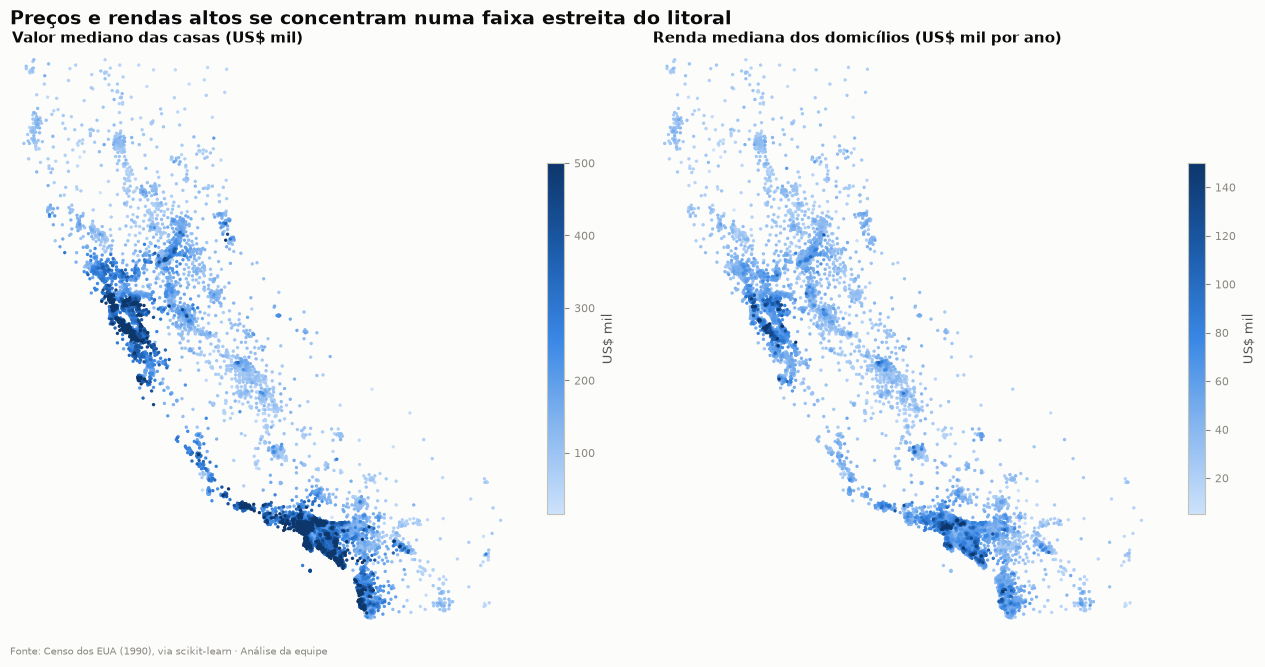

In [9]:
# Mapas de dispersão (longitude x latitude) coloridos pelo valor das casas e pela renda
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, col, factor, title in [
        (axes[0], "MedHouseVal", 100, "Valor mediano das casas (US$ mil)"),
        (axes[1], "MedInc", 10, "Renda mediana dos domicílios (US$ mil por ano)")]:
    order = df_raw[col].sort_values().index        # valores altos desenhados por cima
    points = ax.scatter(df_raw.loc[order, "Longitude"], df_raw.loc[order, "Latitude"],
                        c=df_raw.loc[order, col] * factor, cmap=BLUES, s=2)
    fig.colorbar(points, ax=ax, shrink=0.6, label="US$ mil")
    style_map(ax, title)
action_title(fig, "Preços e rendas altos se concentram numa faixa estreita do litoral")
finish(fig)

Os preços altos formam uma **faixa estreita ao longo do litoral**, concentrada na Baía de San Francisco e no eixo Los Angeles–Orange County–San Diego. Já o **Vale Central** (o "corredor" no meio do estado) e o interior têm preços baixos.

O mapa de renda se parece com o de preços, mas não é igual: há bairros de renda alta no interior (subúrbios de Sacramento, por exemplo) sem os preços do litoral. **A proximidade do oceano parece valer por si só**, além da renda dos moradores. Transformamos essa observação em uma feature na seção 4.

### Estatísticas descritivas por região

O dataset só tem latitude e longitude. Para analisar o mercado por região, **juntamos dados externos**:

1. **Condado:** os limites oficiais dos 58 condados da Califórnia (US Census Bureau, arquivo GeoJSON). Um *spatial join* encontra o condado que contém cada block group. Pontos no litoral que caem "no mar" (os limites são simplificados) recebem o condado mais próximo.
2. **Região:** uma tabela condado → região, com as 10 regiões usadas pelo governo da Califórnia no Censo de 2020.

In [10]:
# Limites oficiais dos condados (GeoJSON) para descobrir em qual condado está cada block group
counties_path = download(
    "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json",
    "us_counties_fips.geojson")
ca_counties = (gpd.read_file(counties_path)
               .query("STATE == '06'")
               .rename(columns={"NAME": "county"})[["county", "geometry"]])

# Spatial join: o condado cujo polígono contém o ponto de cada block group
points = gpd.GeoDataFrame(index=df_raw.index, crs="EPSG:4326",
                          geometry=gpd.points_from_xy(df_raw["Longitude"], df_raw["Latitude"]))
joined = gpd.sjoin(points, ca_counties, predicate="within", how="left")
joined = joined[~joined.index.duplicated(keep="first")]

# Pontos fora de todos os polígonos (litoral simplificado): condado mais próximo, em metros
outside = joined["county"].isna()
nearest = gpd.sjoin_nearest(points[outside].to_crs("EPSG:3310"), ca_counties.to_crs("EPSG:3310"),
                            how="left")
joined.loc[outside, "county"] = nearest.loc[~nearest.index.duplicated(), "county"]

# Tabela condado -> região (10 regiões do Censo de 2020 da Califórnia)
REGIONS = {
    "Superior California": ["Butte", "Colusa", "El Dorado", "Glenn", "Lassen", "Modoc", "Nevada",
                            "Placer", "Plumas", "Sacramento", "Shasta", "Sierra", "Siskiyou",
                            "Sutter", "Tehama", "Yolo", "Yuba"],
    "North Coast": ["Del Norte", "Humboldt", "Lake", "Mendocino", "Napa", "Sonoma", "Trinity"],
    "San Francisco Bay Area": ["Alameda", "Contra Costa", "Marin", "San Francisco", "San Mateo",
                               "Santa Clara", "Solano"],
    "Northern San Joaquin Valley": ["Alpine", "Amador", "Calaveras", "Madera", "Mariposa", "Merced",
                                    "Mono", "San Joaquin", "Stanislaus", "Tuolumne"],
    "Central Coast": ["Monterey", "San Benito", "San Luis Obispo", "Santa Barbara", "Santa Cruz",
                      "Ventura"],
    "Southern San Joaquin Valley": ["Fresno", "Inyo", "Kern", "Kings", "Tulare"],
    "Inland Empire": ["Riverside", "San Bernardino"],
    "Los Angeles County": ["Los Angeles"],
    "Orange County": ["Orange"],
    "San Diego - Imperial": ["Imperial", "San Diego"],
}
county_to_region = {county: region for region, counties in REGIONS.items() for county in counties}

geo = pd.DataFrame({"county": joined["county"]}, index=df_raw.index)
geo["region"] = geo["county"].map(county_to_region)
print(f"Block groups sem condado: {geo['county'].isna().sum()} | sem região: {geo['region'].isna().sum()}")

Block groups sem condado: 0 | sem região: 0


In [11]:
# Estatísticas por região, convertidas para dólares, ordenadas pelo valor mediano das casas
value_ceiling = df_raw["MedHouseVal"].max()
region_stats = (df_raw.assign(region=geo["region"])
                .groupby("region")
                .agg(block_groups=("MedInc", "size"),
                     renda_mediana_usd=("MedInc", "median"),
                     valor_mediano_usd=("MedHouseVal", "median"),
                     pct_no_teto_500k=("MedHouseVal", lambda s: 100 * (s == value_ceiling).mean()),
                     idade_mediana_anos=("HouseAge", "median"),
                     comodos_por_domicilio=("AveRooms", "median"),
                     pessoas_por_domicilio=("AveOccup", "median"),
                     populacao_total=("Population", "sum"))
                .sort_values("valor_mediano_usd", ascending=False))
region_stats["renda_mediana_usd"] = (region_stats["renda_mediana_usd"] * 10_000).round(-2)
region_stats["valor_mediano_usd"] = (region_stats["valor_mediano_usd"] * 100_000).round(-3)
exec_table(region_stats.reset_index(),
           formats={"block_groups": "int", "renda_mediana_usd": "usd_mil", "valor_mediano_usd": "usd_mil",
                    "pct_no_teto_500k": "pct", "idade_mediana_anos": "int", "comodos_por_domicilio": "dec1",
                    "pessoas_por_domicilio": "dec1", "populacao_total": "int"},
           labels={"region": "Região", "block_groups": "Block groups", "renda_mediana_usd": "Renda mediana",
                   "valor_mediano_usd": "Valor mediano", "pct_no_teto_500k": "No teto de US$ 500 mil",
                   "idade_mediana_anos": "Idade das casas (anos)", "comodos_por_domicilio": "Cômodos",
                   "pessoas_por_domicilio": "Pessoas/domicílio", "populacao_total": "População"},
           highlight="valor_mediano_usd", caption="Estatísticas descritivas por região (medianas)")

Região,Block groups,Renda mediana,Valor mediano,No teto de US$ 500 mil,Idade das casas (anos),Cômodos,Pessoas/domicílio,População
San Francisco Bay Area,4.004,US$ 42 mil,US$ 254 mil,"8,5%",34,"5,3","2,7",5.442.440
Orange County,1.586,US$ 46 mil,US$ 231 mil,"6,2%",23,"5,5","2,9",2.326.296
Central Coast,1.250,US$ 38 mil,US$ 231 mil,"3,9%",24,"5,5","2,8",1.856.985
Los Angeles County,5.857,US$ 35 mil,US$ 204 mil,"7,3%",35,"4,7","3,0",8.824.274
San Diego - Imperial,1.727,US$ 35 mil,US$ 164 mil,"2,5%",21,"5,2","2,8",2.554.203
North Coast,753,US$ 31 mil,US$ 147 mil,"0,0%",24,"5,6","2,6",783.207
Inland Empire,1.420,US$ 32 mil,US$ 117 mil,"0,5%",19,"5,7","3,0",2.573.890
Northern San Joaquin Valley,1.083,US$ 28 mil,US$ 111 mil,"0,0%",23,"5,4","2,9",1.253.828
Superior California,1.704,US$ 29 mil,US$ 109 mil,"0,1%",22,"5,5","2,6",2.201.678
Southern San Joaquin Valley,1.256,US$ 26 mil,US$ 72 mil,"0,0%",25,"5,3","3,0",1.605.039


- **Todos os 20.640 block groups receberam um condado e uma região**, nenhum ficou sem classificação.
- **Diferença de preço de 3,5 vezes entre regiões:** a mediana vai de US\$ 254 mil na Baía de San Francisco a US\$ 72 mil no sul do Vale de San Joaquin.
- **Renda e preço não andam juntos:** Orange County tem a maior renda (US\$ 46,4 mil), mas a Baía de San Francisco tem o maior preço. A Central Coast tem o mesmo preço mediano de Orange County (US\$ 231 mil) com uma renda bem menor (US\$ 37,8 mil).
- **O teto de US\$ 500 mil é um fenômeno das metrópoles:** atinge 8,5% dos block groups da Baía, 7,3% de Los Angeles e 6,2% de Orange County, e praticamente zero no interior.
- **Los Angeles County sozinho tem 28% dos block groups** (5.857). Qualquer segmentação será fortemente influenciada pelo mercado de Los Angeles.

### Identificando possíveis segmentos visualmente

A relação entre **renda** e **valor das casas** é o eixo central do mercado. Separamos as regiões em três grandes áreas para ver se elas formam padrões diferentes nesse gráfico.

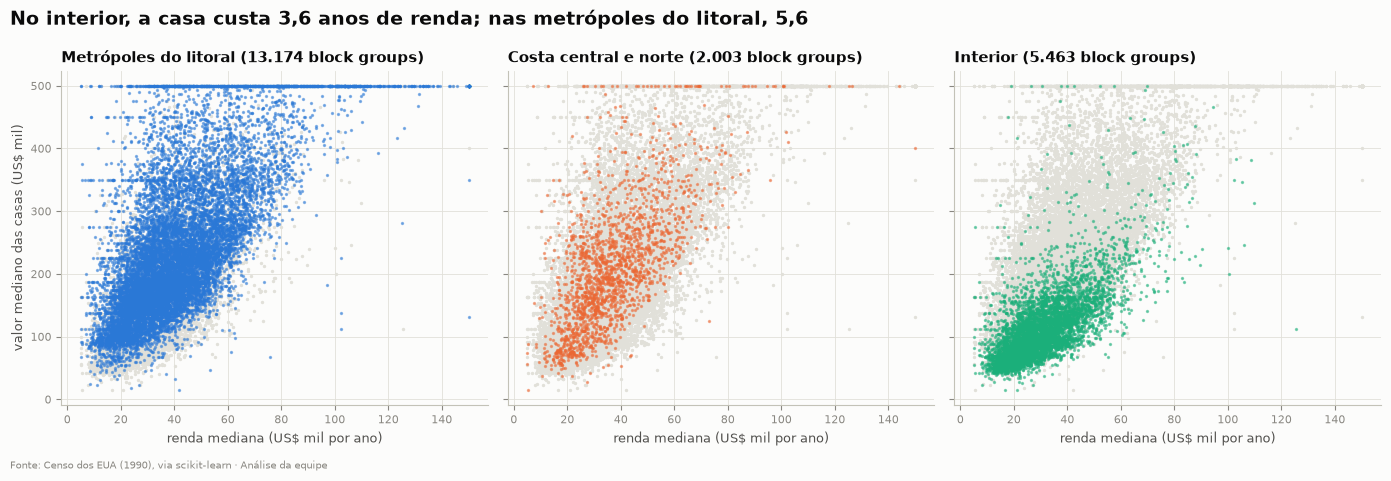

Área,Renda mediana,Valor mediano,Anos de renda por casa
Metrópoles do litoral,US$ 39 mil,US$ 217 mil,"5,6"
Costa central e norte,US$ 35 mil,US$ 202 mil,"5,8"
Interior,US$ 29 mil,US$ 102 mil,"3,6"


In [12]:
# Agrupa as regiões em três grandes áreas para a análise visual
AREA_OF_REGION = {
    "San Francisco Bay Area": "Metrópoles do litoral", "Los Angeles County": "Metrópoles do litoral",
    "Orange County": "Metrópoles do litoral", "San Diego - Imperial": "Metrópoles do litoral",
    "Central Coast": "Costa central e norte", "North Coast": "Costa central e norte",
}
area = geo["region"].map(AREA_OF_REGION).fillna("Interior")
AREAS = ["Metrópoles do litoral", "Costa central e norte", "Interior"]

# Renda e valor medianos por área, e quantas vezes a renda anual a casa custa
area_summary = (df_raw.groupby(area)[["MedInc", "MedHouseVal"]].median()
                .assign(preco_por_renda=lambda d: (d["MedHouseVal"] * 100_000) / (d["MedInc"] * 10_000))
                .reindex(AREAS))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
for ax, name, color in zip(axes, AREAS, [BLUE, ORANGE, AQUA]):
    inside = area == name
    ax.scatter(df_raw.loc[~inside, "MedInc"] * 10, df_raw.loc[~inside, "MedHouseVal"] * 100,
               s=2, color="#e1e0d9")
    ax.scatter(df_raw.loc[inside, "MedInc"] * 10, df_raw.loc[inside, "MedHouseVal"] * 100,
               s=2, color=color, alpha=0.5)
    ax.set_title(f"{name} ({br(inside.sum())} block groups)")
    ax.set_xlabel("renda mediana (US$ mil por ano)")
axes[0].set_ylabel("valor mediano das casas (US$ mil)")
action_title(fig, f"No interior, a casa custa {br(area_summary.loc['Interior', 'preco_por_renda'], 1)} anos de renda; "
                  f"nas metrópoles do litoral, {br(area_summary.loc['Metrópoles do litoral', 'preco_por_renda'], 1)}")
finish(fig)

exec_table(area_summary.assign(MedInc=area_summary["MedInc"] * 10_000,
                               MedHouseVal=area_summary["MedHouseVal"] * 100_000).reset_index(names="area"),
           formats={"MedInc": "usd_mil", "MedHouseVal": "usd_mil", "preco_por_renda": "dec1"},
           labels={"area": "Área", "MedInc": "Renda mediana", "MedHouseVal": "Valor mediano",
                   "preco_por_renda": "Anos de renda por casa"})

**Já é possível enxergar pelo menos dois mercados diferentes:**

- **Interior:** renda mediana de US\$ 28,6 mil e casas de US\$ 102 mil. A casa custa cerca de **3,6 anos de renda**, e a nuvem de pontos fica achatada embaixo, pois mesmo os bairros de renda alta raramente passam de US\$ 300 mil.
- **Metrópoles e costa:** custam **5,6 a 5,8 anos de renda**. Para a mesma renda, a casa vale bem mais, e muitos bairros encostam no teto de US\$ 500 mil.

Dentro das metrópoles, a nuvem é larga: para uma renda de US\$ 40 mil, há bairros de US\$ 150 mil e de US\$ 450 mil. **Renda e região não bastam para descrever o mercado.** Precisamos de mais dimensões (tipo de moradia, densidade, proximidade do mar), e é isso que o clustering vai combinar.

## 2.6 Identificação de outliers

Um **outlier** é um valor muito diferente do resto, mas "diferente" não significa "errado". Para clustering, outliers importam porque o K-Means coloca o centro de cada cluster na **média** dos seus pontos: um único ponto extremo pode arrastar um centro para longe ou virar um cluster sozinho.

Usamos três lentes complementares:

1. **Regra do IQR (boxplot):** olha uma coluna de cada vez.
2. **Valores de teto:** valores gravados no limite máximo do Censo.
3. **Isolation Forest:** olha todas as colunas juntas (anomalias multivariadas).

Depois perguntamos o mais importante: **o que essas linhas são no mundo real?**

### Regra do IQR e boxplots

Um valor é outlier se cair fora de `[Q1 − 1,5 × IQR, Q3 + 1,5 × IQR]`, em que `IQR = Q3 − Q1`. Os quartis não são puxados por valores extremos, o que torna a regra mais robusta que o z-score em dados assimétricos.

In [13]:
def iqr_bounds(series, k=1.5):
    """Limites (inferior, superior) da regra do IQR para uma coluna."""
    q1, q3 = series.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)


# Marca, coluna a coluna, os valores fora dos limites do IQR
iqr_flags = pd.DataFrame({col: ~df_raw[col].between(*iqr_bounds(df_raw[col])) for col in df_raw.columns})
iqr_table = pd.DataFrame({
    "limite_inferior": [iqr_bounds(df_raw[c])[0] for c in df_raw.columns],
    "limite_superior": [iqr_bounds(df_raw[c])[1] for c in df_raw.columns],
    "outliers": iqr_flags.sum(),
    "pct_outliers": 100 * iqr_flags.mean(),
}, index=df_raw.columns)
iqr_any = iqr_flags.any(axis=1)
print(f"Linhas marcadas em pelo menos uma coluna: {iqr_any.sum():,} ({iqr_any.mean():.1%})")
iqr_table

Linhas marcadas em pelo menos uma coluna: 4,328 (21.0%)


,limite_inferior,limite_superior,outliers,pct_outliers
MedInc,-0.706,8.013,681,3.299
HouseAge,-10.500,65.500,0,0.000
AveRooms,2.023,8.470,511,2.476
AveBedrms,0.866,1.240,1424,6.899
Population,-620.000,"3,132.000",1196,5.795
AveOccup,1.151,4.561,711,3.445
Latitude,28.260,43.380,0,0.000
Longitude,-127.485,-112.325,0,0.000
MedHouseVal,-0.981,4.824,1071,5.189


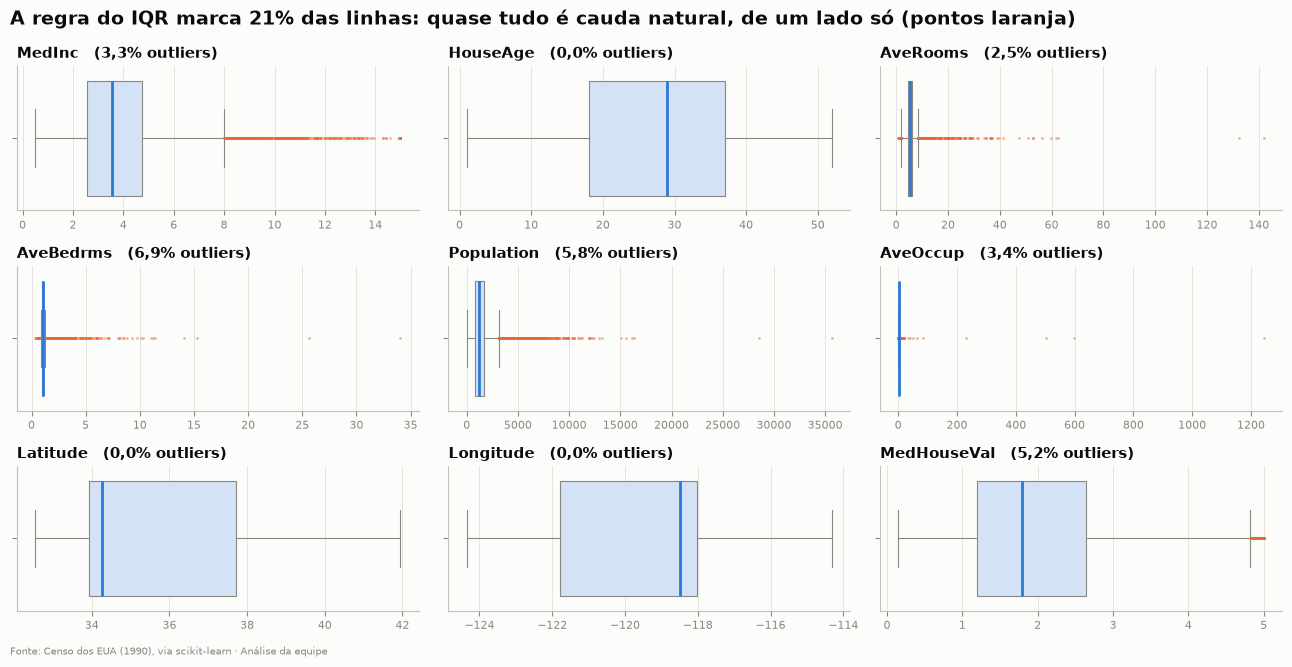

In [14]:
# Boxplot de cada variável, com o percentual de outliers no título
fig, axes = plt.subplots(3, 3, figsize=(13, 6.5))
for ax, col in zip(axes.flat, df_raw.columns):
    sns.boxplot(x=df_raw[col], ax=ax, **boxplot_style())
    ax.set_title(f"{col}   ({br(iqr_table.loc[col, 'pct_outliers'], 1)}% outliers)")
    ax.set_xlabel("")
action_title(fig, f"A regra do IQR marca {br(100 * iqr_any.mean())}% das linhas: quase tudo é cauda natural, "
                  "de um lado só (pontos laranja)")
finish(fig)

- **21% das linhas** são marcadas em pelo menos uma coluna. É muito: não podemos simplesmente apagar um quinto do mercado.
- **`AveBedrms` tem a maior taxa (6,9%)** porque a sua faixa central é estreita (1,0 a 1,1 quarto por domicílio). Qualquer desvio pequeno já vira outlier.
- **`Population` (5,8%), `MedHouseVal` (5,2%), `AveOccup` (3,4%) e `MedInc` (3,3%)** são marcadas sobretudo no lado alto, pela cauda longa.
- **`HouseAge`, latitude e longitude não têm outliers.**

Nos boxplots, quase todos os outliers estão de um lado só (à direita). Isso é **assimetria natural**, e não erro. A seguir, separamos o que é cauda natural do que é realmente anômalo.

### Valores de teto (censura)

Alguns campos do Censo gravam todo valor acima de um limite **como o próprio limite**. Para encontrá-los, contamos quantas linhas têm exatamente o valor máximo: numa coluna normal, só uma ou duas.

,valor_maximo,linhas_no_maximo,pct_no_maximo
HouseAge,52.000,1273,6.168
MedHouseVal,5.000,965,4.675
MedInc,15.000,49,0.237
Latitude,41.950,2,0.010


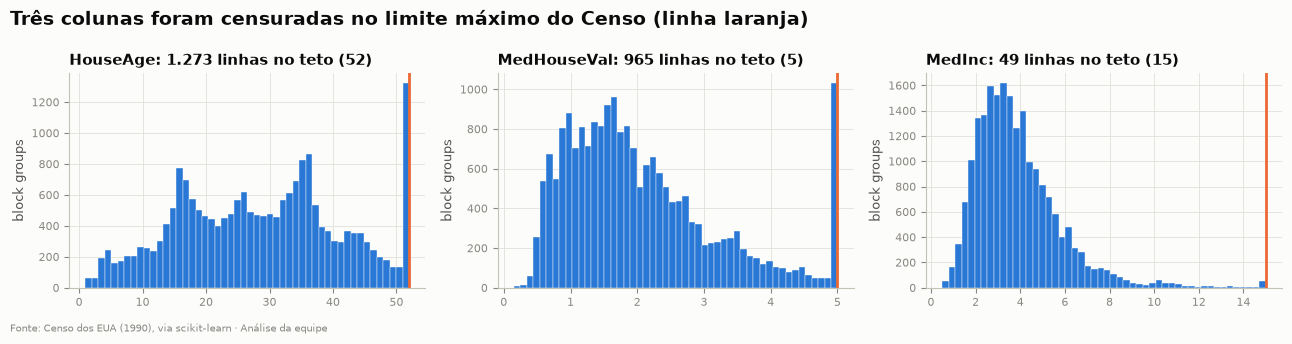

In [15]:
# Conta quantas linhas têm exatamente o valor máximo de cada coluna (sinal de teto/censura)
ceiling = pd.DataFrame({"valor_maximo": df_raw.max(), "linhas_no_maximo": (df_raw == df_raw.max()).sum()})
ceiling["pct_no_maximo"] = 100 * ceiling["linhas_no_maximo"] / len(df_raw)
display(ceiling.sort_values("linhas_no_maximo", ascending=False).head(4))

# Histogramas das três colunas censuradas, com o teto marcado em laranja
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col in zip(axes, ["HouseAge", "MedHouseVal", "MedInc"]):
    ax.hist(df_raw[col], bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.3)
    ax.axvline(df_raw[col].max(), color=ORANGE, linewidth=2)
    ax.set_title(f"{col}: {br(ceiling.loc[col, 'linhas_no_maximo'])} linhas no teto ({br(df_raw[col].max(), 0)})")
    ax.set_ylabel("block groups")
action_title(fig, "Três colunas foram censuradas no limite máximo do Censo (linha laranja)")
finish(fig)

Três colunas foram **censuradas no limite máximo** do Censo:

| Coluna | Teto | Linhas no teto | O que significa |
|---|---|---|---|
| `HouseAge` | 52 anos | 1.273 (6,2%) | "52 anos ou mais" |
| `MedHouseVal` | US\$ 500 mil | 965 (4,7%) | "US\$ 500 mil ou mais" |
| `MedInc` | US\$ 150 mil | 49 (0,2%) | "US\$ 150 mil ou mais" |

**Esses valores são reais, mas incompletos:** sabemos que o bairro está *pelo menos* no teto. Numa coluna normal, o máximo aparece em uma ou duas linhas (como a latitude). Para o negócio, os bairros no teto de preço são justamente o **mercado de altíssimo padrão**. Eles não devem ser removidos, mas precisam ser marcados, porque o preço real deles é desconhecido.

### A regra do IQR na escala log

Em colunas assimétricas, a cauda longa à direita é *normal*, mas a regra do IQR a marca mesmo assim. Uma transformação log comprime a cauda. Se um valor **continua** sendo outlier na escala log, ele é de fato extremo.

In [16]:
# Compara o número de outliers do IQR na escala original e na escala log, nas colunas assimétricas
skewed_cols = [col for col in df_raw.columns if df_raw[col].skew() > 0.5]
log_compare = pd.DataFrame({
    "outliers_escala_original": [iqr_flags[c].sum() for c in skewed_cols],
    "outliers_escala_log": [(~np.log(df_raw[c]).between(*iqr_bounds(np.log(df_raw[c])))).sum()
                            for c in skewed_cols],
}, index=skewed_cols)
log_compare["variacao_pct"] = 100 * (log_compare["outliers_escala_log"] / log_compare["outliers_escala_original"] - 1)
log_compare

,outliers_escala_original,outliers_escala_log,variacao_pct
MedInc,681,277,-59.325
AveRooms,511,571,11.742
AveBedrms,1424,1379,-3.160
Population,1196,847,-29.181
AveOccup,711,510,-28.270
MedHouseVal,1071,26,-97.572


- **`MedHouseVal` cai de 1.071 para 26 outliers (−98%)** e **`MedInc` de 681 para 277 (−59%):** quase todos eram só a cauda natural de renda e preço.
- **`Population` e `AveOccup` caem cerca de 30%**, mas continuam com centenas de casos: há extremos de verdade.
- **`AveRooms` e `AveBedrms` não melhoram** (+12% e −3%). Os extremos dessas colunas não são "cauda longa": são valores anômalos, como 142 cômodos por domicílio.

**Conclusão:** a transformação log resolve a maior parte do problema de renda e preço. Os casos que sobram em tamanho e ocupação precisam ser entendidos um a um.

### Isolation Forest: anomalias multivariadas

- O algoritmo constrói muitas árvores com cortes aleatórios. Um ponto **comum** precisa de muitos cortes para ficar isolado; um ponto **incomum** fica isolado com poucos cortes.
- Ele olha **todas as colunas ao mesmo tempo** e não precisa de scaling.
- A fração esperada de anomalias (`contamination`) é uma escolha de negócio. Usamos **1%**: o suficiente para encontrar os casos mais isolados sem marcar vizinhanças normais.

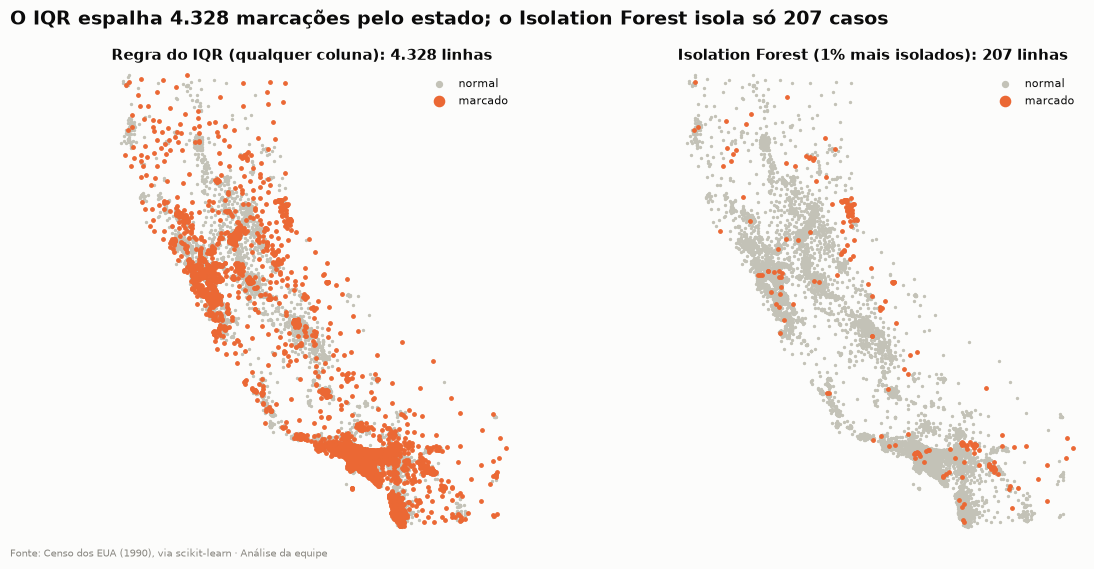

,mediana_linhas_normais,mediana_anomalias_IF,razao
MedInc,3.534,3.631,1.027
HouseAge,29.000,17.000,0.586
AveRooms,5.217,15.511,2.973
AveBedrms,1.048,3.013,2.874
Population,"1,171.000",337.000,0.288
AveOccup,2.821,2.579,0.914
Latitude,34.250,37.250,1.088
Longitude,-118.490,-119.570,1.009
MedHouseVal,1.800,1.545,0.858


In [17]:
# Isolation Forest sobre todas as colunas: marca o 1% de linhas mais fáceis de isolar
iso = IsolationForest(n_estimators=300, contamination=0.01, random_state=RANDOM_STATE, n_jobs=-1)
if_flag = pd.Series(iso.fit_predict(df_raw) == -1, index=df_raw.index)

# Onde ficam, no mapa, as linhas marcadas por cada método
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, flag, name in [(axes[0], iqr_any, "Regra do IQR (qualquer coluna)"),
                       (axes[1], if_flag, "Isolation Forest (1% mais isolados)")]:
    ax.scatter(df_raw.loc[~flag, "Longitude"], df_raw.loc[~flag, "Latitude"], s=2, color=LIGHT_GRAY,
               label="normal")
    ax.scatter(df_raw.loc[flag, "Longitude"], df_raw.loc[flag, "Latitude"], s=6, color=ORANGE,
               label="marcado")
    style_map(ax, f"{name}: {br(flag.sum())} linhas")
    ax.legend(loc="upper right", markerscale=3)
action_title(fig, f"O IQR espalha {br(iqr_any.sum())} marcações pelo estado; "
                  f"o Isolation Forest isola só {br(if_flag.sum())} casos")
finish(fig)

# Perfil típico (mediana) das anomalias comparado com o das linhas normais
anomaly_profile = pd.DataFrame({
    "mediana_linhas_normais": df_raw[~if_flag].median(),
    "mediana_anomalias_IF": df_raw[if_flag].median(),
})
anomaly_profile["razao"] = anomaly_profile["mediana_anomalias_IF"] / anomaly_profile["mediana_linhas_normais"]
anomaly_profile

- **O IQR marca 4.328 linhas espalhadas por todo o estado.** Isso confirma que ele confunde cauda natural com anomalia.
- **O Isolation Forest marca 207 linhas**, concentradas em **áreas rurais e de montanha** (Sierra Nevada, Lake Tahoe, deserto).
- **O perfil das anomalias é claro:** quase **3 vezes mais cômodos e quartos** por domicílio, **população 3,5 vezes menor** e casas mais novas (17 vs. 29 anos). A renda é igual à das demais.

São block groups pequenos, de **casas de veraneio**, e não bairros "errados".

### Quem são os outliers? Dando significado de negócio

Os detectores dizem **quais** linhas são estranhas, mas não **por quê**. Reconstruímos uma coluna escondida, o **número de domicílios** (`Population / AveOccup`), e olhamos os casos mais extremos.

In [18]:
# Número de domicílios = população / pessoas por domicílio (coluna que o dataset não traz)
households_raw = (df_raw["Population"] / df_raw["AveOccup"]).round()
with_households = df_raw.assign(households=households_raw)

print("Maiores AveOccup (pessoas por domicílio)")
display(with_households.nlargest(6, "AveOccup"))
print("Maiores AveRooms (cômodos por domicílio)")
display(with_households.nlargest(6, "AveRooms"))
print("Maiores Population")
display(with_households.nlargest(4, "Population"))

Maiores AveOccup (pessoas por domicílio)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,households
19006,10.226,45.000,3.167,0.833,"7,460.000","1,243.333",38.320,-121.980,1.375,6.000
3364,5.518,36.000,5.143,1.143,"4,198.000",599.714,40.410,-120.510,0.675,7.000
16669,4.264,46.000,9.077,1.308,"6,532.000",502.462,35.320,-120.700,3.500,13.000
13034,6.136,52.000,8.276,1.517,"6,675.000",230.172,38.690,-121.150,2.250,29.000
9172,4.239,5.000,5.124,0.933,"8,733.000",83.171,34.470,-118.590,1.546,105.000
12104,1.625,8.000,7.600,0.950,"1,275.000",63.750,33.970,-117.330,1.625,20.000


Maiores AveRooms (cômodos por domicílio)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,households
1914,1.875,33.000,141.909,25.636,30.000,2.727,38.910,-120.100,5.000,11.000
1979,4.625,34.000,132.533,34.067,36.000,2.400,38.800,-120.080,1.625,15.000
12447,1.615,17.000,62.422,14.111,83.000,1.844,33.970,-114.490,0.875,45.000
1913,4.071,19.000,61.812,11.000,112.000,2.333,39.010,-120.060,4.375,48.000
11862,2.625,25.000,59.875,15.312,28.000,1.750,40.270,-121.250,0.675,16.000
1912,4.975,16.000,56.269,10.154,54.000,2.077,39.010,-120.160,2.063,26.000


Maiores Population


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,households
15360,2.573,14.000,5.270,1.010,"35,682.000",7.482,33.350,-117.420,1.344,"4,769.000"
9880,2.309,11.000,5.365,1.060,"28,566.000",4.697,36.640,-121.790,1.188,"6,082.000"
13139,4.952,3.000,7.339,1.159,"16,305.000",3.043,38.430,-121.440,1.537,"5,358.000"
10309,7.495,4.000,7.311,1.054,"16,122.000",3.107,33.890,-117.740,3.663,"5,189.000"


Procuramos essas coordenadas num mapa. Elas apontam para **lugares reais**:

| Linha | O que os dados dizem | Localização (lat, lon) | O que existe lá |
|---|---|---|---|
| 19006 | 7.460 pessoas em 6 domicílios | 38,32, −121,98 | Vacaville: duas prisões estaduais |
| 3364 | 4.198 pessoas em 7 domicílios | 40,41, −120,51 | Susanville: duas prisões estaduais |
| 16669 | 6.532 pessoas em 13 domicílios | 35,32, −120,70 | California Men's Colony (prisão), San Luis Obispo |
| 13034 | 6.675 pessoas em 29 domicílios | 38,69, −121,15 | Folsom State Prison |
| 1914, 1979 | 132 a 142 cômodos por domicílio | ~38,9, −120,1 | Lake Tahoe: casas de veraneio |
| 15360 | 35.682 pessoas, 7,5 por domicílio | 33,35, −117,42 | Camp Pendleton (base dos Fuzileiros Navais) |
| 9880 | 28.566 pessoas | 36,64, −121,79 | Fort Ord (base do Exército em 1990) |

**Cada extremo tem uma causa clara:**

- **`AveOccup` enorme = domicílios coletivos.** O Censo conta quem vive em prisões, alojamentos e quartéis na *população*, mas não como *domicílios*. Por isso "pessoas por domicílio" explode.
- **`AveRooms` enorme = casas de veraneio.** Os cômodos são contados em todas as casas, mas os domicílios só nas ocupadas. Um resort de casas vazias tem muitos cômodos e poucos domicílios.
- **`Population` enorme = block groups grandes** (bases militares, loteamentos novos). São lugares reais, só que grandes.

In [19]:
# Regras simples e explicáveis para cada tipo de outlier encontrado
outlier_types = pd.DataFrame(index=df_raw.index)
outlier_types["domicilios_coletivos"] = df_raw["AveOccup"] > 10
outlier_types["block_group_minusculo"] = households_raw < 10
outlier_types["valor_impossivel"] = df_raw["AveOccup"] < 1
outlier_types["casas_de_veraneio"] = (df_raw["AveRooms"] > 10) & ~outlier_types["block_group_minusculo"]
outlier_types["block_group_muito_grande"] = df_raw["Population"] > 10_000
outlier_types["valor_no_teto"] = ((df_raw["HouseAge"] == df_raw["HouseAge"].max())
                                  | (df_raw["MedHouseVal"] == df_raw["MedHouseVal"].max())
                                  | (df_raw["MedInc"] == df_raw["MedInc"].max()))

pd.DataFrame({
    "linhas": outlier_types.sum(),
    "pct_dos_dados": 100 * outlier_types.mean(),
    "pct_pego_pelo_IQR": [100 * iqr_any[outlier_types[c]].mean() for c in outlier_types],
    "pct_pego_pelo_IF": [100 * if_flag[outlier_types[c]].mean() for c in outlier_types],
})

,linhas,pct_dos_dados,pct_pego_pelo_IQR,pct_pego_pelo_IF
domicilios_coletivos,37,0.179,100.000,43.243
block_group_minusculo,51,0.247,74.510,25.490
valor_impossivel,3,0.015,100.000,33.333
casas_de_veraneio,218,1.056,100.000,62.844
block_group_muito_grande,23,0.111,100.000,8.696
valor_no_teto,2070,10.029,53.816,1.884


- **Os detectores estatísticos pegam os extremos, mas não sabem o que eles são.**
  - O IQR marca 100% dos domicílios coletivos, mas também marca 21% de todo o mercado.
  - O Isolation Forest é mais seletivo, mas pega só 43% dos domicílios coletivos e só 2% dos valores no teto.
- **As regras de negócio são precisas e explicáveis:** cada linha marcada tem um motivo que um gestor entende.
  - 37 domicílios coletivos;
  - 51 block groups com menos de 10 domicílios;
  - 3 valores impossíveis;
  - 218 áreas de veraneio;
  - 23 block groups muito grandes;
  - 2.070 linhas com algum valor no teto.
- **Por isso, as decisões da seção 3 seguem estas regras**, e não um corte estatístico cego.

## 2.7 Conclusões da exploração

1. **Qualidade:** não há nulos nem duplicatas. Os problemas reais são **caudas longas**, **valores no teto** e alguns **block groups que não são residenciais** (prisões, quartéis, block groups minúsculos).
2. **Geografia:** o mercado se divide em **litoral caro** e **interior barato**. A distância do oceano parece ser um motor de preço independente da renda.
3. **Renda e preço:** são a relação central (correlação de 0,69), mas, para a mesma renda, o preço varia muito. Ou seja, **o mercado tem mais de uma dimensão**.
4. **Concentração:** Los Angeles e a Baía de San Francisco somam quase metade dos block groups.
5. **Implicações para o clustering:**
   - remover só o que não é mercado residencial;
   - transformar as caudas longas;
   - padronizar as escalas;
   - criar features que capturem localização e tipo de moradia sem usar latitude e longitude diretamente.

> **Insight** · O mercado tem pelo menos duas faces: no litoral, a casa custa 5,6 a 5,8 anos de renda; no interior, 3,6. E, para a mesma renda, o preço varia muito.
>
> **Decisão** · Remover só o que não é residencial, transformar as caudas longas e criar variáveis de localização sem usar as coordenadas diretamente.
>
> **Para o negócio** · Renda e região não bastam para descrever um cliente: é preciso combinar mais dimensões.

---
# 3. Pré-processamento

Algoritmos de clustering agrupam linhas **próximas** umas das outras, e "próximo" é medido por uma **distância**. Todas as decisões desta seção respondem a uma pergunta: *o que isso faz com as distâncias entre as vizinhanças?*

## 3.1 Valores nulos

A verificação da seção 2.1 encontrou **zero valores nulos** em todas as colunas. Não há nada a imputar, e **não removemos nem preenchemos nenhum valor**.

Se houvesse nulos, nossa política seria: (1) verificar se são aleatórios ou concentrados em algum tipo de vizinhança; (2) nunca preencher com a média em massa, porque isso cria um "pico" artificial que um algoritmo de clustering pode confundir com um grupo; (3) preferir um imputador que usa as outras colunas (KNN ou iterativo) sobre os dados já padronizados.

In [20]:
# Trava de segurança: interrompe a execução se algum dia o dataset vier com nulos
assert df_raw.isna().sum().sum() == 0, "Há valores nulos: revisar a seção 3.1"
print("Verificação concluída: nenhum valor nulo no dataset.")

Verificação concluída: nenhum valor nulo no dataset.


## 3.2 Tratamento de outliers

Encontramos **tipos diferentes** de outliers, então cada tipo recebe uma decisão própria:

| Tipo | Linhas | Decisão | Justificativa |
|---|---|---|---|
| Domicílios coletivos (`AveOccup` > 10) | ~37 | **Remover** | Prisões, alojamentos e quartéis não são vizinhanças residenciais, que é o que queremos segmentar |
| Block groups minúsculos (< 10 domicílios) | ~51 | **Remover** | Uma média sobre 1 a 9 domicílios é ruído, não um perfil de vizinhança |
| Valores impossíveis (`AveOccup` < 1) | 3 | **Remover** | Menos pessoas que domicílios: erro nos dados |
| Casas de veraneio | ~218 | **Manter**, com log e winsorização | Mercado real e distinto (Lake Tahoe, Palm Springs), relevante para o negócio |
| Block groups grandes e caudas longas | muitas | **Manter**, com log | Assimetria natural de renda, população e tamanho |
| Valores no teto (52 anos, US\$ 500 mil, US\$ 150 mil) | ~2.070 | **Manter** e marcar com flags | São reais: o valor verdadeiro é *pelo menos* o teto |

**Por que não aplicar o capping pelo IQR em todas as colunas** (a abordagem do notebook-template)? Na seção 2.6, a regra do IQR marcou **21% das linhas**, a maioria por pura assimetria natural. O capping achataria a cauda de renda e de preço justamente onde estão os bairros de alto padrão (5% dos preços seriam cortados em US\$ 482 mil), e trataria do mesmo jeito uma prisão e uma vizinhança rica. Preferimos decisões por **tipo** de outlier: remover o que não é residencial, e usar log e uma winsorização leve (0,5%) no restante.

### Remover apenas o que não pertence ao mercado residencial

In [21]:
# Motivo de remoção de cada linha (vazio = a linha fica nos dados)
removal_reason = pd.Series("", index=df_raw.index)
removal_reason[outlier_types["domicilios_coletivos"]] = "domicílios coletivos"
removal_reason[outlier_types["block_group_minusculo"]] = "block group minúsculo"
removal_reason[outlier_types["valor_impossivel"]] = "valor impossível"

to_remove = removal_reason != ""
df_removed = df_raw[to_remove].assign(motivo=removal_reason[to_remove])
df_clean = df_raw[~to_remove].copy()

print(f"Linhas removidas: {to_remove.sum()} ({to_remove.mean():.2%} dos dados)")
print(f"Linhas mantidas:  {len(df_clean):,}")
df_removed["motivo"].value_counts()

Linhas removidas: 85 (0.41% dos dados)
Linhas mantidas:  20,555


motivo
block group minúsculo    50
domicílios coletivos     32
valor impossível          3
Name: count, dtype: int64

Removemos só **0,4%** das linhas, cada uma com um motivo documentado. Elas ficam guardadas em `df_removed`: numa operação real, seriam tratadas como um mercado "institucional" à parte.

### Transformação log e winsorização

- **Log** nas colunas com cauda longa à direita (`MedInc`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`). O log transforma razões em distâncias iguais: ir de US\$ 20 mil para US\$ 40 mil de renda é o mesmo passo que ir de US\$ 50 mil para US\$ 100 mil. Isso combina com a forma como o mercado percebe diferenças de renda e tamanho.
- **Sem log** em `HouseAge` e `MedHouseVal`: já são limitadas (1 a 52 anos; US\$ 15 mil a US\$ 500 mil) e o log criaria extremos artificiais do lado baixo.
- **Winsorização** (substituir valores além de um percentil pelo próprio percentil) nos extremos que o log não resolve: percentis 0,5% e 99,5%, e 1% e 99% em `AveBedrms`, cuja faixa central é muito estreita. A linha continua nos dados (uma casa de veraneio continua no topo), mas deixa de estar a 12 desvios padrão da média.

In [22]:
# Ferramenta de checagem: o quão longe da média está o valor mais extremo
def max_abs_z(series):
    """Distância, em desvios padrão, da linha mais extrema até a média."""
    return ((series - series.mean()) / series.std()).abs().max()


# Colunas que recebem log e o percentil de winsorização de cada uma (decisões da seção 3.2)
LOG_COLS = ["MedInc", "AveRooms", "AveBedrms", "Population", "AveOccup"]
CLIP_PCT = {"MedInc": 0.5, "AveRooms": 0.5, "AveBedrms": 1.0, "Population": 0.5, "AveOccup": 0.5}
CLIP_LIMITS = {col: tuple(df_clean[col].quantile([pct / 100, 1 - pct / 100])) for col, pct in CLIP_PCT.items()}


def treat_outliers(df):
    """Aplica as decisões da seção 3.2: winsoriza os extremos e aplica log nas colunas assimétricas."""
    out = df.copy()
    for col, (low, high) in CLIP_LIMITS.items():
        out[col] = out[col].clip(low, high)
    out[LOG_COLS] = np.log(out[LOG_COLS])
    return out


# Aplica o tratamento e compara assimetria e extremos antes e depois
df_treated = treat_outliers(df_clean)

before_after = pd.DataFrame({
    "tratamento": ["log + winsorização" if c in LOG_COLS else "nenhum" for c in df_clean.columns],
    "limites (unidades naturais)": [f"{CLIP_LIMITS[c][0]:,.2f} a {CLIP_LIMITS[c][1]:,.2f}" if c in CLIP_LIMITS
                                    else "-" for c in df_clean.columns],
    "skew_antes": df_raw.skew(),
    "skew_depois": df_treated.skew(),
    "max_z_antes": [max_abs_z(df_raw[c]) for c in df_clean.columns],
    "max_z_depois": [max_abs_z(df_treated[c]) for c in df_clean.columns],
}, index=df_clean.columns)
before_after.round(2)

,tratamento,limites (unidades naturais),skew_antes,skew_depois,max_z_antes,max_z_depois
MedInc,log + winsorização,0.93 a 12.21,1.650,-0.100,5.860,2.840
HouseAge,nenhum,-,0.060,0.060,2.200,2.200
AveRooms,log + winsorização,2.34 a 15.04,20.700,0.160,55.160,4.180
AveBedrms,log + winsorização,0.88 a 2.09,31.320,2.930,69.570,5.710
Population,log + winsorização,"65.00 a 7,222.61",4.940,-0.670,30.250,4.100
AveOccup,log + winsorização,1.45 a 5.73,97.640,0.060,119.420,2.880
Latitude,nenhum,-,0.470,0.470,2.960,2.960
Longitude,nenhum,-,-0.300,-0.300,2.630,2.630
MedHouseVal,nenhum,-,0.980,0.980,2.540,2.540


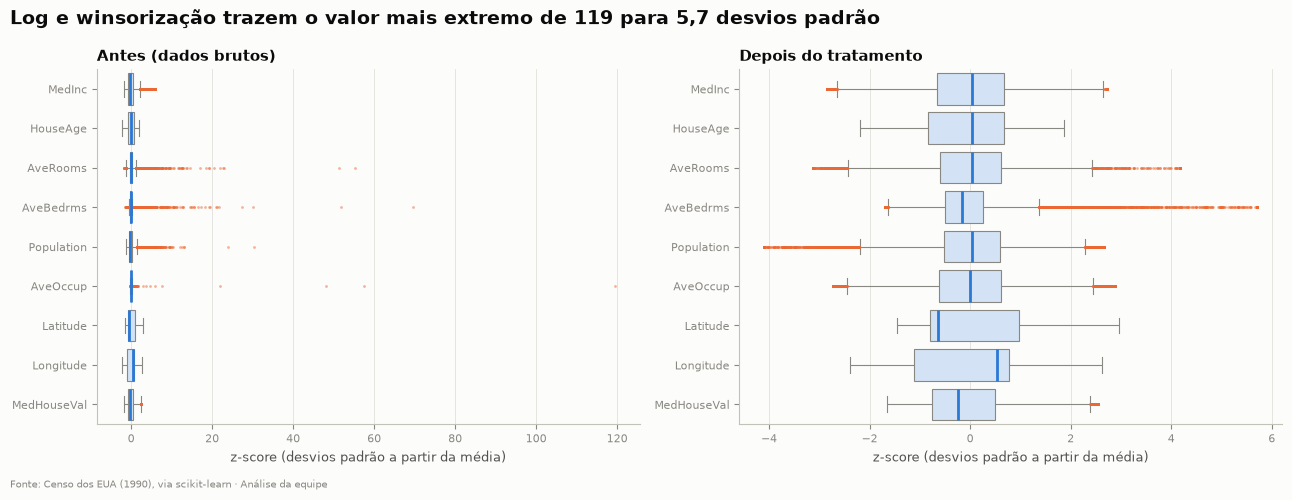

HouseAge_no_teto       1258
MedHouseVal_no_teto     959
MedInc_no_teto           45
dtype: int64

In [23]:
# Padronização simples (z-score), usada só para comparar as colunas na mesma escala
def standardize(df):
    return (df - df.mean()) / df.std()


# Boxplots de todas as colunas em z-score: antes e depois do tratamento
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, data, title in [(axes[0], standardize(df_raw), "Antes (dados brutos)"),
                        (axes[1], standardize(df_treated), "Depois do tratamento")]:
    long = data.melt(var_name="coluna", value_name="z")
    sns.boxplot(data=long, x="z", y="coluna", ax=ax, **boxplot_style())
    ax.set_title(title)
    ax.set_xlabel("z-score (desvios padrão a partir da média)")
    ax.set_ylabel("")
action_title(fig, f"Log e winsorização trazem o valor mais extremo de {br(before_after['max_z_antes'].max())} "
                  f"para {br(before_after['max_z_depois'].max(), 1)} desvios padrão")
finish(fig)

# Flags dos valores no teto, guardadas para a caracterização dos segmentos
cap_flags = pd.DataFrame({
    "HouseAge_no_teto": df_clean["HouseAge"] == df_raw["HouseAge"].max(),
    "MedHouseVal_no_teto": df_clean["MedHouseVal"] == df_raw["MedHouseVal"].max(),
    "MedInc_no_teto": df_clean["MedInc"] == df_raw["MedInc"].max(),
})
cap_flags.sum()

- **Assimetria:** caiu de 98 para 0,06 em `AveOccup`, de 21 para 0,16 em `AveRooms` e de 1,6 para −0,1 em `MedInc`.
- **Extremo máximo (|z|):** caiu de 119 desvios padrão para 2,9 em `AveOccup` e de 55 para 4,2 em `AveRooms`. Nenhuma coluna tem mais um ponto capaz de "puxar" sozinho o centro de um cluster.
- **`AveBedrms` continua com skew 2,9**, porque a sua faixa central é estreita demais. Isso reforça a decisão de não usá-la no clustering (seção 4.4).
- **Flags de teto preservadas:** 1.258 block groups com casas de 52 anos ou mais, 959 com valor de US\$ 500 mil ou mais e 45 com renda de US\$ 150 mil ou mais. Elas servem para descrever os segmentos (seção 8).

## 3.3 Normalização (scaling)

**O problema:** as colunas usam unidades muito diferentes. Numa distância, a coluna com os maiores números vence.

**Como medimos isso:** na distância euclidiana, o **peso** de cada coluna é a sua variância dividida pela soma das variâncias. O ideal é que nenhuma coluna domine *por acidente*.

In [24]:
def weight_in_distance(df):
    """Participação (%) de cada coluna na distância euclidiana média (ao quadrado) entre linhas."""
    variances = df.var()
    return 100 * variances / variances.sum()


def apply_scaler(scaler, df):
    """Ajusta um scaler e devolve um DataFrame com as mesmas colunas e índice."""
    return pd.DataFrame(scaler.fit_transform(df), columns=df.columns, index=df.index)


# Peso de cada coluna na distância: sem scaling e com cada um dos três scalers
scalers = {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
weights = pd.DataFrame({"sem scaling (brutos)": weight_in_distance(df_raw),
                        "sem scaling (tratados)": weight_in_distance(df_treated)})
for name, scaler in scalers.items():
    weights[name] = weight_in_distance(apply_scaler(scaler, df_treated))
weights.round(1)

,sem scaling (brutos),sem scaling (tratados),StandardScaler,MinMaxScaler,RobustScaler
MedInc,0.000,0.100,11.100,9.800,9.200
HouseAge,0.000,93.600,11.100,18.300,7.100
AveRooms,0.000,0.000,11.100,5.700,11.000
AveBedrms,0.000,0.000,11.100,5.500,28.800
Population,100.000,0.300,11.100,6.600,13.000
AveOccup,0.000,0.000,11.100,9.600,10.900
Latitude,0.000,2.700,11.100,15.500,5.200
Longitude,0.000,2.400,11.100,12.000,4.500
MedHouseVal,0.000,0.800,11.100,17.000,10.300


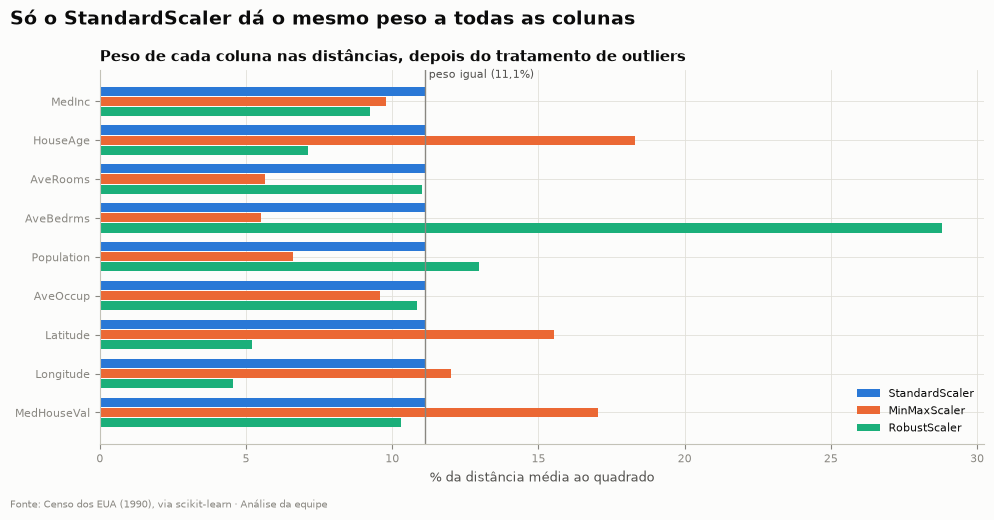

In [25]:
# Gráfico de barras com o peso de cada coluna para cada scaler
fig, ax = plt.subplots(figsize=(10, 5))
cols = df_treated.columns[::-1]
y = np.arange(len(cols))
bar_h = 0.26
for i, (name, color) in enumerate(zip(scalers, [BLUE, ORANGE, AQUA])):
    ax.barh(y + (1 - i) * bar_h, weights[name].reindex(cols), height=bar_h * 0.9, color=color, label=name)
ax.axvline(100 / len(cols), color=GRAY, linewidth=1)
ax.text(100 / len(cols), len(cols) - 0.4, " peso igual (11,1%)", color=INK_2, fontsize=8)
ax.set_yticks(y, cols)
ax.set_title("Peso de cada coluna nas distâncias, depois do tratamento de outliers")
ax.set_xlabel("% da distância média ao quadrado")
ax.legend(loc="lower right")
action_title(fig, "Só o StandardScaler dá o mesmo peso a todas as colunas")
finish(fig)

- **Sem scaling, a distância é decidida por uma única coluna:** nos dados brutos, `Population` responde por **100%** da distância (os números dela vão até 35 mil). Depois do log, `HouseAge` passa a dominar com **94%**. Nos dois casos, o algoritmo agruparia por uma só característica.
- **StandardScaler:** dá a cada coluna **exatamente o mesmo peso** (11,1%). Cada variável entra na distância por uma decisão de negócio (a seleção de features), e não pela unidade em que foi medida.
- **MinMaxScaler:** depende do mínimo e do máximo e favorece colunas com distribuição "espalhada" até os limites, como `HouseAge` (18%) e `MedHouseVal` (17%).
- **RobustScaler:** divide pelo IQR e explode a coluna de faixa central estreita (`AveBedrms` chega a 29%).

**Decisão:** usamos o **StandardScaler**, aplicado depois do tratamento de outliers. Ele funciona bem porque as colunas já estão simétricas e sem extremos.

> **Decisão** · 85 linhas removidas (0,4%), cada uma com um motivo; log e winsorização leve no restante; StandardScaler, para que cada variável pese o mesmo na distância.
>
> **Para o negócio** · Nenhum bairro real é descartado por ser extremo: casas de veraneio e bairros de luxo continuam na análise.

---
# 4. Engenharia de Features

As colunas originais nem sempre expressam as ideias que interessam ao negócio. Em clustering, isso importa ainda mais: **as features definem o que significa "parecido"**. Se queremos agrupar vizinhanças por estilo de vida, acessibilidade e localização, precisamos de colunas que meçam exatamente isso.

Todas as novas features são calculadas em **unidades naturais** (dólares, quilômetros, pessoas), sobre `df_clean`. Só depois recebem o tratamento de outliers e o scaling.

| Nova feature | Como é calculada | Pergunta de negócio que responde |
|---|---|---|
| `dist_coast_km` | distância exata até o litoral (mapa do Natural Earth) | Quanto vale a proximidade do oceano? |
| `coastal_class` | faixas de `dist_coast_km` | Classificação litoral / costeira / interior para comunicação e relatórios |
| `dist_big_city_km` | distância até a cidade mais próxima com 400 mil+ habitantes | Qual o acesso aos grandes polos de emprego? |
| `pop_density_3km` | pessoas num raio de 3 km ÷ área do círculo | O entorno é urbano, suburbano ou rural? |
| `income_per_person` | `MedInc × 10.000 ÷ AveOccup` | Renda per capita: poder de compra real de cada morador |
| `price_to_income` | `valor da casa ÷ renda anual` | Quantos anos de renda custa uma casa? (acessibilidade) |
| `rooms_per_person` | `AveRooms ÷ AveOccup` | Espaço por pessoa: conforto ou superlotação |
| `bedroom_share` | `AveBedrms ÷ AveRooms` | Tipo de imóvel: apartamentos compactos vs. casas com salas |
| `households` | `Population ÷ AveOccup` | Tamanho do mercado: quantos domicílios (clientes potenciais) |
| `income_vs_neighbors` | `log(renda ÷ renda média dos 10 vizinhos)` | O bairro é mais rico ou mais pobre que o entorno? |
| `luxury_index` | média dos percentis de renda, valor e cômodos (0 a 100) | Indicador de padrão socioeconômico / luxo |

## 4.1 Features geográficas

### Distância até a costa

Na Califórnia, estar perto do oceano significa clima ameno, praias, vista e acesso aos empregos das metrópoles litorâneas. Mas **a costa não está nos dados**: só temos latitude e longitude. Trazemos o litoral do **Natural Earth** (mapa gratuito, escala 1:10 milhões, precisão de cerca de 1 km) e medimos a distância exata de cada block group até a linha da costa, numa projeção plana em metros (`EPSG:3310`, California Albers).

In [26]:
# Tabela de trabalho das features, com condado e região de cada block group
df_feat = df_clean.copy()
df_feat[["county", "region"]] = geo.loc[df_feat.index, ["county", "region"]]

# Linha da costa do Natural Earth, recortada para a Califórnia e projetada em metros
coast_path = download(
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_10m_coastline.geojson",
    "ne_10m_coastline.geojson")
coast = gpd.clip(gpd.read_file(coast_path), box(-125.0, 32.0, -114.0, 42.5))
coast_m = coast.to_crs("EPSG:3310")


def distance_to_coast_km(lat, lon, index):
    """Distância exata (km) de cada ponto até o litoral, numa projeção plana em metros."""
    pts = gpd.GeoDataFrame(index=index, crs="EPSG:4326", geometry=gpd.points_from_xy(lon, lat)).to_crs("EPSG:3310")
    near = gpd.sjoin_nearest(pts, coast_m[["geometry"]], how="left", distance_col="distance_m")
    return near.loc[~near.index.duplicated(), "distance_m"] / 1000


df_feat["dist_coast_km"] = distance_to_coast_km(df_feat["Latitude"], df_feat["Longitude"], df_feat.index)
df_feat["dist_coast_km"].describe()

count   20,555.000
mean        39.250
std         50.185
min          0.002
25%          6.696
50%         18.868
75%         48.811
max        333.782
Name: dist_coast_km, dtype: float64

**Validação com um rótulo independente.** A versão do Kaggle deste dataset tem uma coluna `ocean_proximity`, feita à mão (`NEAR OCEAN`, `NEAR BAY`, `<1H OCEAN`, `INLAND`, `ISLAND`). Se a nossa feature estiver correta, as linhas `NEAR OCEAN` devem estar perto da costa e as `INLAND`, longe. Como os arquivos não têm ID, o join usa várias colunas que, juntas, identificam um block group.

In [27]:
# Rótulo ocean_proximity da versão do Kaggle, unido por colunas que identificam o block group
kaggle = pd.read_csv(download(
    "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv",
    "housing_kaggle.csv"))
join_keys = pd.DataFrame({
    "longitude": df_raw["Longitude"], "latitude": df_raw["Latitude"],
    "housing_median_age": df_raw["HouseAge"], "population": df_raw["Population"],
    "median_income": df_raw["MedInc"], "median_house_value": (df_raw["MedHouseVal"] * 100_000).round(),
}).loc[df_feat.index]
ocean_label = (join_keys.reset_index()
               .merge(kaggle[list(join_keys.columns) + ["ocean_proximity"]],
                      on=list(join_keys.columns), how="left", validate="one_to_one")
               .set_index("index")["ocean_proximity"])
print(f"Linhas com rótulo encontrado: {ocean_label.notna().sum():,} de {len(ocean_label):,}")

# Distância calculada (km) para cada rótulo independente
LABEL_ORDER = ["ISLAND", "NEAR OCEAN", "NEAR BAY", "<1H OCEAN", "INLAND"]
df_feat["dist_coast_km"].groupby(ocean_label).describe()[["count", "25%", "50%", "75%"]].reindex(LABEL_ORDER).round(1)

Linhas com rótulo encontrado: 20,555 de 20,555


,count,25%,50%,75%
ocean_proximity,,,,
ISLAND,5.000,0.600,0.600,1.200
NEAR OCEAN,"2,644.000",1.700,3.200,6.300
NEAR BAY,"2,280.000",2.300,3.800,5.800
<1H OCEAN,"9,116.000",11.600,17.900,25.000
INLAND,"6,510.000",51.800,79.100,140.900


**A feature confere com o rótulo independente** (todos os 20.555 block groups foram encontrados no arquivo do Kaggle):

- `ISLAND`: mediana de 0,6 km;
- `NEAR OCEAN` e `NEAR BAY`: entre 3 e 4 km;
- `<1H OCEAN`: 18 km;
- `INLAND`: 79 km.

As faixas quase não se sobrepõem, então a distância calculada mede de fato a proximidade do mar. Ela ainda é melhor que o rótulo: em vez de 5 categorias, temos uma medida contínua, em km, que distingue a primeira quadra da praia de um bairro a 20 km.

### Classificação litoral / interior

Para comunicação com as equipes comerciais, transformamos a distância em **quatro faixas**. Os limites seguem a validação acima: a mediana de `NEAR OCEAN` fica perto de 3 km, a de `<1H OCEAN` perto de 18 km e a de `INLAND` perto de 80 km.

Faixa costeira,Block groups,Valor mediano (US$ mil),Renda mediana (US$ mil)
Litoral (até 5 km),4.258,256,37
Costeira (5–25 km),8.098,205,39
Intermediária (25–80 km),4.982,163,36
Interior (> 80 km),3.217,87,26


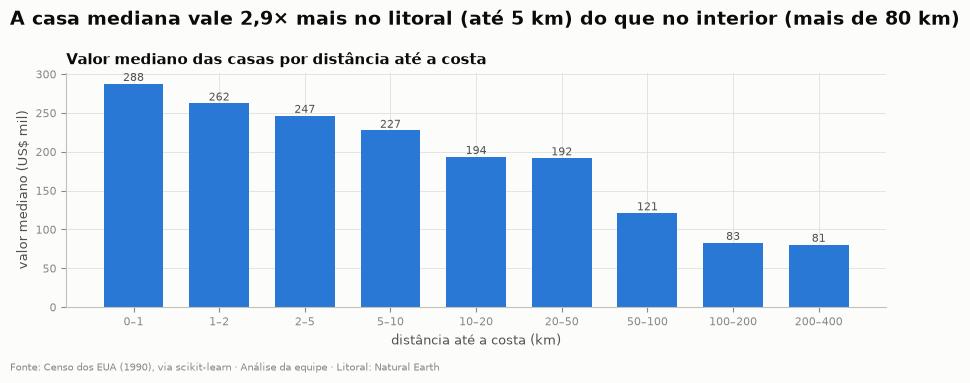

Correlação com MedHouseVal: -0.50 (usando log(1 + km))


In [28]:
# Classificação em quatro faixas de distância até a costa
COASTAL_CLASSES = ["Litoral (até 5 km)", "Costeira (5–25 km)", "Intermediária (25–80 km)", "Interior (> 80 km)"]
df_feat["coastal_class"] = pd.cut(df_feat["dist_coast_km"], bins=[-0.01, 5, 25, 80, np.inf], labels=COASTAL_CLASSES)

# Valor e renda medianos por faixa costeira
price_by_class = (df_feat.groupby("coastal_class", observed=True)
                  .agg(block_groups=("MedHouseVal", "size"),
                       valor_mediano_usd_mil=("MedHouseVal", lambda s: 100 * s.median()),
                       renda_mediana_usd_mil=("MedInc", lambda s: 10 * s.median())))
display(exec_table(price_by_class.reset_index(),
                   formats={"block_groups": "int", "valor_mediano_usd_mil": "int", "renda_mediana_usd_mil": "int"},
                   labels={"coastal_class": "Faixa costeira", "block_groups": "Block groups",
                           "valor_mediano_usd_mil": "Valor mediano (US$ mil)",
                           "renda_mediana_usd_mil": "Renda mediana (US$ mil)"},
                   highlight="valor_mediano_usd_mil"))

# Valor mediano das casas por faixa fina de distância até a costa
distance_bins = [0, 1, 2, 5, 10, 20, 50, 100, 200, 400]
value_by_distance = df_feat.groupby(pd.cut(df_feat["dist_coast_km"], distance_bins), observed=True)["MedHouseVal"].median()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(len(value_by_distance)), value_by_distance * 100, color=BLUE, width=0.7)
ax.set_xticks(range(len(value_by_distance)), [f"{b.left:g}–{b.right:g}" for b in value_by_distance.index])
for i, v in enumerate(value_by_distance * 100):
    ax.text(i, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_title("Valor mediano das casas por distância até a costa")
ax.set_xlabel("distância até a costa (km)")
ax.set_ylabel("valor mediano (US$ mil)")
coast_premium = price_by_class["valor_mediano_usd_mil"].iloc[0] / price_by_class["valor_mediano_usd_mil"].iloc[-1]
action_title(fig, f"A casa mediana vale {br(coast_premium, 1)}× mais no litoral (até 5 km) "
                  "do que no interior (mais de 80 km)")
finish(fig, SOURCE_NOTE + " · Litoral: Natural Earth")
print(f"Correlação com MedHouseVal: {np.corrcoef(np.log1p(df_feat['dist_coast_km']), df_feat['MedHouseVal'])[0, 1]:.2f} "
      "(usando log(1 + km))")

- **O preço cai continuamente com a distância do mar:**
  - litoral (até 5 km): US\$ 256 mil;
  - costeira (5 a 25 km): US\$ 205 mil;
  - intermediária (25 a 80 km): US\$ 163 mil;
  - interior (mais de 80 km): US\$ 87 mil.

  Correlação de −0,50, a segunda mais forte com o preço depois da renda.
- **A renda cai bem menos:** US\$ 37 mil, US\$ 39 mil e US\$ 36 mil nas três primeiras faixas. Ou seja, **o litoral é mais caro sem que os moradores sejam proporcionalmente mais ricos**: paga-se pela localização.

Para o negócio, `dist_coast_km` captura o principal atributo de localização da Califórnia, e faz isso sem latitude e longitude: um bairro a 3 km do mar em San Diego e outro em San Francisco ficam "próximos" nessa dimensão.

### Distância de centros urbanos, densidade e contexto de renda

- **`dist_big_city_km`:** distância até a cidade mais próxima com 400 mil+ habitantes (tabela de cidades dos EUA com coordenadas). Usamos a fórmula **haversine** (distância sobre a esfera) com uma `BallTree`.
- **`pop_density_3km`:** pessoas que moram num raio de 3 km, divididas pela área do círculo. Não temos a área de cada block group, mas conseguimos medir a densidade do **entorno**.
- **`income_vs_neighbors`:** renda do block group comparada com a média dos 10 vizinhos mais próximos (em log: > 0 = mais rico que o entorno).
- **`nearest_city`:** a cidade mais próxima (entre as 212 maiores da Califórnia), usada para **descrever** os segmentos e localizar equipes de venda.

In [29]:
# Cidades da Califórnia com população e coordenadas
ca_cities = (pd.read_csv(download("https://raw.githubusercontent.com/plotly/datasets/master/us-cities-top-1k.csv",
                                  "us_cities_top1k.csv"))
             .query("State == 'California'").reset_index(drop=True))
lat_lon_rad = np.radians(df_feat[["Latitude", "Longitude"]].to_numpy())

# Cidade de referência = a cidade mais próxima (distância haversine sobre a esfera)
city_tree = BallTree(np.radians(ca_cities[["lat", "lon"]]), metric="haversine")
df_feat["nearest_city"] = ca_cities.loc[city_tree.query(lat_lon_rad, k=1)[1][:, 0], "City"].to_numpy()

# Distância até a cidade grande (400 mil+ habitantes) mais próxima, em km
big_cities = ca_cities[ca_cities["Population"] >= 400_000]
big_city_tree = BallTree(np.radians(big_cities[["lat", "lon"]]), metric="haversine")
df_feat["dist_big_city_km"] = big_city_tree.query(lat_lon_rad, k=1)[0][:, 0] * EARTH_RADIUS_KM

# Árvore com todos os block groups para buscar vizinhos por raio
RADIUS_KM = 3
neighbour_tree = BallTree(lat_lon_rad, metric="haversine")
population = df_feat["Population"].to_numpy()


def density_3km(lat_lon_radians):
    """Pessoas por km² num raio de 3 km, usando a população de todos os block groups conhecidos."""
    nearby = neighbour_tree.query_radius(lat_lon_radians, r=RADIUS_KM / EARTH_RADIUS_KM)
    return np.array([population[idx].sum() for idx in nearby]) / (np.pi * RADIUS_KM ** 2)


# Densidade do entorno de cada block group
df_feat["pop_density_3km"] = density_3km(lat_lon_rad)

# Renda do block group comparada com a média dos 10 vizinhos mais próximos (log da razão)
nearest_idx = neighbour_tree.query(lat_lon_rad, k=11)[1][:, 1:]     # o primeiro vizinho é o próprio ponto
income = df_feat["MedInc"].to_numpy()
df_feat["income_vs_neighbors"] = np.log(income / income[nearest_idx].mean(axis=1))

print("Cidades grandes:", ", ".join(big_cities["City"]))

Cidades grandes: Sacramento, San Diego, Oakland, Long Beach, San Francisco, San Jose, Fresno, Los Angeles


## 4.2 Features socioeconômicas e de tipo de imóvel

In [30]:
# Features socioeconômicas e de tipo de imóvel (fórmulas na tabela do início da seção 4)
df_feat["income_per_person"] = df_feat["MedInc"] * 10_000 / df_feat["AveOccup"]
df_feat["price_to_income"] = (df_feat["MedHouseVal"] * 100_000) / (df_feat["MedInc"] * 10_000)
df_feat["rooms_per_person"] = df_feat["AveRooms"] / df_feat["AveOccup"]
df_feat["bedroom_share"] = df_feat["AveBedrms"] / df_feat["AveRooms"]
df_feat["households"] = df_feat["Population"] / df_feat["AveOccup"]
df_feat["luxury_index"] = 100 * df_feat[["MedInc", "MedHouseVal", "AveRooms"]].rank(pct=True).mean(axis=1)

# Resumo estatístico das 10 novas features numéricas
NEW_FEATURES = ["dist_coast_km", "dist_big_city_km", "pop_density_3km", "income_vs_neighbors",
                "income_per_person", "price_to_income", "rooms_per_person", "bedroom_share",
                "households", "luxury_index"]
df_feat[NEW_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
dist_coast_km,"20,555.000",39.250,50.185,0.002,6.696,18.868,48.811,333.782
dist_big_city_km,"20,555.000",47.142,55.836,0.346,12.143,24.880,63.312,436.610
pop_density_3km,"20,555.000","2,225.036","1,925.234",0.920,758.975,"1,862.148","3,141.064","12,855.228"
income_vs_neighbors,"20,555.000",-0.022,0.290,-2.057,-0.185,-0.004,0.158,1.626
income_per_person,"20,555.000","14,108.864","7,523.401","1,091.331","8,735.825","12,978.203","17,769.594","75,498.363"
price_to_income,"20,555.000",5.631,3.062,0.358,3.860,4.950,6.587,100.020
rooms_per_person,"20,555.000",1.978,1.110,0.312,1.526,1.940,2.296,55.222
bedroom_share,"20,555.000",0.213,0.057,0.105,0.175,0.203,0.240,1.000
households,"20,555.000",501.367,382.011,10.000,281.000,410.000,606.000,"6,082.000"
luxury_index,"20,555.000",50.002,23.915,0.141,30.933,48.133,68.412,98.910


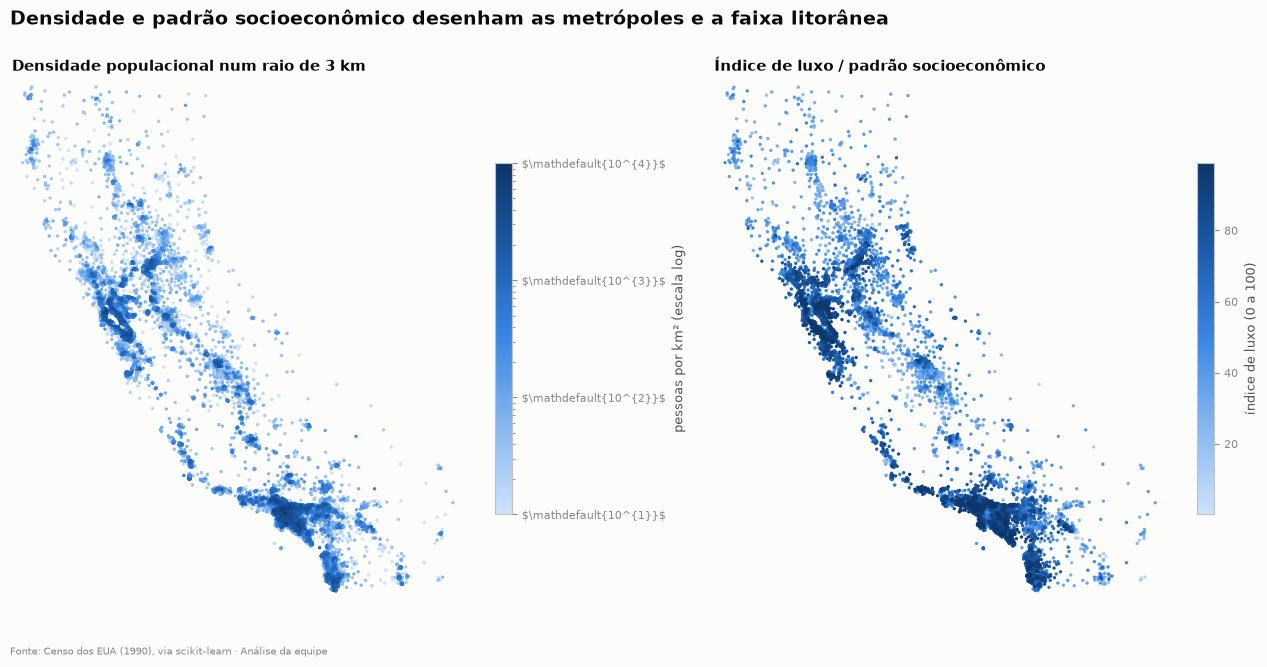

In [31]:
# Mapa da densidade (escala log) e mapa do índice de luxo
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
points = axes[0].scatter(df_feat["Longitude"], df_feat["Latitude"], c=df_feat["pop_density_3km"].clip(lower=10),
                         cmap=BLUES, norm=LogNorm(vmin=10, vmax=10_000), s=2)
fig.colorbar(points, ax=axes[0], shrink=0.6, label="pessoas por km² (escala log)")
style_map(axes[0], "Densidade populacional num raio de 3 km")

order = df_feat["luxury_index"].sort_values().index
points = axes[1].scatter(df_feat.loc[order, "Longitude"], df_feat.loc[order, "Latitude"],
                         c=df_feat.loc[order, "luxury_index"], cmap=BLUES, s=2)
fig.colorbar(points, ax=axes[1], shrink=0.6, label="índice de luxo (0 a 100)")
style_map(axes[1], "Índice de luxo / padrão socioeconômico")
action_title(fig, "Densidade e padrão socioeconômico desenham as metrópoles e a faixa litorânea")
finish(fig)

- **Densidade do entorno:** a mediana é de 1.862 pessoas/km², mas vai de menos de 1 (áreas rurais) a quase 13 mil (centros de Los Angeles e San Francisco). No mapa, as manchas escuras desenham exatamente as regiões metropolitanas.
- **Anos de renda por casa:** na mediana, uma casa custa **5 anos** de renda do bairro. Valores acima de 10 indicam bairros caros para quem mora neles: mercado de investidores ou de compradores de fora.
- **Renda per capita:** mediana de US\$ 13 mil por pessoa. É uma medida melhor do poder de compra que a renda do domicílio, porque considera o tamanho da família.
- **Índice de luxo:** a faixa litorânea de alto padrão aparece claramente no mapa, com algumas manchas altas também no interior, como nos subúrbios de Sacramento.

## 4.3 Tratamento das novas features

As novas features também têm caudas longas e extremos (por exemplo, `rooms_per_person` nas casas de veraneio). Aplicamos a mesma lógica da seção 3.2: winsorização nos percentis 0,5% / 99,5% e a transformação que deixa cada coluna mais simétrica (log, `log(1 + x)` para distâncias que podem ser zero, ou raiz quadrada para a densidade, em que o log corrige demais).

In [32]:
# Winsorização e transformação escolhidas para cada nova feature
NEW_TREATMENT = {
    "dist_coast_km":       {"clip_pct": None, "transform": "log1p"},
    "dist_big_city_km":    {"clip_pct": None, "transform": "log1p"},
    "pop_density_3km":     {"clip_pct": 0.5, "transform": "sqrt"},
    "income_vs_neighbors": {"clip_pct": 0.5, "transform": None},
    "income_per_person":   {"clip_pct": 0.5, "transform": "log"},
    "price_to_income":     {"clip_pct": 0.5, "transform": "log"},
    "rooms_per_person":    {"clip_pct": 0.5, "transform": "log"},
    "bedroom_share":       {"clip_pct": 0.5, "transform": "log"},
    "households":          {"clip_pct": 0.5, "transform": "log"},
    "luxury_index":        {"clip_pct": None, "transform": None},
}
NEW_CLIP_LIMITS = {col: tuple(df_feat[col].quantile([rule["clip_pct"] / 100, 1 - rule["clip_pct"] / 100]))
                   for col, rule in NEW_TREATMENT.items() if rule["clip_pct"] is not None}
TRANSFORMS = {"log": np.log, "log1p": np.log1p, "sqrt": np.sqrt}


def treat_new_features(df):
    """Aplica a winsorização e a transformação escolhidas às novas features presentes em df."""
    out = df.copy()
    for col in out.columns.intersection(list(NEW_TREATMENT)):
        if col in NEW_CLIP_LIMITS:
            out[col] = out[col].clip(*NEW_CLIP_LIMITS[col])
        if NEW_TREATMENT[col]["transform"]:
            out[col] = TRANSFORMS[NEW_TREATMENT[col]["transform"]](out[col])
    return out


# Assimetria e extremos das novas features antes e depois do tratamento
treated_new = treat_new_features(df_feat[NEW_FEATURES])
pd.DataFrame({
    "transformação": [NEW_TREATMENT[c]["transform"] or "-" for c in NEW_FEATURES],
    "skew_antes": df_feat[NEW_FEATURES].skew(),
    "skew_depois": treated_new.skew(),
    "max_z_antes": [max_abs_z(df_feat[c]) for c in NEW_FEATURES],
    "max_z_depois": [max_abs_z(treated_new[c]) for c in NEW_FEATURES],
}).round(2)

,transformação,skew_antes,skew_depois,max_z_antes,max_z_depois
dist_coast_km,log1p,1.930,-0.050,5.870,2.350
dist_big_city_km,log1p,2.490,0.020,6.980,2.840
pop_density_3km,sqrt,1.410,0.080,5.520,2.710
income_vs_neighbors,-,-0.430,-0.340,7.010,3.370
income_per_person,log,1.460,-0.320,8.160,2.780
price_to_income,log,5.330,0.400,30.820,3.230
rooms_per_person,log,17.450,-0.450,47.950,3.470
bedroom_share,log,2.070,0.390,13.720,3.330
households,log,3.430,-0.660,14.610,4.100
luxury_index,-,0.180,0.180,2.080,2.080


- **Todas as novas features ficaram quase simétricas** (|skew| ≤ 0,66) **e sem extremos** (|z| máximo ≤ 4,1).
- **Os casos mais graves foram resolvidos:**
  - `rooms_per_person` caiu de skew 17,5 para −0,45 (casas de veraneio);
  - `price_to_income` caiu de 5,3 para 0,4 (bairros com renda muito baixa e preço alto).
- **Mesma lógica das colunas originais.** As novas features passam pelo mesmo tratamento, então nenhuma delas vai dominar a distância só por ter números grandes.

## 4.4 Análise de correlação e seleção de features para a clusterização

Usar todas as colunas seria um erro:

- **Contagem dupla:** se três colunas dizem a mesma coisa, essa ideia ganha três vezes o peso nas distâncias, sem ninguém ter decidido isso.
- **Maldição da dimensionalidade:** com muitas colunas, todas as vizinhanças parecem igualmente distantes e os clusters ficam difusos.
- **Interpretação:** um segmento descrito por 7 variáveis claras é fácil de explicar a um gestor; com 20, não é.

Seguimos três filtros:

1. **Objetivo de negócio:** queremos *tipos* de vizinhança, não regiões do mapa. Por isso **latitude, longitude, condado e região ficam fora** do clustering e são usados depois, para descrever e mapear os segmentos. O *significado* da localização entra pelas features `dist_coast_km`, `pop_density_3km` e `dist_big_city_km`.
2. **Redundância entre pares:** correlação de Spearman (pega também relações curvas) e um dendrograma de colunas. Colunas com |correlação| ≥ 0,8 dizem a mesma coisa.
3. **Redundância em combinação:** o **VIF** (Variance Inflation Factor) mede o quanto cada coluna pode ser reconstruída pelas outras juntas. VIF acima de 10 indica uma coluna quase redundante.

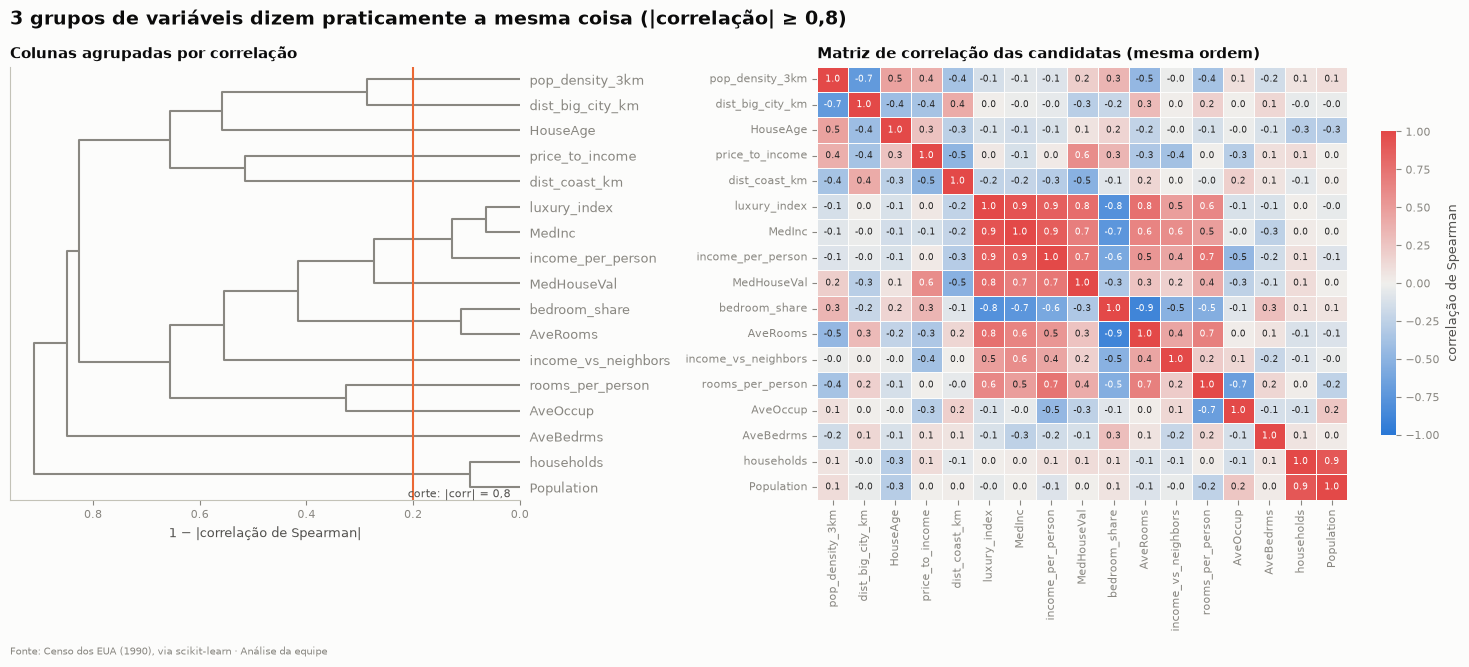

['Population', 'households']  ->  |corr| entre 0.91 e 0.91
['AveRooms', 'bedroom_share']  ->  |corr| entre 0.89 e 0.89
['MedInc', 'income_per_person', 'luxury_index']  ->  |corr| entre 0.86 e 0.94


In [33]:
# Candidatas à clusterização: originais (sem coordenadas) + novas, tratadas e padronizadas
ORIGINAL_CANDIDATES = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "MedHouseVal"]
CANDIDATES = ORIGINAL_CANDIDATES + NEW_FEATURES
X_candidates = pd.concat([treat_outliers(df_feat[df_clean.columns])[ORIGINAL_CANDIDATES],
                          treat_new_features(df_feat[NEW_FEATURES])], axis=1)
Z_candidates = apply_scaler(StandardScaler(), X_candidates)

# Correlação de Spearman e dendrograma das colunas (distância = 1 - |correlação|)
spearman = Z_candidates.corr(method="spearman")
column_links = linkage(squareform((1 - spearman.abs()).to_numpy(), checks=False), method="average")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.3]})
tree = dendrogram(column_links, labels=CANDIDATES, orientation="left", ax=axes[0], leaf_font_size=9,
                  color_threshold=0, above_threshold_color=GRAY)
axes[0].axvline(0.2, color=ORANGE, linewidth=1.5)
axes[0].text(0.21, 1, "corte: |corr| = 0,8", color=INK_2, fontsize=8)
axes[0].set_title("Colunas agrupadas por correlação")
axes[0].set_xlabel("1 − |correlação de Spearman|")
axes[0].grid(False)
order = tree["ivl"][::-1]
sns.heatmap(spearman.loc[order, order], cmap=DIVERGING, vmin=-1, vmax=1, ax=axes[1], annot=True, fmt=".1f",
            annot_kws={"fontsize": 6.5}, linewidths=0.5, linecolor=SURFACE,
            cbar_kws={"shrink": 0.7, "label": "correlação de Spearman"})
axes[1].set_title("Matriz de correlação das candidatas (mesma ordem)")
n_redundant = int((pd.Series(fcluster(column_links, t=0.2, criterion="distance")).value_counts() > 1).sum())
action_title(fig, f"{n_redundant} grupos de variáveis dizem praticamente a mesma coisa (|correlação| ≥ 0,8)")
finish(fig)

# Grupos de colunas redundantes: |correlação| >= 0,8 (corte em 0,2 no dendrograma)
groups = pd.Series(fcluster(column_links, t=0.2, criterion="distance"), index=CANDIDATES)
for _, members in groups.groupby(groups):
    if len(members) > 1:
        names = list(members.index)
        values = spearman.loc[names, names].abs().to_numpy()[np.triu_indices(len(names), 1)]
        print(f"{names}  ->  |corr| entre {values.min():.2f} e {values.max():.2f}")

**Três grupos de colunas redundantes** (|correlação| ≥ 0,8):

| Grupo | Correlação | Quem fica e por quê |
|---|---|---|
| `Population` e `households` | 0,91 | os dois medem o tamanho do block group; nenhum entra (ver VIF e decisão abaixo) |
| `AveRooms` e `bedroom_share` | 0,89 | `AveRooms` fica: "tamanho da moradia" é mais fácil de explicar |
| `MedInc`, `income_per_person` e `luxury_index` | 0,86 a 0,94 | `MedInc` fica: é o dado original; os outros dois são derivados dele |

Removemos `households`, `bedroom_share` e `luxury_index` desta etapa. A matriz também mostra que `dist_big_city_km` e `pop_density_3km` andam juntas (−0,7): perto das grandes cidades, o entorno é denso. O dendrograma também mostra que **`MedHouseVal` fica perto do grupo da renda, mas não dentro dele**: o preço traz informação própria (a localização), o que confirma a análise da seção 2.

In [34]:
def vif(Z):
    """VIF de cada coluna: 1 / (1 - R²) da regressão dessa coluna sobre todas as outras."""
    result = {}
    for col in Z.columns:
        others = Z.drop(columns=col)
        r2 = LinearRegression().fit(others, Z[col]).score(others, Z[col])
        result[col] = 1 / (1 - r2)
    return pd.Series(result, name="VIF").sort_values(ascending=False)


# VIF das candidatas que sobraram depois de remover as redundâncias entre pares
after_pairs = [c for c in CANDIDATES if c not in ["households", "bedroom_share", "luxury_index"]]
vif(Z_candidates[after_pairs]).round(1)

income_per_person     539.600
MedInc                404.700
rooms_per_person      287.600
AveOccup              160.300
AveRooms              151.700
MedHouseVal            10.600
price_to_income         7.400
pop_density_3km         2.800
dist_big_city_km        2.200
income_vs_neighbors     2.200
dist_coast_km           1.800
AveBedrms               1.800
HouseAge                1.700
Population              1.300
Name: VIF, dtype: float64

- **`income_per_person` (540) e `rooms_per_person` (288) têm VIF enorme.** Com o log, eles são exatamente `log(MedInc) − log(AveOccup)` e `log(AveRooms) − log(AveOccup)`: não trazem nada que as colunas originais já não tenham.
- **Esses dois puxam os VIFs de `MedInc`, `AveOccup` e `AveRooms` para cima.** Ao removê-los, os VIFs das três voltam a valores baixos (ver a próxima célula).
- **`price_to_income` (7,4) e `MedHouseVal` (10,6) se explicam mutuamente:** a razão entre preço e renda é quase reconstruída pelas duas colunas originais.
- **Todas as demais têm VIF abaixo de 3:** informação própria.

In [35]:
# Decisão final (manter/remover) e o motivo de negócio para cada candidata
DECISIONS = {
    "MedInc":              ("manter", "renda dos moradores: o centro do eixo de riqueza"),
    "MedHouseVal":         ("manter", "nível de preço: a variável central para o negócio"),
    "HouseAge":            ("manter", "idade do estoque de imóveis: informação única"),
    "AveRooms":            ("manter", "tamanho da moradia: casas vs. apartamentos"),
    "AveOccup":            ("manter", "tamanho do domicílio: famílias vs. pessoas sozinhas"),
    "dist_coast_km":       ("manter", "proximidade do oceano: principal motor de preço na Califórnia"),
    "pop_density_3km":     ("manter", "entorno urbano vs. rural"),
    "AveBedrms":           ("remover", "quase constante e coberta por AveRooms"),
    "Population":          ("remover", "tamanho do block group é um artefato do Censo, não um perfil de bairro"),
    "dist_big_city_km":    ("remover", "sobreposta à densidade; mantida para descrição"),
    "income_vs_neighbors": ("remover", "contraste local, não um perfil de bairro; mantida para descrição"),
    "income_per_person":   ("remover", "combinação de MedInc e AveOccup (VIF); mantida para descrição"),
    "price_to_income":     ("remover", "combinação de MedHouseVal e MedInc (VIF); mantida para descrição"),
    "rooms_per_person":    ("remover", "combinação de AveRooms e AveOccup (VIF)"),
    "bedroom_share":       ("remover", "quase duplicata de AveRooms"),
    "households":          ("remover", "quase duplicata de Population"),
    "luxury_index":        ("remover", "resume renda, valor e cômodos (contagem dupla); usado para descrição"),
}

FINAL_FEATURES = [c for c in CANDIDATES if DECISIONS[c][0] == "manter"]
selection = pd.DataFrame(DECISIONS, index=["decisão", "motivo"]).T.reindex(CANDIDATES)
print(f"VIF máximo das features finais: {vif(Z_candidates[FINAL_FEATURES]).max():.1f}")
print(f"Features finais ({len(FINAL_FEATURES)}): {FINAL_FEATURES}")
selection.sort_values("decisão", ascending=False)

VIF máximo das features finais: 2.9
Features finais (7): ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup', 'MedHouseVal', 'dist_coast_km', 'pop_density_3km']


,decisão,motivo
dist_big_city_km,remover,sobreposta à densidade; mantida para descrição
income_vs_neighbors,remover,"contraste local, não um perfil de bairro; mant..."
households,remover,quase duplicata de Population
bedroom_share,remover,quase duplicata de AveRooms
rooms_per_person,remover,combinação de AveRooms e AveOccup (VIF)
price_to_income,remover,combinação de MedHouseVal e MedInc (VIF); mant...
income_per_person,remover,combinação de MedInc e AveOccup (VIF); mantida...
luxury_index,remover,"resume renda, valor e cômodos (contagem dupla)..."
Population,remover,"tamanho do block group é um artefato do Censo,..."
AveBedrms,remover,quase constante e coberta por AveRooms


**As 7 features finais**, com VIF máximo de 2,9 (nenhuma redundância relevante), cobrem quatro dimensões de negócio:

| Dimensão | Features |
|---|---|
| **Poder aquisitivo e preço** | `MedInc` (renda) e `MedHouseVal` (valor das casas) |
| **Tipo de moradia** | `AveRooms` (tamanho) e `HouseAge` (idade do estoque) |
| **Perfil do domicílio** | `AveOccup` (pessoas por domicílio: famílias vs. solteiros e casais) |
| **Localização (sem coordenadas)** | `dist_coast_km` (proximidade do mar) e `pop_density_3km` (urbano vs. rural) |

As features que ficaram de fora **não são descartadas**. `income_per_person`, `price_to_income`, `luxury_index`, `dist_big_city_km` e `income_vs_neighbors` voltam na seção 8 para **descrever** os segmentos, sem influenciar a formação deles.

> **Insight** · A proximidade do mar é o segundo maior motor de preço, depois da renda (correlação de −0,50).
>
> **Decisão** · 7 variáveis finais, sem redundância (VIF máximo de 2,9), cobrindo poder aquisitivo, moradia, perfil da família e localização.
>
> **Para o negócio** · Cada segmento será descrito em variáveis que a equipe comercial entende.

In [36]:
# Matriz final: as 7 features tratadas e padronizadas (média 0, desvio padrão 1)
X_final = X_candidates[FINAL_FEATURES]
final_scaler = StandardScaler().fit(X_final)
Z = pd.DataFrame(final_scaler.transform(X_final), columns=FINAL_FEATURES, index=X_final.index)
print(f"Matriz para a clusterização: {Z.shape[0]:,} block groups x {Z.shape[1]} features padronizadas")
Z.describe().T[["mean", "std", "min", "max"]].round(2)

Matriz para a clusterização: 20,555 block groups x 7 features padronizadas


,mean,std,min,max
MedInc,0.000,1.000,-2.840,2.710
HouseAge,-0.000,1.000,-2.200,1.860
AveRooms,-0.000,1.000,-3.130,4.180
AveOccup,-0.000,1.000,-2.730,2.880
MedHouseVal,0.000,1.000,-1.660,2.540
dist_coast_km,-0.000,1.000,-2.350,2.240
pop_density_3km,-0.000,1.000,-1.880,2.710


---
# 5. Redução de Dimensionalidade (PCA)

O **PCA** (Análise de Componentes Principais) constrói novos eixos, os componentes, que resumem as colunas. O primeiro componente captura a maior parte da variação, o segundo a maior parte do que sobrou, e assim por diante. Os **loadings** mostram quais colunas constroem cada componente, ou seja, o que cada "dimensão do mercado" significa.

Usamos o PCA para duas coisas: (1) entender quantas dimensões reais o mercado tem; (2) **visualizar** os clusters em 2D e 3D (seção 7).

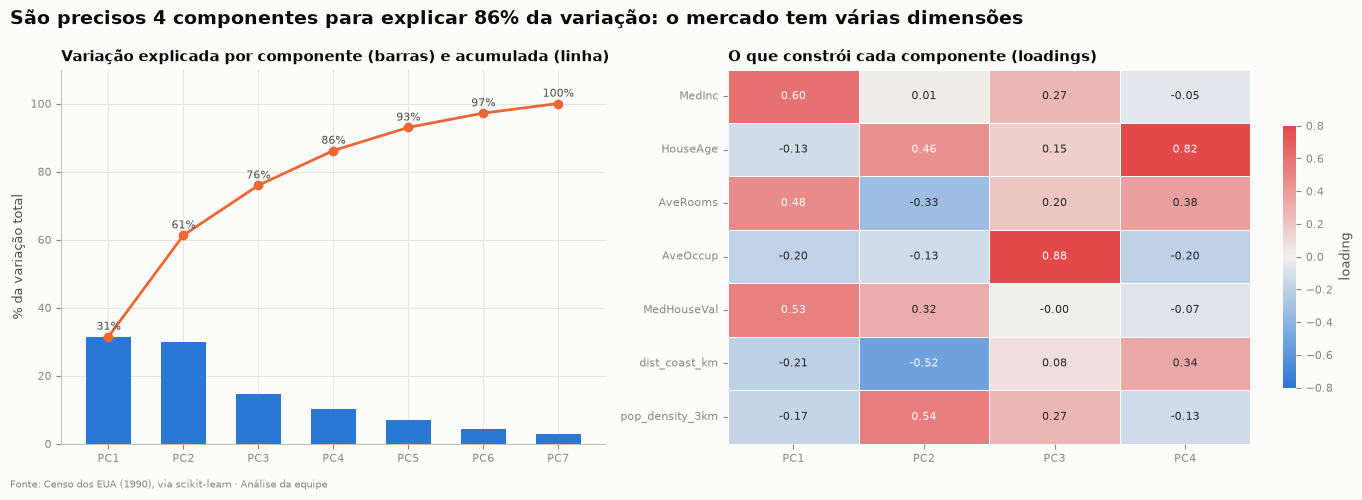

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
variancia_explicada_pct,31.500,29.800,14.700,10.200,6.800,4.200,2.800
acumulada_pct,31.500,61.300,76.000,86.200,93.000,97.200,100.000


In [37]:
# PCA com todos os componentes: variância explicada e loadings (peso de cada feature)
pca = PCA(random_state=RANDOM_STATE).fit(Z)
explained = pd.DataFrame({"variancia_explicada_pct": 100 * pca.explained_variance_ratio_,
                          "acumulada_pct": 100 * np.cumsum(pca.explained_variance_ratio_)},
                         index=[f"PC{i + 1}" for i in range(Z.shape[1])])
loadings = pd.DataFrame(pca.components_.T, index=FINAL_FEATURES, columns=explained.index)

# Variância explicada (barras e acumulada) e mapa de calor dos loadings dos 4 primeiros componentes
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].bar(explained.index, explained["variancia_explicada_pct"], color=BLUE, width=0.6)
axes[0].plot(explained.index, explained["acumulada_pct"], marker="o", color=ORANGE, linewidth=2)
for i, v in enumerate(explained["acumulada_pct"]):
    axes[0].text(i, v + 2, f"{v:.0f}%", ha="center", fontsize=8, color=INK_2)
axes[0].set_title("Variação explicada por componente (barras) e acumulada (linha)")
axes[0].set_ylabel("% da variação total")
axes[0].set_ylim(0, 110)
sns.heatmap(loadings.iloc[:, :4], cmap=DIVERGING, vmin=-0.8, vmax=0.8, annot=True, fmt=".2f", ax=axes[1],
            annot_kws={"fontsize": 8}, linewidths=0.5, linecolor=SURFACE,
            cbar_kws={"shrink": 0.7, "label": "loading"})
axes[1].set_title("O que constrói cada componente (loadings)")
n_for_85 = int((explained["acumulada_pct"] < 85).sum() + 1)
action_title(fig, f"São precisos {n_for_85} componentes para explicar "
                  f"{br(explained['acumulada_pct'].iloc[n_for_85 - 1])}% da variação: o mercado tem várias dimensões")
finish(fig)
explained.round(1).T

**As quatro dimensões do mercado** (as quatro primeiras somam 86% da variação):

| Componente | Variação | O que mede (maiores loadings) | Leitura de negócio |
|---|---|---|---|
| **PC1** | 31% | renda (+0,60), valor (+0,53) e cômodos (+0,48) | **Riqueza e padrão**: bairros ricos, caros e com casas grandes |
| **PC2** | 30% | densidade (+0,54), idade (+0,46) e valor (+0,32) vs. distância da costa (−0,52) e cômodos (−0,33) | **Urbano consolidado vs. periferia**: centros antigos, densos e perto do mar vs. áreas novas e espaçosas no interior |
| **PC3** | 15% | pessoas por domicílio (+0,88) | **Tamanho da família** |
| **PC4** | 10% | idade das casas (+0,82) | **Idade do estoque** |

**Decisão:** os dois primeiros componentes explicam só 61% da variação, e são precisos 4 dos 7 para chegar a 86%. **O mercado tem várias dimensões independentes**: não dá para resumi-lo a um eixo "rico vs. pobre".

Por isso, **clusterizamos sobre as 7 features padronizadas**, e não sobre os componentes. Assim, cada segmento continua descrito em variáveis que um gestor entende. O PCA serve para **visualizar** os clusters (seção 7.5).

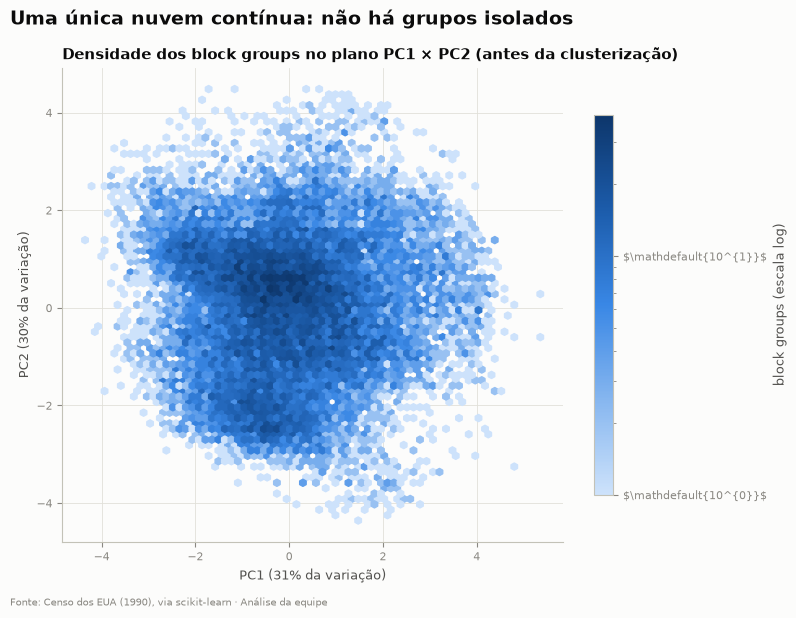

In [38]:
# Coordenadas de cada block group nos 3 primeiros componentes; densidade de pontos no plano PC1 x PC2
pcs = pd.DataFrame(pca.transform(Z)[:, :3], columns=["PC1", "PC2", "PC3"], index=Z.index)
fig, ax = plt.subplots(figsize=(8, 6))
hb = ax.hexbin(pcs["PC1"], pcs["PC2"], gridsize=70, cmap=BLUES, bins="log", mincnt=1)
fig.colorbar(hb, ax=ax, shrink=0.8, label="block groups (escala log)")
ax.set_title("Densidade dos block groups no plano PC1 × PC2 (antes da clusterização)")
ax.set_xlabel(f"PC1 ({explained.iloc[0, 0]:.0f}% da variação)")
ax.set_ylabel(f"PC2 ({explained.iloc[1, 0]:.0f}% da variação)")
action_title(fig, "Uma única nuvem contínua: não há grupos isolados")
finish(fig)

A nuvem é **uma única massa contínua**, mais densa no centro, sem "ilhas" separadas por espaços vazios. Isso já antecipa uma característica importante: **o mercado imobiliário é um contínuo.** Os bairros vão mudando gradualmente de perfil, sem fronteiras naturais nítidas.

Para o clustering, isso significa que os segmentos serão **partições úteis de um contínuo**, e não grupos isolados. Por isso:

- esperamos valores **moderados** de silhouette;
- algoritmos de densidade, como o DBSCAN, devem ter dificuldade;
- a qualidade da segmentação deve ser julgada também pela **estabilidade** e pela **utilidade para o negócio**.

> **Insight** · O mercado tem pelo menos quatro dimensões independentes (riqueza, urbano vs. periferia, tamanho da família e idade do estoque) e forma uma nuvem contínua, sem grupos isolados.
>
> **Decisão** · Clusterizar sobre as 7 variáveis originais, para manter a interpretação; o PCA fica para a visualização.

---
# 6. Implementação dos Algoritmos de Clusterização

## 6.1 Quais algoritmos e por quê

Testamos quatro famílias de algoritmos. Cada uma faz uma suposição diferente sobre o que é um "grupo", e cada uma entrega algo diferente para o negócio:

| Algoritmo | O que é um grupo para ele | O que entrega ao negócio | Risco neste problema |
|---|---|---|---|
| **K-Means** | pontos próximos de um centro (grupos compactos) | um **perfil médio** (centróide) por segmento, fácil de virar persona; todo block group recebe um segmento; classifica novos block groups instantaneamente | supõe grupos de tamanho e formato parecidos |
| **Gaussian Mixture (GMM)** | nuvens elípticas com probabilidades | **probabilidade** de pertencer a cada segmento: identifica bairros "em transição" | mais parâmetros; pode ficar instável |
| **Hierárquico (Ward)** | grupos que se unem passo a passo | uma **árvore** de segmentos: macro-segmentos e subsegmentos | custo alto (usamos amostra) |
| **DBSCAN** | regiões densas separadas por regiões vazias | encontra grupos de formato livre e marca **ruído** (atípicos) | se o mercado for contínuo, vira um grande grupo + ruído |

Começamos pelo K-Means (o candidato natural para segmentação de mercado), escolhendo o número de clusters com o **método do cotovelo**, a **silhouette** e outros critérios. Depois testamos os demais e comparamos todos na seção 6.6.

## 6.2 K-Means: escolhendo o número de clusters (k)

Para cada k de 2 a 12 calculamos:

- **Inércia** (soma das distâncias ao quadrado até o centro): cai sempre com k; procuramos o **cotovelo**, onde ganhar mais um cluster passa a valer pouco;
- **Silhouette** (−1 a 1, maior é melhor): compara a distância até o próprio cluster com a distância até o cluster vizinho;
- **Davies-Bouldin** (menor é melhor): razão entre dispersão interna e separação entre clusters;
- **Calinski-Harabasz** (maior é melhor): razão entre a variação *entre* clusters e *dentro* deles;
- **Estabilidade por bootstrap** (técnica avançada de validação): reamostramos os dados com reposição 15 vezes, refazemos o K-Means e medimos com o **ARI** (Adjusted Rand Index, 1 = mesma segmentação) se os segmentos se repetem. Uma segmentação que muda a cada amostra não serve para orientar uma estratégia.

In [39]:
K_RANGE = range(2, 13)
kmeans_models, rows = {}, []
for k in K_RANGE:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    kmeans_models[k] = model
    rows.append({"k": k, "inercia": model.inertia_,
                 "silhouette": silhouette_score(Z, model.labels_, sample_size=10_000, random_state=RANDOM_STATE),
                 "davies_bouldin": davies_bouldin_score(Z, model.labels_),
                 "calinski_harabasz": calinski_harabasz_score(Z, model.labels_),
                 "menor_cluster_pct": 100 * np.bincount(model.labels_).min() / len(Z)})
k_scores = pd.DataFrame(rows).set_index("k")

rng = np.random.default_rng(RANDOM_STATE)
N_BOOT = 15
for k in K_RANGE:
    aris = []
    for b in range(N_BOOT):
        idx = rng.choice(len(Z), size=len(Z), replace=True)
        boot = KMeans(n_clusters=k, n_init=3, random_state=b).fit(Z.iloc[idx])
        aris.append(adjusted_rand_score(kmeans_models[k].labels_, boot.predict(Z)))
    k_scores.loc[k, "estabilidade_ARI"] = np.mean(aris)
    k_scores.loc[k, "estabilidade_ARI_min"] = np.min(aris)


def elbow_point(x, y):
    """Cotovelo: o ponto da curva mais distante da reta que liga o primeiro ao último ponto."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    xn, yn = (x - x.min()) / np.ptp(x), (y - y.min()) / np.ptp(y)
    distance = np.abs((yn[-1] - yn[0]) * xn - (xn[-1] - xn[0]) * yn + xn[-1] * yn[0] - yn[-1] * xn[0])
    return int(np.argmax(distance))


elbow_k = list(K_RANGE)[elbow_point(list(K_RANGE), k_scores["inercia"])]
print(f"Cotovelo da inércia: k = {elbow_k}")
exec_table(k_scores.reset_index(),
           formats={"k": "int", "inercia": "int", "silhouette": "dec3", "davies_bouldin": "dec3",
                    "calinski_harabasz": "int", "menor_cluster_pct": "pct", "estabilidade_ARI": "dec3",
                    "estabilidade_ARI_min": "dec3"},
           labels={"inercia": "Inércia", "silhouette": "Silhouette", "davies_bouldin": "Davies-Bouldin",
                   "calinski_harabasz": "Calinski-Harabasz", "menor_cluster_pct": "Menor segmento",
                   "estabilidade_ARI": "Estabilidade (ARI médio)", "estabilidade_ARI_min": "ARI mínimo"},
           highlight="estabilidade_ARI")

Cotovelo da inércia: k = 5


k,Inércia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Menor segmento,Estabilidade (ARI médio),ARI mínimo
2,114.465,"0,189","1,846",5.283,"42,9%","0,646","0,000"
3,91.754,"0,210","1,505",5.838,"31,2%","0,947","0,890"
4,80.807,"0,204","1,525",5.347,"23,1%","0,960","0,927"
5,74.278,"0,186","1,524",4.814,"12,0%","0,873","0,568"
6,68.854,"0,184","1,528",4.479,"11,1%","0,923","0,877"
7,64.689,"0,175","1,461",4.193,"9,5%","0,852","0,596"
8,61.332,"0,165","1,505",3.951,"8,8%","0,835","0,517"
9,58.974,"0,163","1,537",3.698,"7,6%","0,737","0,574"
10,56.892,"0,154","1,538",3.491,"7,1%","0,732","0,587"
11,54.965,"0,164","1,517",3.324,"1,3%","0,678","0,565"


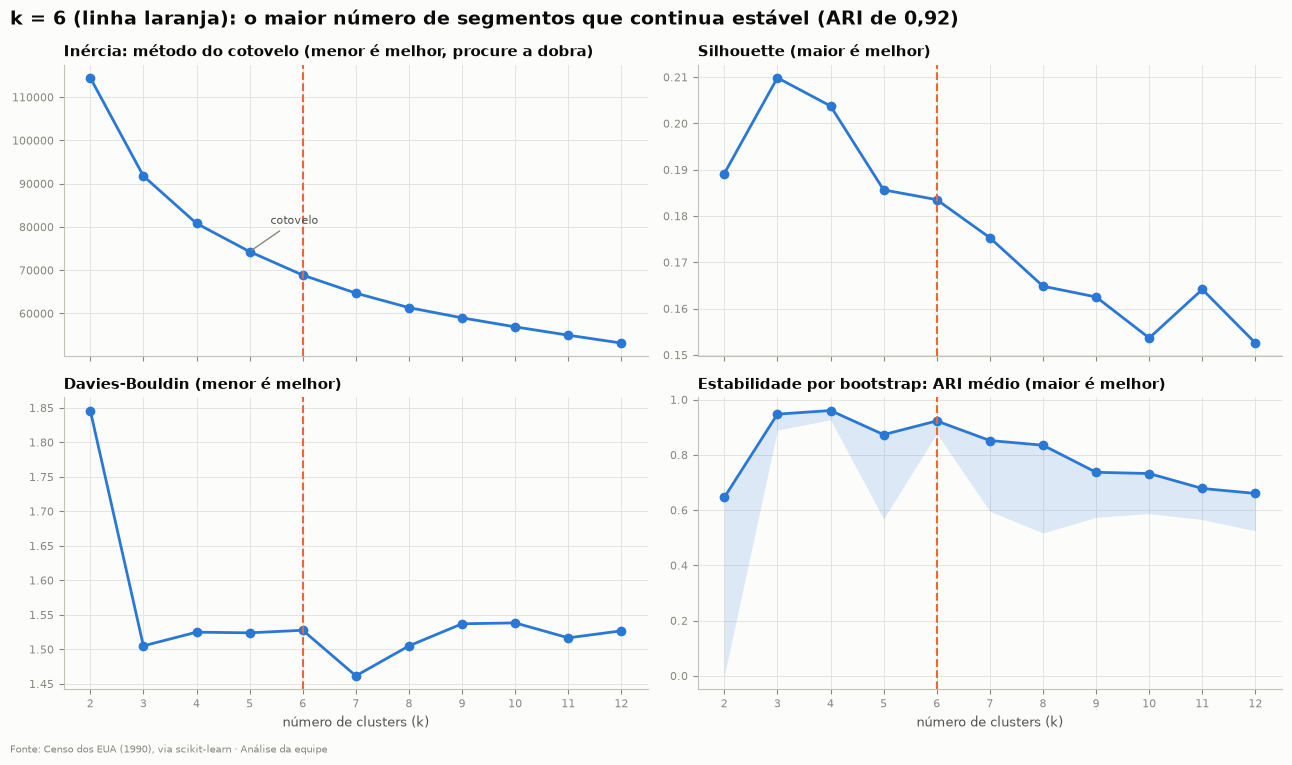

In [40]:
K_FINAL = 6   # número de segmentos escolhido (justificativa logo abaixo)

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
panels = [(axes[0, 0], "inercia", "Inércia: método do cotovelo (menor é melhor, procure a dobra)"),
          (axes[0, 1], "silhouette", "Silhouette (maior é melhor)"),
          (axes[1, 0], "davies_bouldin", "Davies-Bouldin (menor é melhor)"),
          (axes[1, 1], "estabilidade_ARI", "Estabilidade por bootstrap: ARI médio (maior é melhor)")]
for ax, col, title in panels:
    ax.plot(k_scores.index, k_scores[col], marker="o", markersize=6, linewidth=2, color=BLUE)
    ax.axvline(K_FINAL, color=ORANGE, linewidth=1.5, linestyle="--")
    ax.set_title(title)
axes[0, 0].annotate("cotovelo", (elbow_k, k_scores.loc[elbow_k, "inercia"]), xytext=(15, 20),
                    textcoords="offset points", fontsize=8, color=INK_2, arrowprops={"arrowstyle": "-", "color": GRAY})
axes[1, 1].fill_between(k_scores.index, k_scores["estabilidade_ARI_min"], k_scores["estabilidade_ARI"],
                        color=BLUE, alpha=0.15, linewidth=0)
for ax in axes[1]:
    ax.set_xlabel("número de clusters (k)")
    ax.set_xticks(list(K_RANGE))
action_title(fig, f"k = {K_FINAL} (linha laranja): o maior número de segmentos que continua estável "
                  f"(ARI de {br(k_scores.loc[K_FINAL, 'estabilidade_ARI'], 2)})")
finish(fig)

**Escolhemos k = 6 segmentos.** Nenhum critério sozinho decide; o k vem da leitura conjunta dos quatro painéis e da utilidade para o negócio:

| Critério | O que mostra | Leitura |
|---|---|---|
| **Cotovelo (inércia)** | a curva dobra entre k = 4 e k = 6; o ponto de dobra calculado é k = 5 | a partir de 6, cada novo cluster reduz pouco a inércia |
| **Silhouette** | máxima em k = 3 (0,21), e cai devagar até k = 6 (0,18); depois cai mais rápido | k = 3 a 6 têm qualidade parecida; acima de 6, piora |
| **Davies-Bouldin** | praticamente plano entre k = 3 e k = 6 (1,50 a 1,53) | não diferencia esses valores |
| **Estabilidade (ARI)** | alta em k = 3, 4 e **6** (≥ 0,92); **k = 5 é instável** (o pior caso cai para 0,57) e de k = 7 em diante a estabilidade cai | k = 6 é o **maior número de segmentos que continua estável** |

**Por que não k = 3 ou 4**, que têm a melhor silhouette? Porque são grandes demais para orientar ações: o menor segmento teria 31% (k = 3) ou 23% (k = 4) do mercado. Com 6, o negócio separa perfis que exigem estratégias diferentes (por exemplo, o alto padrão e os apartamentos compactos), sem perder qualidade nem estabilidade. O menor segmento tem 11% do mercado, ou seja, nenhum é pequeno demais para ter uma equipe própria.

**Por que não k = 5**, que é o cotovelo calculado? Porque é instável: em algumas reamostragens os segmentos mudam bastante. Uma estratégia não pode depender de uma segmentação que muda com a amostra.

## 6.3 DBSCAN: grupos por densidade

O DBSCAN tem dois parâmetros:

- `min_samples`: quantos vizinhos um ponto precisa ter para ser "núcleo" de um grupo. Usamos a regra prática **2 × número de dimensões = 14**.
- `eps`: o raio da vizinhança. Escolhemos pelo **k-distance plot**: ordenamos a distância de cada ponto até o seu 14º vizinho; o "joelho" da curva separa os pontos em regiões densas (à esquerda) dos pontos isolados (à direita).

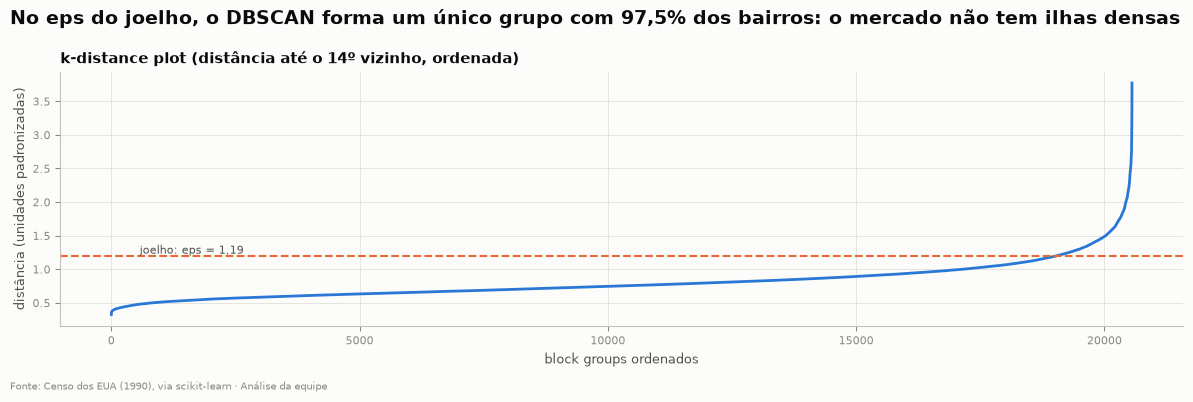

eps,Grupos,Ruído,Maior grupo
"0,89",2,"10,5%","89,3%"
"1,19",1,"2,5%","97,5%"
"1,49",1,"0,8%","99,2%"
"1,79",1,"0,3%","99,7%"


In [41]:
# k-distance: distância de cada ponto até o seu 14º vizinho, ordenada; eps = joelho da curva
MIN_SAMPLES = 2 * Z.shape[1]
kth_distance = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z).kneighbors(Z)[0][:, -1])
EPS = float(kth_distance[elbow_point(np.arange(len(kth_distance)), kth_distance)])

# Sensibilidade do DBSCAN: número de grupos e ruído para eps em torno do joelho
dbscan_rows = []
for factor in [0.75, 1.0, 1.25, 1.5]:
    labels = DBSCAN(eps=EPS * factor, min_samples=MIN_SAMPLES).fit_predict(Z)
    sizes = pd.Series(labels[labels >= 0]).value_counts()
    dbscan_rows.append({"eps": EPS * factor, "clusters": labels.max() + 1, "ruido_pct": 100 * (labels == -1).mean(),
                        "maior_cluster_pct": 100 * sizes.max() / len(Z) if len(sizes) else 0})
dbscan_table = pd.DataFrame(dbscan_rows)
at_knee = dbscan_table.iloc[1]

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(kth_distance, color=BLUE, linewidth=2)
ax.axhline(EPS, color=ORANGE, linewidth=1.5, linestyle="--")
ax.text(len(kth_distance) * 0.02, EPS, f"  joelho: eps = {br(EPS, 2)}", va="bottom", fontsize=8, color=INK_2)
ax.set_title(f"k-distance plot (distância até o {MIN_SAMPLES}º vizinho, ordenada)")
ax.set_xlabel("block groups ordenados")
ax.set_ylabel("distância (unidades padronizadas)")
groups_text = ("um único grupo" if int(at_knee["clusters"]) == 1
               else f"{int(at_knee['clusters'])} grupos, o maior")
action_title(fig, f"No eps do joelho, o DBSCAN forma {groups_text} com {br(at_knee['maior_cluster_pct'], 1)}% "
                  "dos bairros: o mercado não tem ilhas densas")
finish(fig)

exec_table(dbscan_table, formats={"eps": "dec2", "clusters": "int", "ruido_pct": "pct", "maior_cluster_pct": "pct"},
           labels={"eps": "eps", "clusters": "Grupos", "ruido_pct": "Ruído", "maior_cluster_pct": "Maior grupo"})

**O DBSCAN não encontra segmentos neste mercado:**

- **No eps do joelho (1,19):** um único grupo com **97,5%** dos block groups, mais 2,5% de ruído.
- **Com eps maior:** o grupo único só aumenta.
- **Com eps 25% menor (0,89):** 10,5% viram ruído e o "segundo grupo" tem só 41 block groups (0,2%).

Isso confirma o que a densidade no plano do PCA já mostrava: **não há regiões densas separadas por vazios**. O mercado é um contínuo, e o DBSCAN foi feito para outro tipo de estrutura. Ele serve aqui como **diagnóstico** (confirma o contínuo e aponta os atípicos), e não como segmentação.

In [42]:
# Perfil (mediana) dos pontos de ruído comparado com o dos demais
dbscan_labels = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Z)
dbscan_noise = pd.Series(dbscan_labels == -1, index=Z.index)
noise_profile = pd.DataFrame({"mediana_ruido": df_feat.loc[dbscan_noise, FINAL_FEATURES].median(),
                              "mediana_demais": df_feat.loc[~dbscan_noise, FINAL_FEATURES].median()})
noise_profile

,mediana_ruido,mediana_demais
MedInc,2.162,3.558
HouseAge,28.000,29.000
AveRooms,3.716,5.244
AveOccup,2.337,2.823
MedHouseVal,2.310,1.792
dist_coast_km,7.600,19.052
pop_density_3km,"1,506.897","1,867.206"


**Quem são os 2,5% de "ruído"?** São block groups com uma **combinação rara** de características:

- renda baixa (US\$ 21,6 mil vs. US\$ 35,6 mil nos demais);
- moradias pequenas (3,7 vs. 5,2 cômodos);
- casas caras (US\$ 231 mil vs. US\$ 179 mil);
- perto do mar (7,6 vs. 19 km).

É o perfil de bairros de aluguel, de estudantes ou de aposentados no litoral, onde quem mora não é quem poderia comprar. Esses bairros continuam na segmentação final: o K-Means vai colocá-los no segmento mais próximo.

## 6.4 Clustering hierárquico (Ward)

O método de **Ward** começa com cada ponto sozinho e une, a cada passo, os dois grupos cuja união aumenta menos a variância interna. O **dendrograma** mostra a ordem das uniões: cortes altos dão poucos macro-grupos; cortes baixos, muitos grupos finos.

O custo de memória cresce com o quadrado do número de linhas, então usamos uma **amostra aleatória de 5.000 block groups** e depois atribuímos cada um dos demais ao centro do grupo hierárquico mais próximo.

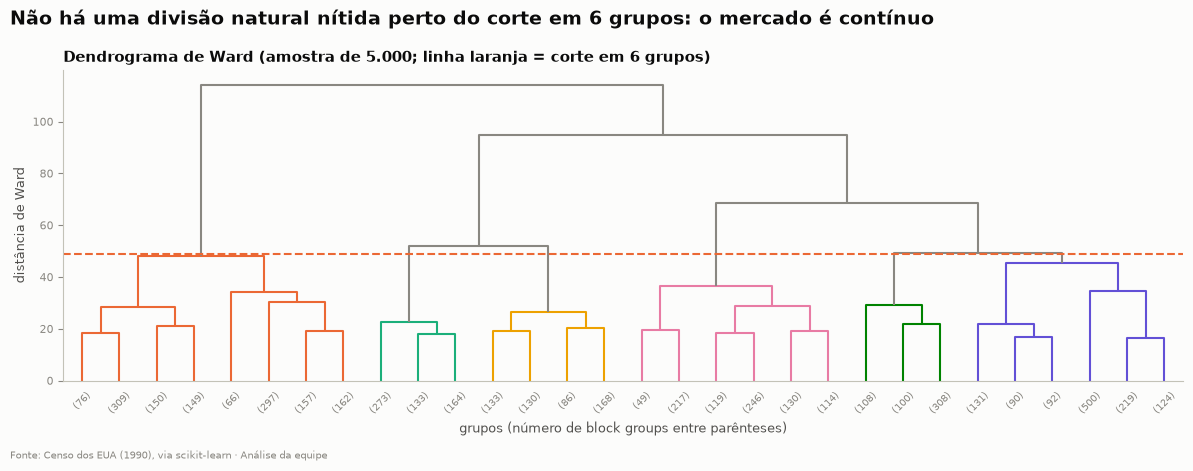

k,3,4,5,6,7,8,9,10
silhouette_amostra,0.175,0.151,0.119,0.122,0.116,0.113,0.110,0.096


In [43]:
# Ward sobre uma amostra de 5.000 (o custo de memória cresce com o quadrado das linhas)
sample_idx = Z.sample(5_000, random_state=RANDOM_STATE).index
ward_links = linkage(Z.loc[sample_idx], method="ward")
ward_cut = (ward_links[-(K_FINAL - 1), 2] + ward_links[-K_FINAL, 2]) / 2   # entre as uniões que dão K e K+1 grupos

fig, ax = plt.subplots(figsize=(12, 4.5))
dendrogram(ward_links, truncate_mode="lastp", p=30, ax=ax, color_threshold=ward_cut,
           above_threshold_color=GRAY, leaf_font_size=7)
ax.axhline(ward_cut, color=ORANGE, linewidth=1.5, linestyle="--")
ax.set_title(f"Dendrograma de Ward (amostra de 5.000; linha laranja = corte em {K_FINAL} grupos)")
ax.set_ylabel("distância de Ward")
ax.set_xlabel("grupos (número de block groups entre parênteses)")
ax.grid(False)
action_title(fig, f"Não há uma divisão natural nítida perto do corte em {K_FINAL} grupos: o mercado é contínuo")
finish(fig)

# Silhouette da amostra para cortes de 3 a 10 grupos
ward_rows = []
for k in range(3, 11):
    sample_labels = fcluster(ward_links, t=k, criterion="maxclust")
    ward_rows.append({"k": k, "silhouette_amostra": silhouette_score(Z.loc[sample_idx], sample_labels)})
pd.DataFrame(ward_rows).set_index("k").round(3).T

In [44]:
# Corta a árvore em K_FINAL grupos e atribui cada block group ao centro de grupo mais próximo
ward_sample_labels = fcluster(ward_links, t=K_FINAL, criterion="maxclust") - 1
ward_centers = Z.loc[sample_idx].groupby(ward_sample_labels).mean()
ward_labels = cdist(Z, ward_centers).argmin(axis=1)
print(f"Ward com {K_FINAL} grupos, atribuído a todos os {len(Z):,} block groups.")
print("Tamanho dos grupos (%):", np.round(100 * np.bincount(ward_labels) / len(Z), 1))

Ward com 6 grupos, atribuído a todos os 20,555 block groups.
Tamanho dos grupos (%): [22.9 17.5 10.5 19.1 11.9 18.1]


## 6.5 Gaussian Mixture Models (GMM)

O GMM supõe que os dados vêm de uma mistura de nuvens gaussianas (elípticas) e dá, para cada block group, a **probabilidade** de pertencer a cada segmento. Escolhemos o número de componentes pelo **BIC** e pelo **AIC** (critérios que premiam o ajuste e penalizam a complexidade; menor é melhor).

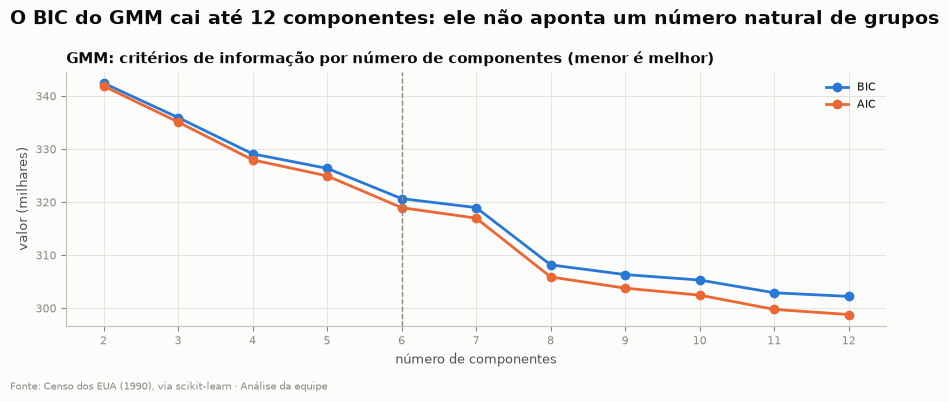

Menor BIC: 12 componentes | menor AIC: 12 componentes
GMM com 6 componentes | block groups com probabilidade máxima < 0,6: 11.2%
Tamanho dos grupos (%): [27.9 13.1  7.6 18.1 15.1 18.3]


In [45]:
# Ajusta um GMM (covariância completa) para cada número de componentes e guarda BIC e AIC
gmm_rows, gmm_models = [], {}
for k in K_RANGE:
    gmm = GaussianMixture(n_components=k, covariance_type="full", n_init=2, random_state=RANDOM_STATE).fit(Z)
    gmm_models[k] = gmm
    gmm_rows.append({"k": k, "BIC": gmm.bic(Z), "AIC": gmm.aic(Z)})
gmm_scores = pd.DataFrame(gmm_rows).set_index("k")

fig, ax = plt.subplots(figsize=(9, 3.8))
for col, color in [("BIC", BLUE), ("AIC", ORANGE)]:
    ax.plot(gmm_scores.index, gmm_scores[col] / 1000, marker="o", color=color, linewidth=2, label=col)
ax.axvline(K_FINAL, color=GRAY, linestyle="--", linewidth=1)
ax.set_title("GMM: critérios de informação por número de componentes (menor é melhor)")
ax.set_xlabel("número de componentes")
ax.set_ylabel("valor (milhares)")
ax.set_xticks(list(K_RANGE))
ax.legend()
best_bic = gmm_scores["BIC"].idxmin()
action_title(fig, f"O BIC do GMM cai até {max(K_RANGE)} componentes: ele não aponta um número natural de grupos"
             if best_bic == max(K_RANGE) else f"O BIC do GMM é mínimo com {best_bic} componentes")
finish(fig)

print(f"Menor BIC: {gmm_scores['BIC'].idxmin()} componentes | menor AIC: {gmm_scores['AIC'].idxmin()} componentes")
# GMM final: rótulo mais provável e a probabilidade máxima de cada block group
gmm_final = gmm_models[K_FINAL]
gmm_labels = gmm_final.predict(Z)
gmm_max_prob = gmm_final.predict_proba(Z).max(axis=1)
print(f"GMM com {K_FINAL} componentes | block groups com probabilidade máxima < 0,6: {(gmm_max_prob < 0.6).mean():.1%}")
print("Tamanho dos grupos (%):", np.round(100 * np.bincount(gmm_labels, minlength=K_FINAL) / len(Z), 1))

- **Ward:** sobre a amostra de 5.000, a silhouette cai de 0,175 (3 grupos) para cerca de 0,12 (5 a 7 grupos). Com 6 grupos, os tamanhos ficam equilibrados (10% a 23%).
- **GMM: o BIC e o AIC diminuem continuamente até 12 componentes**, sem um mínimo claro. Com 20 mil linhas, cada componente a mais sempre melhora um pouco o ajuste. O GMM descreve o *formato* da nuvem contínua com cada vez mais elipses, em vez de revelar grupos naturais. Por isso, usamos o mesmo k = 6 para a comparação.
- **Pertencimento incerto:** com 6 componentes, **11,2% dos block groups** têm probabilidade máxima abaixo de 0,6. São os bairros "em transição" entre dois segmentos, uma informação que só o GMM entrega.

## 6.6 Comparação dos algoritmos e escolha final

Comparamos todos com o mesmo número de segmentos e as mesmas métricas. A silhouette é calculada sobre a mesma amostra de 10.000 block groups para todos. No DBSCAN, as métricas ignoram os pontos de ruído.

In [46]:
kmeans_raw_labels = kmeans_models[K_FINAL].labels_


def summarize(name, labels, note=""):
    """Métricas de qualidade de uma segmentação; sem pelo menos 2 grupos, as métricas não existem (NaN)."""
    valid = labels >= 0
    sizes = np.bincount(labels[valid]) / len(labels) * 100
    sizes = sizes[sizes > 0]
    has_groups = len(sizes) >= 2
    return {"algoritmo": name, "clusters": len(sizes),
            "silhouette": silhouette_score(Z[valid], labels[valid], sample_size=10_000,
                                           random_state=RANDOM_STATE) if has_groups else np.nan,
            "davies_bouldin": davies_bouldin_score(Z[valid], labels[valid]) if has_groups else np.nan,
            "calinski_harabasz": calinski_harabasz_score(Z[valid], labels[valid]) if has_groups else np.nan,
            "menor_cluster_pct": sizes.min(), "maior_cluster_pct": sizes.max(),
            "ruido_pct": 100 * (~valid).mean(),
            "ARI_vs_KMeans": adjusted_rand_score(kmeans_raw_labels[valid], labels[valid]), "observação": note}


# Tabela comparativa com as mesmas métricas para todos os algoritmos
dbscan_tight_labels = DBSCAN(eps=EPS * 0.75, min_samples=MIN_SAMPLES).fit_predict(Z)
comparison = pd.DataFrame([
    summarize(f"K-Means (k={K_FINAL})", kmeans_raw_labels, "centróides interpretáveis"),
    summarize(f"GMM ({K_FINAL} componentes)", gmm_labels, "probabilidades de pertencimento"),
    summarize(f"Ward ({K_FINAL} grupos)", ward_labels, "amostra de 5.000 + centro mais próximo"),
    summarize(f"DBSCAN (eps={EPS:.2f}, joelho)", dbscan_labels, "um único grupo denso + ruído"),
    summarize(f"DBSCAN (eps={EPS * 0.75:.2f})", dbscan_tight_labels, "eps menor: mais ruído"),
]).set_index("algoritmo")
exec_table(comparison.reset_index(),
           formats={"clusters": "int", "silhouette": "dec3", "davies_bouldin": "dec3", "calinski_harabasz": "int",
                    "menor_cluster_pct": "pct", "maior_cluster_pct": "pct", "ruido_pct": "pct",
                    "ARI_vs_KMeans": "dec2"},
           labels={"algoritmo": "Algoritmo", "clusters": "Grupos", "silhouette": "Silhouette",
                   "davies_bouldin": "Davies-Bouldin", "calinski_harabasz": "Calinski-Harabasz",
                   "menor_cluster_pct": "Menor grupo", "maior_cluster_pct": "Maior grupo", "ruido_pct": "Ruído",
                   "ARI_vs_KMeans": "Concordância com o K-Means (ARI)", "observação": "Observação"},
           highlight="silhouette", caption="Comparação dos algoritmos com as mesmas métricas")

Algoritmo,Grupos,Silhouette,Davies-Bouldin,Calinski-Harabasz,Menor grupo,Maior grupo,Ruído,Concordância com o K-Means (ARI),Observação
K-Means (k=6),6,"0,184","1,528",4.479,"11,1%","20,5%","0,0%","1,00",centróides interpretáveis
GMM (6 componentes),6,"0,092","2,155",2.789,"7,6%","27,9%","0,0%","0,33",probabilidades de pertencimento
Ward (6 grupos),6,"0,182","1,533",4.405,"10,5%","22,9%","0,0%","0,75",amostra de 5.000 + centro mais próximo
"DBSCAN (eps=1.19, joelho)",1,–,–,–,"97,5%","97,5%","2,5%","0,00",um único grupo denso + ruído
DBSCAN (eps=0.89),2,"0,149","0,996",65,"0,2%","89,3%","10,5%","0,00",eps menor: mais ruído


**Escolhemos o K-Means**, que vence ou empata em todos os critérios técnicos e de negócio:

- **Qualidade:** tem a melhor silhouette (0,184), o melhor Davies-Bouldin (1,53) e o melhor Calinski-Harabasz (4.479).
- **Ward chega muito perto** (0,182 de silhouette) e concorda bastante com o K-Means (**ARI de 0,75**): dois métodos diferentes encontram essencialmente os mesmos segmentos, o que reforça a confiança no resultado.
- **GMM fica bem atrás** (silhouette 0,09, ARI de 0,33): as elipses flexíveis se sobrepõem num mercado contínuo, e os grupos ficam menos nítidos.
- **DBSCAN não segmenta** (um único grupo); por isso as métricas aparecem vazias (NaN). Com eps menor, a silhouette de 0,15 é enganosa, porque vem de um grupo com 89% dos dados e outro com 0,2%.
- **Negócio:** o K-Means dá um **centróide** (perfil médio) por segmento, fácil de virar persona. Também classifica novos bairros instantaneamente (seção 9.7) e é estável (seção 7.3).

**GMM e Ward não são descartados:** eles voltam no ensemble (seção 8.5) para identificar os bairros de transição.

> **Decisão** · K-Means com 6 segmentos: as melhores métricas entre os algoritmos testados e o maior número de segmentos que continua estável.
>
> **Insight** · O DBSCAN encontra um único grupo: os segmentos são regiões de um contínuo, e não ilhas.
>
> **Para o negócio** · Seis segmentos bastam para diferenciar estratégias, e nenhum é pequeno demais para ter uma equipe própria.

In [47]:
km_final = kmeans_models[K_FINAL]

# Numeração estável: segmento 1 = menor valor mediano das casas, ..., segmento K = maior
price_order = df_feat["MedHouseVal"].groupby(kmeans_raw_labels).median().sort_values().index
RELABEL = {old: new for new, old in enumerate(price_order, start=1)}
segment = pd.Series(kmeans_raw_labels, index=Z.index).map(RELABEL).rename("segmento")
SEGMENTS = list(range(1, K_FINAL + 1))
SEG_COLOR = dict(zip(SEGMENTS, PALETTE))
segment.value_counts().sort_index().rename("block_groups").to_frame().T

segmento,1,2,3,4,5,6
block_groups,4204,3258,2635,3965,4212,2281


---
# 7. Avaliação e Validação dos Clusters

Validamos a segmentação final (K-Means) em quatro frentes: **métricas de qualidade interna**, **separação e coesão**, **estabilidade** e **coerência geográfica**. Por fim, visualizamos os clusters no espaço do PCA.

## 7.1 Métricas de qualidade interna

In [48]:
# Métricas do modelo final, comparadas com uma referência de rótulos sorteados ao acaso
final_metrics = pd.Series({
    "Silhouette (todos os 20.555 block groups)": silhouette_score(Z, segment),
    "Inércia": km_final.inertia_,
    "Davies-Bouldin": davies_bouldin_score(Z, segment),
    "Calinski-Harabasz": calinski_harabasz_score(Z, segment),
}, name="valor")

shuffled = np.random.default_rng(RANDOM_STATE).permutation(segment.to_numpy())
baseline = pd.Series({
    "Silhouette (todos os 20.555 block groups)": silhouette_score(Z, shuffled, sample_size=10_000,
                                                                   random_state=RANDOM_STATE),
    "Inércia": float(((Z - Z.groupby(shuffled).transform("mean")) ** 2).to_numpy().sum()),
    "Davies-Bouldin": davies_bouldin_score(Z, shuffled),
    "Calinski-Harabasz": calinski_harabasz_score(Z, shuffled),
}, name="rótulos aleatórios (referência)")
metrics_table = pd.concat([final_metrics, baseline], axis=1)
exec_table(metrics_table, index=True, formats={"Silhouette (todos os 20.555 block groups)": "dec3",
                                               "Inércia": "int", "Davies-Bouldin": "dec3",
                                               "Calinski-Harabasz": "int"},
           labels={"valor": "Segmentação final", "rótulos aleatórios (referência)": "Rótulos aleatórios (referência)"})

,Segmentação final,Rótulos aleatórios (referência)
Silhouette (todos os 20.555 block groups),"0,185","-0,008"
Inércia,68.854,143.849
Davies-Bouldin,"1,528","122,273"
Calinski-Harabasz,4.479,1


**Como ler as métricas:**

- **Silhouette de 0,185:** costuma ser classificada como "estrutura fraca". Mas, como vimos, o mercado é um contínuo sem fronteiras naturais, e nesse cenário nenhuma segmentação teria silhouette alta. O que importa é que ela é **muito melhor que o acaso**: com rótulos sorteados, a silhouette é −0,01.
- **Inércia 52% menor que a de rótulos aleatórios:** os segmentos explicam metade da variação do mercado.
- **Davies-Bouldin de 1,53 vs. 122** e **Calinski-Harabasz de 4.479 vs. 1:** os segmentos são muito mais compactos e separados do que uma divisão arbitrária.

**Conclusão:** os segmentos não são "ilhas", mas **regiões bem definidas de um contínuo**. É o tipo de segmentação que se espera em mercados reais, e é útil, desde que se reconheçam as zonas de transição (seção 8.5).

## 7.2 Separação e coesão

- **Gráfico de silhouette:** cada barra horizontal é um block group; a largura é a sua silhouette. Barras largas e positivas = bem encaixado no seu segmento; negativas = mais perto de outro segmento.
- **Distância entre centróides vs. dispersão interna:** um segmento é bem separado quando a distância até o centróide vizinho mais próximo é grande em relação à distância média dos seus membros até o próprio centro.

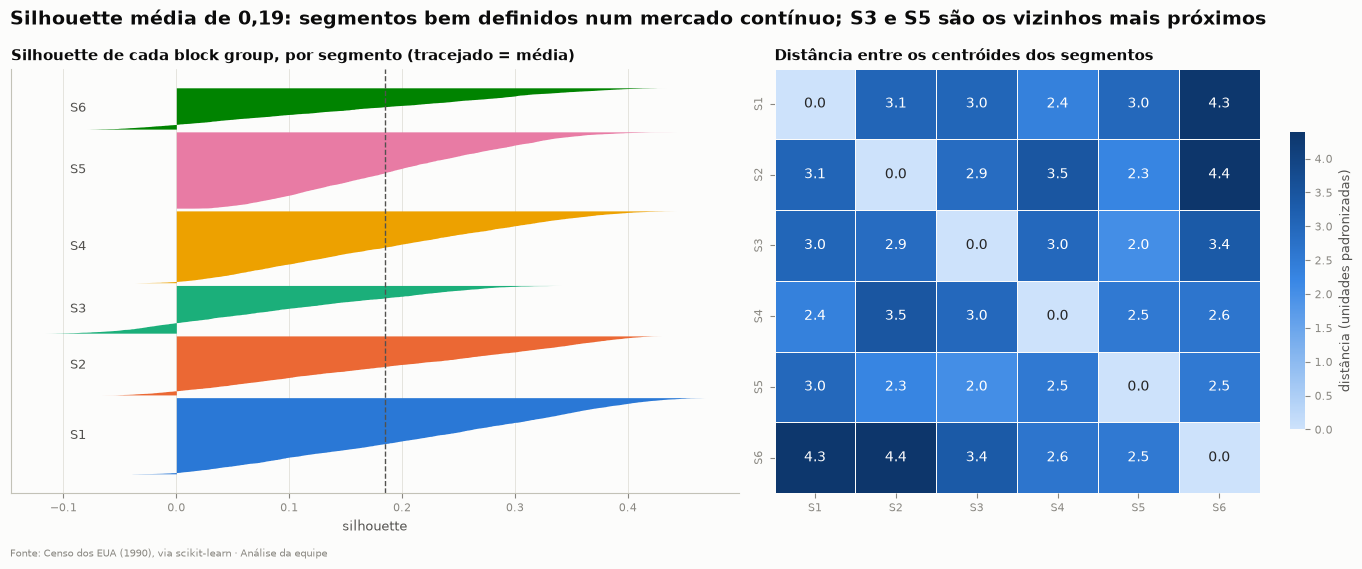

Segmento,Block groups,Silhouette média,Silhouette negativa,Dispersão interna,Distância ao vizinho,Separação ÷ coesão
S1,4.204,"0,22","1,6%","1,69","2,36","1,39"
S2,3.258,"0,19","7,1%","1,77","2,26","1,28"
S3,2.635,"0,10","22,1%","1,95","2,03","1,04"
S4,3.965,"0,19","1,6%","1,64","2,36","1,43"
S5,4.212,"0,20","0,0%","1,59","2,03","1,28"
S6,2.281,"0,17","11,4%","1,87","2,54","1,36"


In [49]:
# Silhouette de cada block group (gráfico de faca por segmento)
sil = pd.Series(silhouette_samples(Z, segment), index=Z.index)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
y_low = 0
for s in SEGMENTS:
    values = np.sort(sil[segment == s].to_numpy())
    axes[0].fill_betweenx(np.arange(y_low, y_low + len(values)), 0, values, color=SEG_COLOR[s], linewidth=0)
    axes[0].text(-0.08, y_low + len(values) / 2, f"S{s}", va="center", ha="right", fontsize=9, color=INK_2)
    y_low += len(values) + 150
axes[0].axvline(sil.mean(), color=INK_2, linestyle="--", linewidth=1)
axes[0].set_title("Silhouette de cada block group, por segmento (tracejado = média)")
axes[0].set_xlabel("silhouette")
axes[0].set_yticks([])

# Distância entre os centróides dos segmentos (separação)
centroids = Z.groupby(segment).mean()
centroid_dist = pd.DataFrame(cdist(centroids, centroids), index=[f"S{s}" for s in SEGMENTS],
                             columns=[f"S{s}" for s in SEGMENTS])
sns.heatmap(centroid_dist, cmap=BLUES, annot=True, fmt=".1f", ax=axes[1], linewidths=0.5, linecolor=SURFACE,
            cbar_kws={"shrink": 0.7, "label": "distância (unidades padronizadas)"})
axes[1].set_title("Distância entre os centróides dos segmentos")
closest = centroid_dist.replace(0, np.nan).stack().idxmin()
action_title(fig, f"Silhouette média de {br(sil.mean(), 2)}: segmentos bem definidos num mercado contínuo; "
                  f"{closest[0]} e {closest[1]} são os vizinhos mais próximos")
finish(fig)

# Coesão (distância média ao próprio centróide) e separação (distância ao centróide vizinho) por segmento
cohesion = pd.Series(np.linalg.norm(Z.to_numpy() - centroids.loc[segment].to_numpy(), axis=1), index=Z.index)
separation = pd.DataFrame({
    "block_groups": segment.value_counts().sort_index(),
    "silhouette_media": sil.groupby(segment).mean(),
    "pct_silhouette_negativa": 100 * (sil < 0).groupby(segment).mean(),
    "dispersao_interna": cohesion.groupby(segment).mean(),
    "distancia_ao_vizinho_mais_proximo": centroid_dist.replace(0, np.nan).min(axis=1).to_numpy(),
})
separation["razao_separacao_coesao"] = separation["distancia_ao_vizinho_mais_proximo"] / separation["dispersao_interna"]
exec_table(separation.reset_index().assign(segmento=lambda d: "S" + d["segmento"].astype(str)),
           formats={"block_groups": "int", "silhouette_media": "dec2", "pct_silhouette_negativa": "pct",
                    "dispersao_interna": "dec2", "distancia_ao_vizinho_mais_proximo": "dec2",
                    "razao_separacao_coesao": "dec2"},
           labels={"segmento": "Segmento", "block_groups": "Block groups", "silhouette_media": "Silhouette média",
                   "pct_silhouette_negativa": "Silhouette negativa", "dispersao_interna": "Dispersão interna",
                   "distancia_ao_vizinho_mais_proximo": "Distância ao vizinho",
                   "razao_separacao_coesao": "Separação ÷ coesão"},
           highlight="silhouette_media")

- **Quatro segmentos bem encaixados:** S1, S4 e S5 têm silhouette média de 0,19 a 0,22 e quase nenhum block group mal classificado (0% a 1,6% com silhouette negativa). S2 também (7%).
- **S6 (alto padrão)** tem 11% de silhouette negativa, mas é o segmento **mais distante dos demais**: está a 4,3 e 4,4 unidades de S1 e S2. Os seus vizinhos mais próximos são S5 (2,5) e S4 (2,6), e é na fronteira com eles que ficam os casos ambíguos: bairros bons, mas não de luxo.
- **S3 é o menos nítido:** silhouette de 0,10 e 22% de casos negativos. O seu vizinho mais próximo é S5 (distância de 2,0, a menor entre todos os pares), e a razão separação/coesão é de só 1,04. Por isso, S3 é o candidato natural à **clusterização recursiva** (seção 8.5).
- **Pares mais próximos:** S3–S5 (2,0), S2–S5 (2,3) e S1–S4 (2,4). Faz sentido: são, respectivamente, bairros urbanos com e sem famílias, bairros urbanos populares e de classe média, e interior e subúrbio.

## 7.3 Estabilidade dos clusters (bootstrap)

Repetimos o K-Means em **30 amostras bootstrap** (sorteio com reposição). Para cada segmento original, medimos o **índice de Jaccard** com o segmento mais parecido da amostra (1 = os mesmos block groups). Pela regra de Hennig (2007), Jaccard médio acima de 0,75 indica um cluster **estável** e abaixo de 0,5 um cluster que "se dissolve".

In [50]:
# Estabilidade: refaz o K-Means em 30 reamostragens e mede ARI global e Jaccard por segmento
N_BOOT_FINAL = 30
seg_array = segment.to_numpy()
jaccard_scores = {s: [] for s in SEGMENTS}
boot_aris = []
rng = np.random.default_rng(RANDOM_STATE)
for b in range(N_BOOT_FINAL):
    idx = np.unique(rng.choice(len(Z), size=len(Z), replace=True))
    boot = KMeans(n_clusters=K_FINAL, n_init=4, random_state=100 + b).fit(Z.iloc[idx])
    boot_aris.append(adjusted_rand_score(seg_array, boot.predict(Z)))
    original = seg_array[idx]
    for s in SEGMENTS:
        in_s = original == s
        best = max((in_s & (boot.labels_ == c)).sum() / (in_s | (boot.labels_ == c)).sum() for c in range(K_FINAL))
        jaccard_scores[s].append(best)

# Classificação de Hennig: Jaccard >= 0,75 estável; >= 0,6 moderado; abaixo, instável
stability = pd.DataFrame({"jaccard_medio": {s: np.mean(v) for s, v in jaccard_scores.items()},
                          "jaccard_minimo": {s: np.min(v) for s, v in jaccard_scores.items()}})
stability["avaliacao"] = np.select([stability["jaccard_medio"] >= 0.75, stability["jaccard_medio"] >= 0.6],
                                   ["estável", "moderadamente estável"], "instável")
print(f"ARI médio entre a segmentação final e as {N_BOOT_FINAL} reamostragens: "
      f"{np.mean(boot_aris):.3f} (mínimo {np.min(boot_aris):.3f})")
exec_table(stability.reset_index(names="segmento").assign(segmento=lambda d: "S" + d["segmento"].astype(str)),
           formats={"jaccard_medio": "dec3", "jaccard_minimo": "dec3"},
           labels={"segmento": "Segmento", "jaccard_medio": "Jaccard médio", "jaccard_minimo": "Jaccard mínimo",
                   "avaliacao": "Avaliação (Hennig)"},
           highlight="jaccard_medio")

ARI médio entre a segmentação final e as 30 reamostragens: 0.943 (mínimo 0.888)


Segmento,Jaccard médio,Jaccard mínimo,Avaliação (Hennig)
S1,"0,968","0,930",estável
S2,"0,968","0,936",estável
S3,"0,936","0,839",estável
S4,"0,948","0,898",estável
S5,"0,941","0,860",estável
S6,"0,961","0,891",estável


**A segmentação é muito estável:**

- O ARI médio entre a segmentação final e 30 reamostragens é de **0,94**, e o pior caso é 0,89.
- **Todos os seis segmentos** têm Jaccard médio acima de 0,93, bem acima do limite de 0,75 para um cluster "estável".
- Mesmo S3, o menos nítido, tem Jaccard mínimo de 0,84.

Para o negócio, isso significa que **os segmentos não são um acaso da amostra**: com outros dados do mesmo mercado, encontraríamos os mesmos grupos. A empresa pode construir estratégias de longo prazo sobre eles.

## 7.4 Distribuição geográfica dos clusters

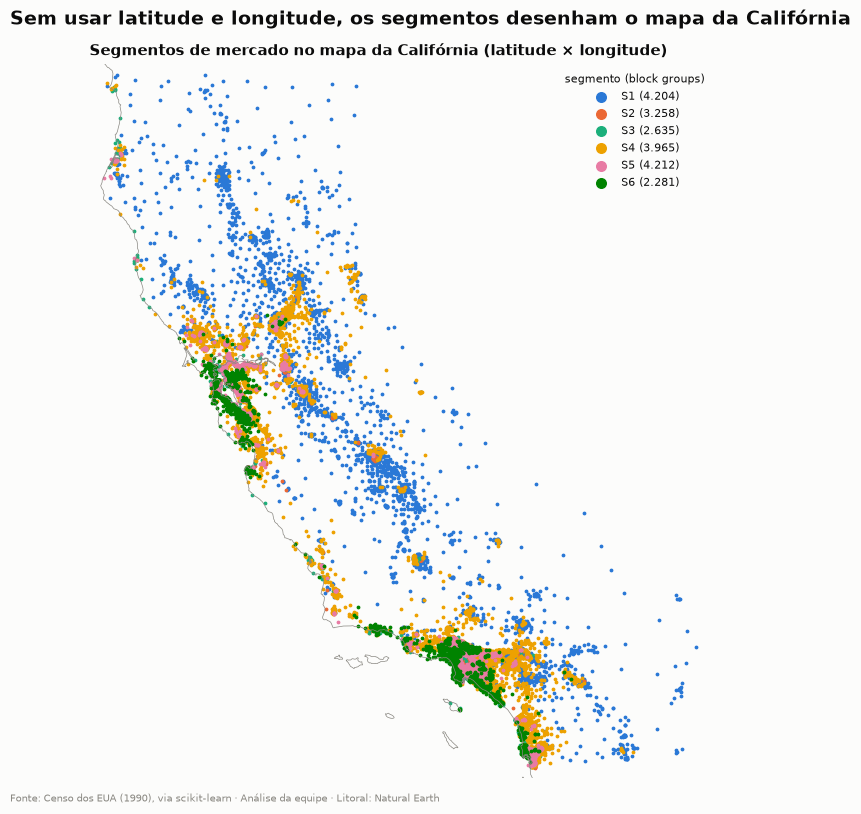

In [51]:
# Mapa obrigatório: latitude x longitude colorido pelo segmento
fig, ax = plt.subplots(figsize=(8, 8))
for s in SEGMENTS:
    inside = segment == s
    ax.scatter(df_feat.loc[inside, "Longitude"], df_feat.loc[inside, "Latitude"], s=3, color=SEG_COLOR[s],
               label=f"S{s} ({br(inside.sum())})")
coast.plot(ax=ax, color=GRAY, linewidth=0.5)
style_map(ax, "Segmentos de mercado no mapa da Califórnia (latitude × longitude)")
ax.legend(loc="upper right", markerscale=4, title="segmento (block groups)", title_fontsize=8)
action_title(fig, "Sem usar latitude e longitude, os segmentos desenham o mapa da Califórnia")
finish(fig, SOURCE_NOTE + " · Litoral: Natural Earth")

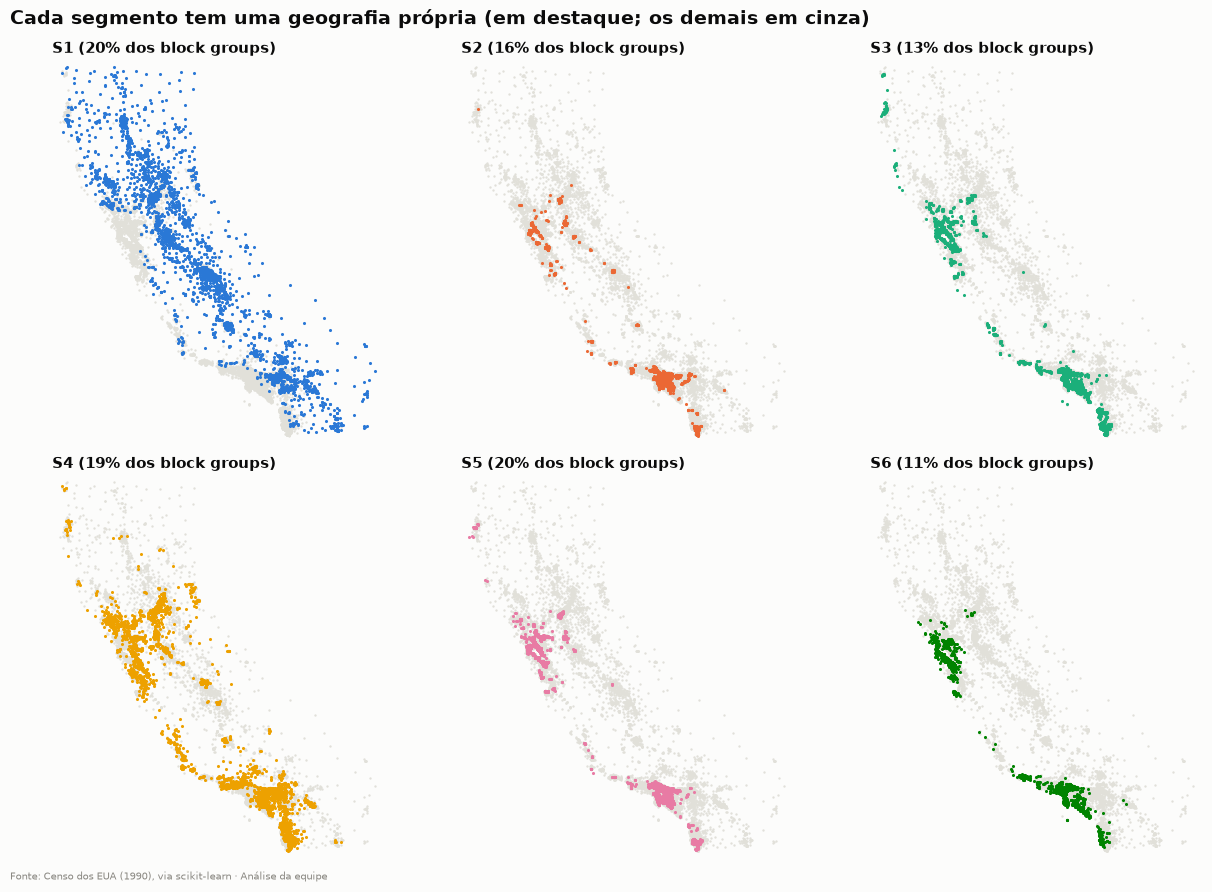

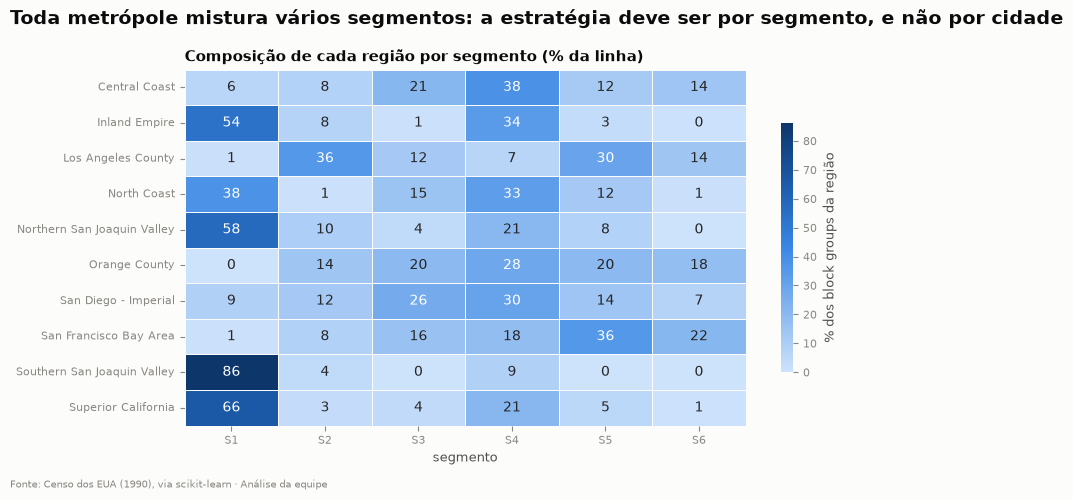

In [52]:
# Um mapa pequeno por segmento, com os demais em cinza
n_cols = 3
n_rows = int(np.ceil(K_FINAL / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 4.4 * n_rows))
for ax in axes.flat[K_FINAL:]:
    ax.set_visible(False)
for ax, s in zip(axes.flat, SEGMENTS):
    inside = segment == s
    ax.scatter(df_feat.loc[~inside, "Longitude"], df_feat.loc[~inside, "Latitude"], s=0.5, color="#e1e0d9")
    ax.scatter(df_feat.loc[inside, "Longitude"], df_feat.loc[inside, "Latitude"], s=1.5, color=SEG_COLOR[s])
    style_map(ax, f"S{s} ({br(100 * inside.mean())}% dos block groups)")
action_title(fig, "Cada segmento tem uma geografia própria (em destaque; os demais em cinza)")
finish(fig)

# Participação de cada segmento dentro de cada região
region_mix = pd.crosstab(df_feat["region"], segment, normalize="index") * 100
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.heatmap(region_mix.rename(columns=lambda s: f"S{s}"), cmap=BLUES, annot=True, fmt=".0f", ax=ax,
            linewidths=0.5, linecolor=SURFACE, cbar_kws={"shrink": 0.7, "label": "% dos block groups da região"})
ax.set_title("Composição de cada região por segmento (% da linha)")
ax.set_xlabel("segmento")
ax.set_ylabel("")
action_title(fig, "Toda metrópole mistura vários segmentos: a estratégia deve ser por segmento, e não por cidade")
finish(fig)

**Os segmentos fazem sentido no mapa, sem que a localização tenha sido usada diretamente.** Latitude e longitude ficaram fora do clustering, mas os segmentos formam padrões geográficos claros:

- **S1** domina o interior: 86% do sul do Vale de San Joaquin, 66% da Superior California e 58% do norte do Vale.
- **S6** (alto padrão) forma a faixa litorânea da Baía de San Francisco, do oeste de Los Angeles e de Orange County.
- **S2** concentra-se no centro e no sul de Los Angeles: 64% dos seus block groups estão em Los Angeles County.

**Os segmentos são tipos de bairro, e não regiões:**

- **S6 aparece em todas as metrópoles:** 859 block groups na Baía, 808 em Los Angeles, 282 em Orange County, 179 na Central Coast e 129 em San Diego.
- **Toda metrópole tem uma mistura de segmentos:** Los Angeles tem 36% de S2, 30% de S5, 14% de S6 e 12% de S3. Na Baía, predominam S5 (36%), S6 (22%) e S4 (18%).

É exatamente o que pedia o objetivo: **um "bairro rico no litoral" é reconhecido como tal, perto de Los Angeles ou de San Francisco.** Para a imobiliária, isso permite uma estratégia por segmento aplicada em várias cidades, em vez de uma estratégia por cidade.

## 7.5 Os clusters no espaço reduzido do PCA

**Como ler os gráficos abaixo:**

- Cada ponto é um block group (amostra de 6.000), colorido pelo segmento. Os rótulos `S1`, `S2`, ... marcam os centróides.
- Os eixos são os componentes principais da seção 5. As **setas** mostram a direção em que cada variável original cresce: um segmento posicionado na direção de uma seta tem valores altos daquela variável.
- Segmentos bem separados aparecem como nuvens em lugares diferentes; a sobreposição nas bordas mostra que o mercado é **contínuo**: há bairros de transição entre segmentos vizinhos.

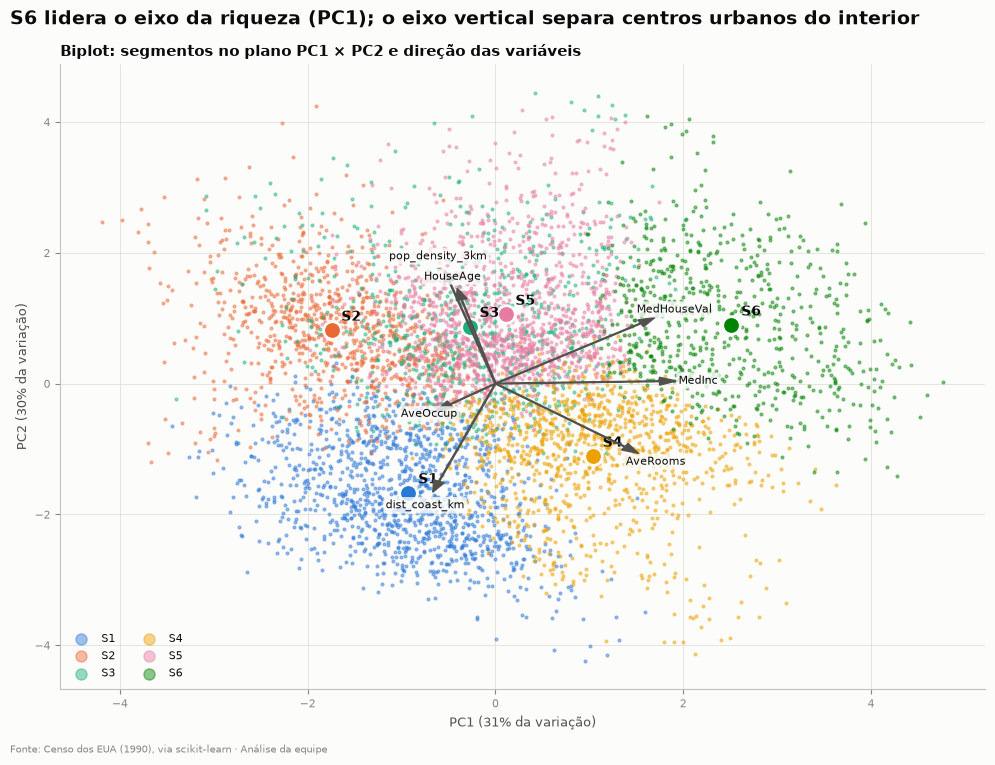

In [53]:
# Biplot: amostra de pontos e centróides no plano PC1 x PC2, com as setas das variáveis
plot_idx = Z.sample(6_000, random_state=RANDOM_STATE).index
centroid_pcs = pd.DataFrame(pca.transform(centroids)[:, :3], index=SEGMENTS, columns=["PC1", "PC2", "PC3"])

fig, ax = plt.subplots(figsize=(10, 7.5))
for s in SEGMENTS:
    sel = plot_idx[segment.loc[plot_idx] == s]
    ax.scatter(pcs.loc[sel, "PC1"], pcs.loc[sel, "PC2"], s=4, color=SEG_COLOR[s], alpha=0.45, label=f"S{s}")
for s in SEGMENTS:
    ax.scatter(*centroid_pcs.loc[s, ["PC1", "PC2"]], s=160, color=SEG_COLOR[s], edgecolor=SURFACE, linewidth=2, zorder=5)
    ax.annotate(f"S{s}", centroid_pcs.loc[s, ["PC1", "PC2"]], xytext=(7, 7), textcoords="offset points",
                fontsize=10, fontweight="bold", color=INK, zorder=6)
arrow_scale = 3.2
for feature in FINAL_FEATURES:
    dx, dy = loadings.loc[feature, "PC1"] * arrow_scale, loadings.loc[feature, "PC2"] * arrow_scale
    ax.arrow(0, 0, dx, dy, color=INK_2, width=0.012, head_width=0.12, length_includes_head=True, zorder=7)
    ax.text(dx * 1.12, dy * 1.12, feature, fontsize=8, color=INK, ha="center", va="center", zorder=8,
            bbox={"boxstyle": "round,pad=0.2", "facecolor": SURFACE, "edgecolor": "none", "alpha": 0.8})
ax.set_title("Biplot: segmentos no plano PC1 × PC2 e direção das variáveis")
ax.set_xlabel(f"PC1 ({explained.iloc[0, 0]:.0f}% da variação)")
ax.set_ylabel(f"PC2 ({explained.iloc[1, 0]:.0f}% da variação)")
ax.legend(loc="lower left", markerscale=4, ncol=2)
richest = int(centroid_pcs["PC1"].idxmax())
action_title(fig, f"S{richest} lidera o eixo da riqueza (PC1); o eixo vertical separa centros urbanos do interior")
finish(fig)

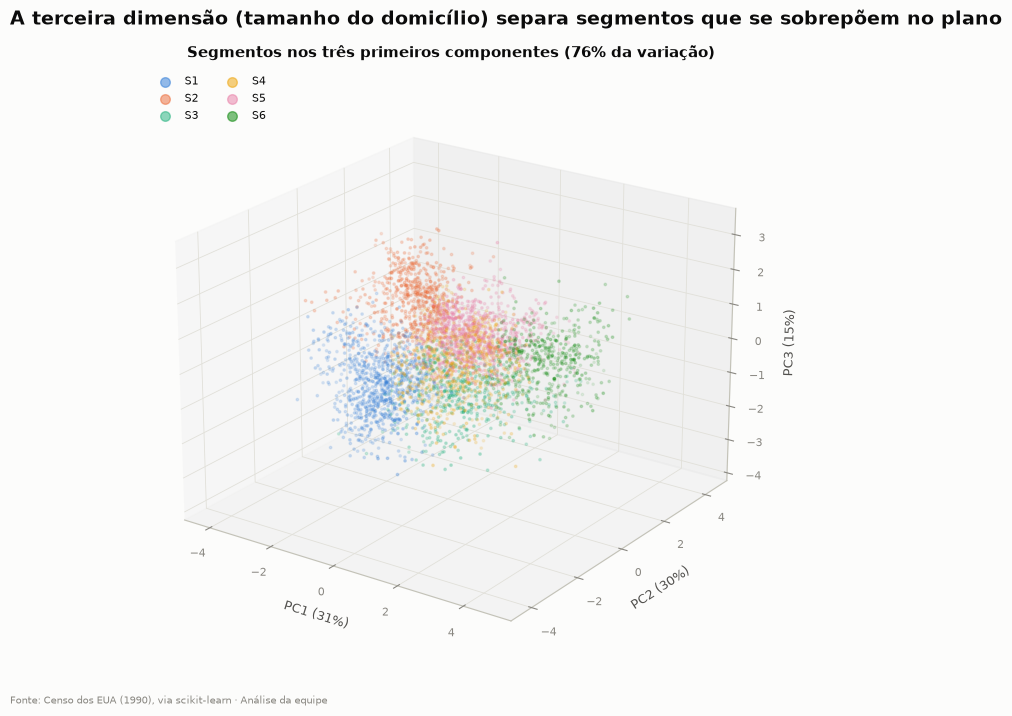

In [54]:
# Mesma amostra nos três primeiros componentes (3D)
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
sub_idx = plot_idx[:4_000]
for s in SEGMENTS:
    sel = sub_idx[segment.loc[sub_idx] == s]
    ax.scatter(pcs.loc[sel, "PC1"], pcs.loc[sel, "PC2"], pcs.loc[sel, "PC3"], s=3, color=SEG_COLOR[s],
               alpha=0.5, label=f"S{s}")
ax.set_xlabel(f"PC1 ({explained.iloc[0, 0]:.0f}%)")
ax.set_ylabel(f"PC2 ({explained.iloc[1, 0]:.0f}%)")
ax.set_zlabel(f"PC3 ({explained.iloc[2, 0]:.0f}%)")
ax.set_title(f"Segmentos nos três primeiros componentes ({explained.iloc[2, 1]:.0f}% da variação)")
ax.view_init(elev=22, azim=-55)
ax.legend(loc="upper left", markerscale=4, ncol=2)
action_title(fig, "A terceira dimensão (tamanho do domicílio) separa segmentos que se sobrepõem no plano")
finish(fig)

**Leitura do biplot:**

- **S6** fica no extremo direito do PC1, na direção das setas de renda e valor: é o eixo da riqueza.
- **S1** fica embaixo, na direção da seta de distância da costa: interior.
- **S4** fica embaixo e à direita, na direção da seta de cômodos: casas grandes, longe dos centros.
- **S2** fica à esquerda e acima: baixa renda, denso, na direção oposta à das setas de riqueza.
- **S3 e S5 se sobrepõem no plano PC1 × PC2.** Eles se separam na **terceira dimensão** (PC3, pessoas por domicílio) e na idade das casas: S3 tem domicílios pequenos (2,1 pessoas) e casas mais novas; S5 tem famílias (2,7 pessoas) e as casas mais antigas. No gráfico 3D, S3 (verde-água) aparece abaixo de S5 (rosa) no eixo PC3.

As bordas entre as nuvens se tocam: são os **bairros de transição**, coerentes com o mercado contínuo. Mesmo assim, cada segmento ocupa uma região própria, e a posição dos centróides resume bem o perfil de cada um.

> **Insight** · Segmentos muito estáveis (ARI de 0,94; Jaccard acima de 0,93 em todos) e coerentes no mapa, sem usar as coordenadas.
>
> **Para o negócio** · Os segmentos são tipos de bairro que se repetem em várias cidades: a mesma estratégia vale em Los Angeles, San Francisco e San Diego.

---
# 8. Interpretação e Caracterização dos Clusters

Esta é a etapa que transforma o resultado técnico em conhecimento de negócio. Descrevemos cada segmento em **unidades naturais** (dólares, anos, quilômetros), e não nos valores padronizados usados pelo algoritmo.

## 8.1 Perfil de cada segmento

In [55]:
# Tabela de análise: features em unidades naturais + segmento + flags
seg = df_feat.assign(segmento=segment, no_teto=cap_flags["MedHouseVal_no_teto"],
                     casa_nova=df_feat["HouseAge"] <= 10)
grouped = seg.groupby("segmento")

# Perfil de cada segmento em unidades naturais (medianas, percentuais e tamanhos)
profile = pd.DataFrame({
    "block_groups": grouped.size(),
    "pct_block_groups": 100 * grouped.size() / len(seg),
    "domicilios": grouped["households"].sum().round(),
    "pct_domicilios": 100 * grouped["households"].sum() / seg["households"].sum(),
    "renda_mediana_usd": grouped["MedInc"].median() * 10_000,
    "renda_per_capita_usd": grouped["income_per_person"].median(),
    "valor_mediano_usd": grouped["MedHouseVal"].median() * 100_000,
    "valor_p25_usd": grouped["MedHouseVal"].quantile(0.25) * 100_000,
    "valor_p75_usd": grouped["MedHouseVal"].quantile(0.75) * 100_000,
    "pct_no_teto_500k": 100 * grouped["no_teto"].mean(),
    "anos_de_renda_por_casa": grouped["price_to_income"].median(),
    "idade_casas_anos": grouped["HouseAge"].median(),
    "pct_casas_ate_10_anos": 100 * grouped["casa_nova"].mean(),
    "comodos_por_domicilio": grouped["AveRooms"].median(),
    "pessoas_por_domicilio": grouped["AveOccup"].median(),
    "dist_costa_km": grouped["dist_coast_km"].median(),
    "densidade_hab_km2": grouped["pop_density_3km"].median(),
    "dist_grande_cidade_km": grouped["dist_big_city_km"].median(),
    "indice_luxo": grouped["luxury_index"].median(),
})

# Rótulos legíveis e formato de cada linha da tabela de perfil
PROFILE_ROWS = {
    "block_groups": ("Block groups", "int"), "pct_block_groups": ("% dos block groups", "pct"),
    "domicilios": ("Domicílios", "int"), "pct_domicilios": ("% dos domicílios", "pct"),
    "renda_mediana_usd": ("Renda mediana", "usd_mil"), "renda_per_capita_usd": ("Renda per capita", "usd"),
    "valor_mediano_usd": ("Valor mediano das casas", "usd_mil"), "valor_p25_usd": ("Valor: 1º quartil", "usd_mil"),
    "valor_p75_usd": ("Valor: 3º quartil", "usd_mil"), "pct_no_teto_500k": ("% no teto de US$ 500 mil", "pct"),
    "anos_de_renda_por_casa": ("Anos de renda por casa", "dec1"), "idade_casas_anos": ("Idade das casas (anos)", "int"),
    "pct_casas_ate_10_anos": ("% com casas de até 10 anos", "pct"), "comodos_por_domicilio": ("Cômodos por domicílio", "dec1"),
    "pessoas_por_domicilio": ("Pessoas por domicílio", "dec1"), "dist_costa_km": ("Distância da costa", "km"),
    "densidade_hab_km2": ("Densidade (hab./km²)", "int"), "dist_grande_cidade_km": ("Distância de cidade grande", "km"),
    "indice_luxo": ("Índice de luxo (0 a 100)", "dec1"),
}
exec_table(profile.T.rename(index={k: v[0] for k, v in PROFILE_ROWS.items()}), index=True,
           formats={label: kind for label, kind in PROFILE_ROWS.values()},
           labels={s: f"S{s}" for s in SEGMENTS}, caption="Perfil de cada segmento (medianas)")

segmento,S1,S2,S3,S4,S5,S6
Block groups,4.204,3.258,2.635,3.965,4.212,2.281
% dos block groups,"20,5%","15,9%","12,8%","19,3%","20,5%","11,1%"
Domicílios,1.895.590,1.447.166,1.764.629,2.428.166,1.720.333,1.049.715
% dos domicílios,"18,4%","14,0%","17,1%","23,6%","16,7%","10,2%"
Renda mediana,US$ 26 mil,US$ 24 mil,US$ 30 mil,US$ 50 mil,US$ 39 mil,US$ 64 mil
Renda per capita,US$ 9.328,US$ 6.223,US$ 13.776,US$ 16.477,US$ 14.395,US$ 25.371
Valor mediano das casas,US$ 91 mil,US$ 145 mil,US$ 206 mil,US$ 215 mil,US$ 216 mil,US$ 444 mil
Valor: 1º quartil,US$ 70 mil,US$ 108 mil,US$ 154 mil,US$ 162 mil,US$ 173 mil,US$ 367 mil
Valor: 3º quartil,US$ 117 mil,US$ 171 mil,US$ 271 mil,US$ 268 mil,US$ 263 mil,US$ 500 mil
% no teto de US$ 500 mil,"0,0%","0,1%","2,1%","0,3%","0,6%","38,0%"


In [56]:
def top_shares(column, n=3):
    """As n categorias mais frequentes de cada segmento, com a sua participação."""
    shares = pd.crosstab(segment, df_feat[column], normalize="index") * 100
    return shares.apply(lambda row: ", ".join(f"{name} ({value:.0f}%)" for name, value in row.nlargest(n).items()),
                        axis=1)


def top_cities(n=4):
    """Cidades de referência com mais domicílios em cada segmento."""
    totals = seg.groupby(["segmento", "nearest_city"])["households"].sum()
    return totals.groupby(level=0, group_keys=False).nlargest(n).reset_index().groupby("segmento")["nearest_city"].agg(", ".join)


# Principais regiões, faixas costeiras e cidades de referência de cada segmento
location = pd.DataFrame({"principais_regioes": top_shares("region"),
                         "faixa_costeira": top_shares("coastal_class", n=2),
                         "cidades_de_referencia": top_cities()})
exec_table(location.reset_index().assign(segmento=lambda d: "S" + d["segmento"].astype(str)), formats={},
           labels={"segmento": "Segmento", "principais_regioes": "Principais regiões",
                   "faixa_costeira": "Faixa costeira", "cidades_de_referencia": "Cidades de referência"})

Segmento,Principais regiões,Faixa costeira,Cidades de referência
S1,"Superior California (27%), Southern San Joaquin Valley (26%), Inland Empire (18%)","Interior (> 80 km) (64%), Intermediária (25–80 km) (31%)","Bakersfield, Redding, Fresno, Chico"
S2,"Los Angeles County (64%), San Francisco Bay Area (10%), Orange County (7%)","Costeira (5–25 km) (57%), Intermediária (25–80 km) (27%)","Los Angeles, Huntington Park, Burbank, Inglewood"
S3,"Los Angeles County (27%), San Francisco Bay Area (24%), San Diego - Imperial (17%)","Costeira (5–25 km) (47%), Litoral (até 5 km) (43%)","San Diego, Burbank, Culver City, Santa Monica"
S4,"San Francisco Bay Area (18%), San Diego - Imperial (13%), Inland Empire (12%)","Costeira (5–25 km) (44%), Intermediária (25–80 km) (39%)","Santa Clarita, Poway, Simi Valley, Santa Rosa"
S5,"Los Angeles County (42%), San Francisco Bay Area (34%), Orange County (7%)","Costeira (5–25 km) (51%), Litoral (até 5 km) (32%)","San Francisco, Burbank, Culver City, Daly City"
S6,"San Francisco Bay Area (38%), Los Angeles County (35%), Orange County (12%)","Litoral (até 5 km) (47%), Costeira (5–25 km) (42%)","Santa Monica, Culver City, San Rafael, Redondo Beach"


**O achado mais importante:** **S3, S4 e S5 têm praticamente o mesmo preço mediano (US\$ 206 mil a US\$ 216 mil), mas são mercados completamente diferentes:**

| | S3 | S4 | S5 |
|---|---|---|---|
| Renda mediana | US\$ 30 mil | **US\$ 50 mil** | US\$ 39 mil |
| Pessoas por domicílio | **2,1** | 3,0 | 2,7 |
| Cômodos por domicílio | 4,1 | **6,3** | 5,2 |
| Idade das casas | 23 anos | **16 anos** | **38 anos** |
| Distância da costa | **7 km** | 25 km | 11 km |
| Anos de renda por casa | **7,0** | 4,2 | 5,3 |

Uma segmentação por **faixa de preço**, como a que a empresa usa hoje, colocaria esses três grupos no mesmo balde. Os dados mostram três clientes distintos:

- **S3:** quem mora em apartamentos pequenos perto do mar e paga caro por isso;
- **S4:** famílias de renda alta em casas novas e grandes no subúrbio;
- **S5:** classe média em bairros antigos e consolidados.

**Outros destaques:**

- **S6** tem renda 2,5 vezes maior que S1 e casas 4,9 vezes mais caras. **38% dos seus block groups estão no teto de US\$ 500 mil**, então o preço real é ainda maior.
- **S1** é o mercado mais acessível: a casa custa 3,6 anos de renda, contra 7,0 em S3.
- **S2** tem os domicílios mais cheios (3,8 pessoas) e a menor renda per capita (US\$ 6.200), no entorno mais denso do estado (3.927 hab./km²).
- **S4** concentra o crescimento: **23% dos seus block groups têm casas de até 10 anos**, contra 0% em S5.

## 8.2 A "impressão digital" de cada segmento

O mapa de calor abaixo mostra, para cada segmento, a média de cada variável em **desvios padrão em relação à média da Califórnia** (0 = típico do estado; azul = abaixo; vermelho = acima). Incluímos também variáveis que não entraram no algoritmo (renda per capita, anos de renda por casa, índice de luxo, distância de grandes cidades), para enriquecer a descrição.

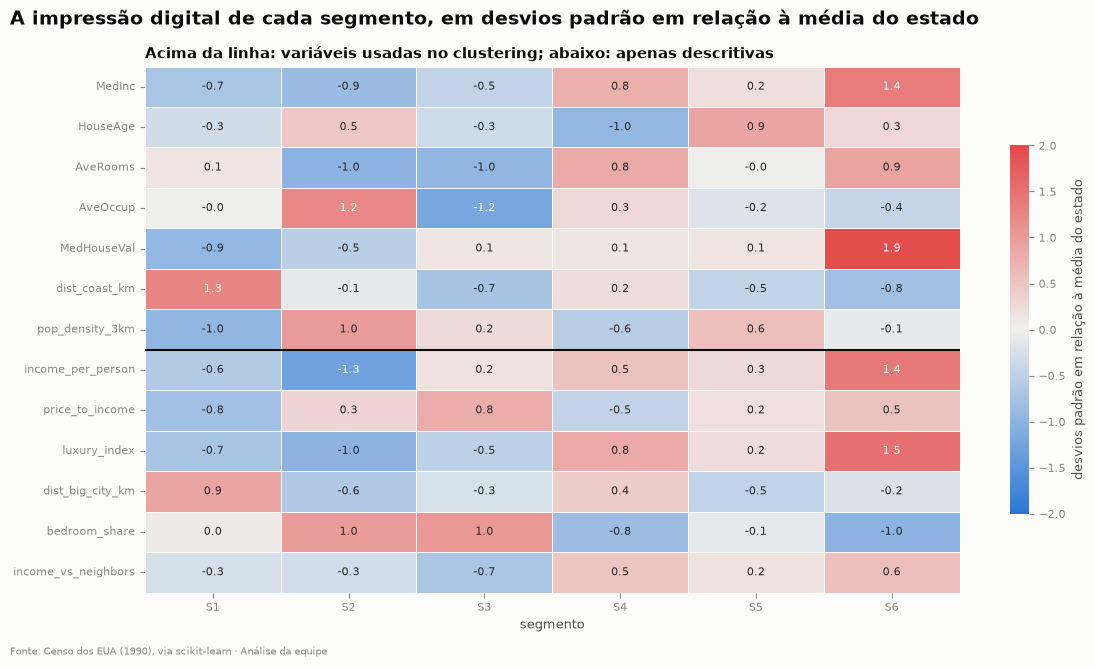

In [57]:
# Média de cada variável por segmento, em desvios padrão em relação ao estado
DESCRIBE_COLS = FINAL_FEATURES + ["income_per_person", "price_to_income", "luxury_index", "dist_big_city_km",
                                  "bedroom_share", "income_vs_neighbors"]
X_describe = pd.concat([X_candidates[FINAL_FEATURES],
                        X_candidates[[c for c in DESCRIBE_COLS if c not in FINAL_FEATURES]]], axis=1)
fingerprint = standardize(X_describe).groupby(segment).mean().T

fig, ax = plt.subplots(figsize=(1.3 * K_FINAL + 4, 6.5))
sns.heatmap(fingerprint.rename(columns=lambda s: f"S{s}"), cmap=DIVERGING, center=0, vmin=-2, vmax=2,
            annot=True, fmt=".1f", annot_kws={"fontsize": 8}, linewidths=0.5, linecolor=SURFACE, ax=ax,
            cbar_kws={"shrink": 0.7, "label": "desvios padrão em relação à média do estado"})
ax.axhline(len(FINAL_FEATURES), color=INK, linewidth=1.5)
ax.set_title("Acima da linha: variáveis usadas no clustering; abaixo: apenas descritivas")
ax.set_xlabel("segmento")
action_title(fig, "A impressão digital de cada segmento, em desvios padrão em relação à média do estado")
finish(fig)

## 8.3 Distribuição das variáveis em cada segmento

Os boxplots mostram não só o valor típico (a linha azul é a mediana), mas também a **variação interna** de cada segmento: caixas estreitas indicam um segmento homogêneo.

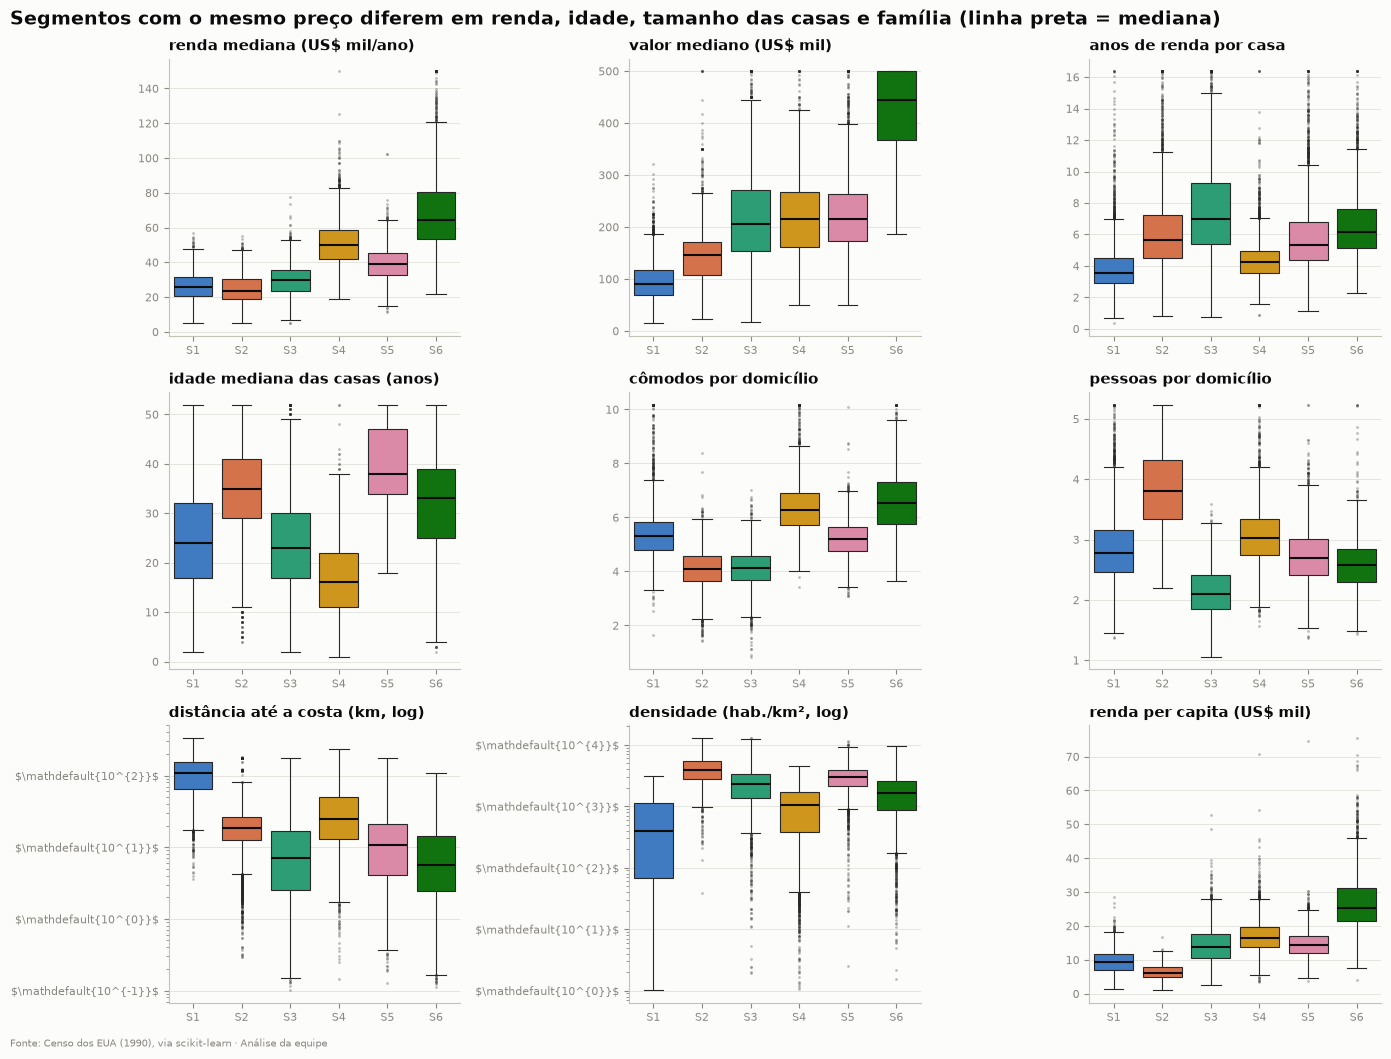

In [58]:
# Variável, fator de conversão para unidade natural, rótulo e uso de escala log
BOX_VARS = [("MedInc", 10, "renda mediana (US$ mil/ano)", False),
            ("MedHouseVal", 100, "valor mediano (US$ mil)", False),
            ("price_to_income", 1, "anos de renda por casa", False),
            ("HouseAge", 1, "idade mediana das casas (anos)", False),
            ("AveRooms", 1, "cômodos por domicílio", False),
            ("AveOccup", 1, "pessoas por domicílio", False),
            ("dist_coast_km", 1, "distância até a costa (km, log)", True),
            ("pop_density_3km", 1, "densidade (hab./km², log)", True),
            ("income_per_person", 1 / 1000, "renda per capita (US$ mil)", False)]
# Um boxplot por variável, com os segmentos lado a lado
long = seg.assign(seg_label=seg["segmento"].map(lambda s: f"S{s}"))
fig, axes = plt.subplots(3, 3, figsize=(14, 10.5))
for ax, (col, factor, label, log_scale) in zip(axes.flat, BOX_VARS):
    values = long[col] * factor
    if col in ["AveRooms", "AveOccup", "price_to_income"]:
        values = values.clip(upper=values.quantile(0.99))
    sns.boxplot(x=long["seg_label"], y=values + (0.1 if log_scale else 0), hue=long["seg_label"],
                palette={f"S{s}": SEG_COLOR[s] for s in SEGMENTS}, order=[f"S{s}" for s in SEGMENTS],
                ax=ax, linewidth=0.8, fliersize=1, legend=False, log_scale=log_scale,
                medianprops={"color": INK, "linewidth": 1.5}, flierprops={"alpha": 0.3})
    ax.set_title(label)
    ax.set_xlabel("")
    ax.set_ylabel("")
action_title(fig, "Segmentos com o mesmo preço diferem em renda, idade, tamanho das casas e família "
                  "(linha preta = mediana)")
finish(fig)

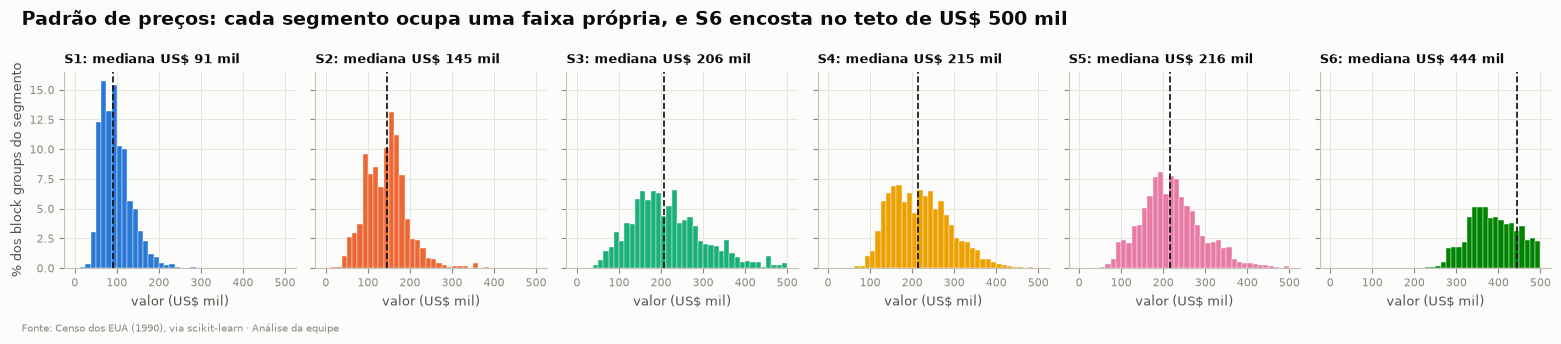

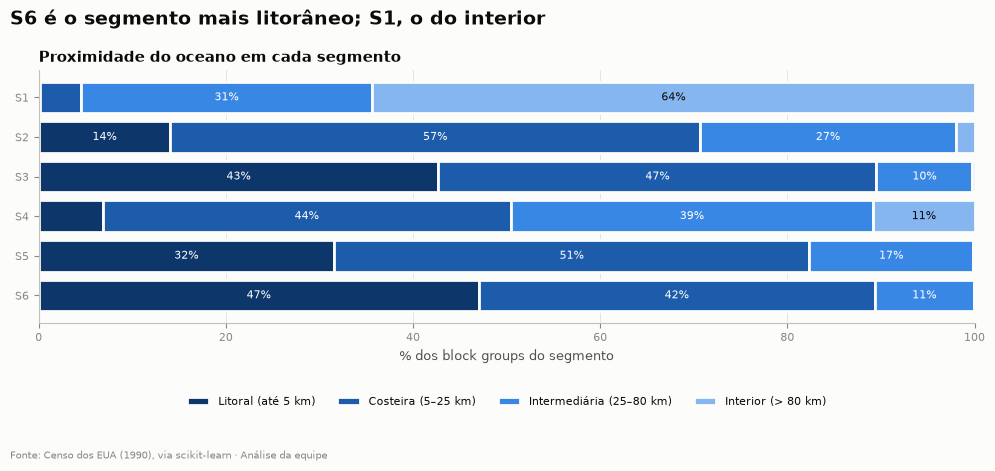

In [59]:
# Histograma do valor das casas em cada segmento (em % do segmento)
bins = np.linspace(0, 500, 41)
fig, axes = plt.subplots(1, K_FINAL, figsize=(2.6 * K_FINAL, 3.2), sharex=True, sharey=True)
for ax, s in zip(axes, SEGMENTS):
    values = seg.loc[seg["segmento"] == s, "MedHouseVal"] * 100
    ax.hist(values, bins=bins, color=SEG_COLOR[s], edgecolor=SURFACE, linewidth=0.3,
            weights=np.full(len(values), 100 / len(values)))
    ax.axvline(values.median(), color=INK, linewidth=1.2, linestyle="--")
    ax.set_title(f"S{s}: mediana US$ {br(values.median())} mil", fontsize=9)
    ax.set_xlabel("valor (US$ mil)")
axes[0].set_ylabel("% dos block groups do segmento")
action_title(fig, "Padrão de preços: cada segmento ocupa uma faixa própria, e S6 encosta no teto de US$ 500 mil")
finish(fig)

# Composição de cada segmento por faixa de distância até a costa
coastal_mix = pd.crosstab(segment, df_feat["coastal_class"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(10, 0.55 * K_FINAL + 1.2))
left = np.zeros(K_FINAL)
for coastal, color in zip(COASTAL_CLASSES, ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef"]):
    values = coastal_mix[coastal].to_numpy()
    ax.barh([f"S{s}" for s in SEGMENTS], values, left=left, color=color, edgecolor=SURFACE, linewidth=2,
            label=coastal)
    for i, (start, width) in enumerate(zip(left, values)):
        if width >= 8:
            ax.text(start + width / 2, i, f"{width:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if coastal != COASTAL_CLASSES[-1] else INK)
    left += values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% dos block groups do segmento")
ax.set_title("Proximidade do oceano em cada segmento")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=4)
most_coastal = int(coastal_mix[COASTAL_CLASSES[0]].idxmax())
most_inland = int(coastal_mix[COASTAL_CLASSES[-1]].idxmax())
action_title(fig, f"S{most_coastal} é o segmento mais litorâneo; S{most_inland}, o do interior")
finish(fig)

## 8.4 Os segmentos, um a um

Os nomes resumem o perfil de cada segmento. O painel abaixo mostra os seis lado a lado; em seguida, cada um é descrito em detalhe.

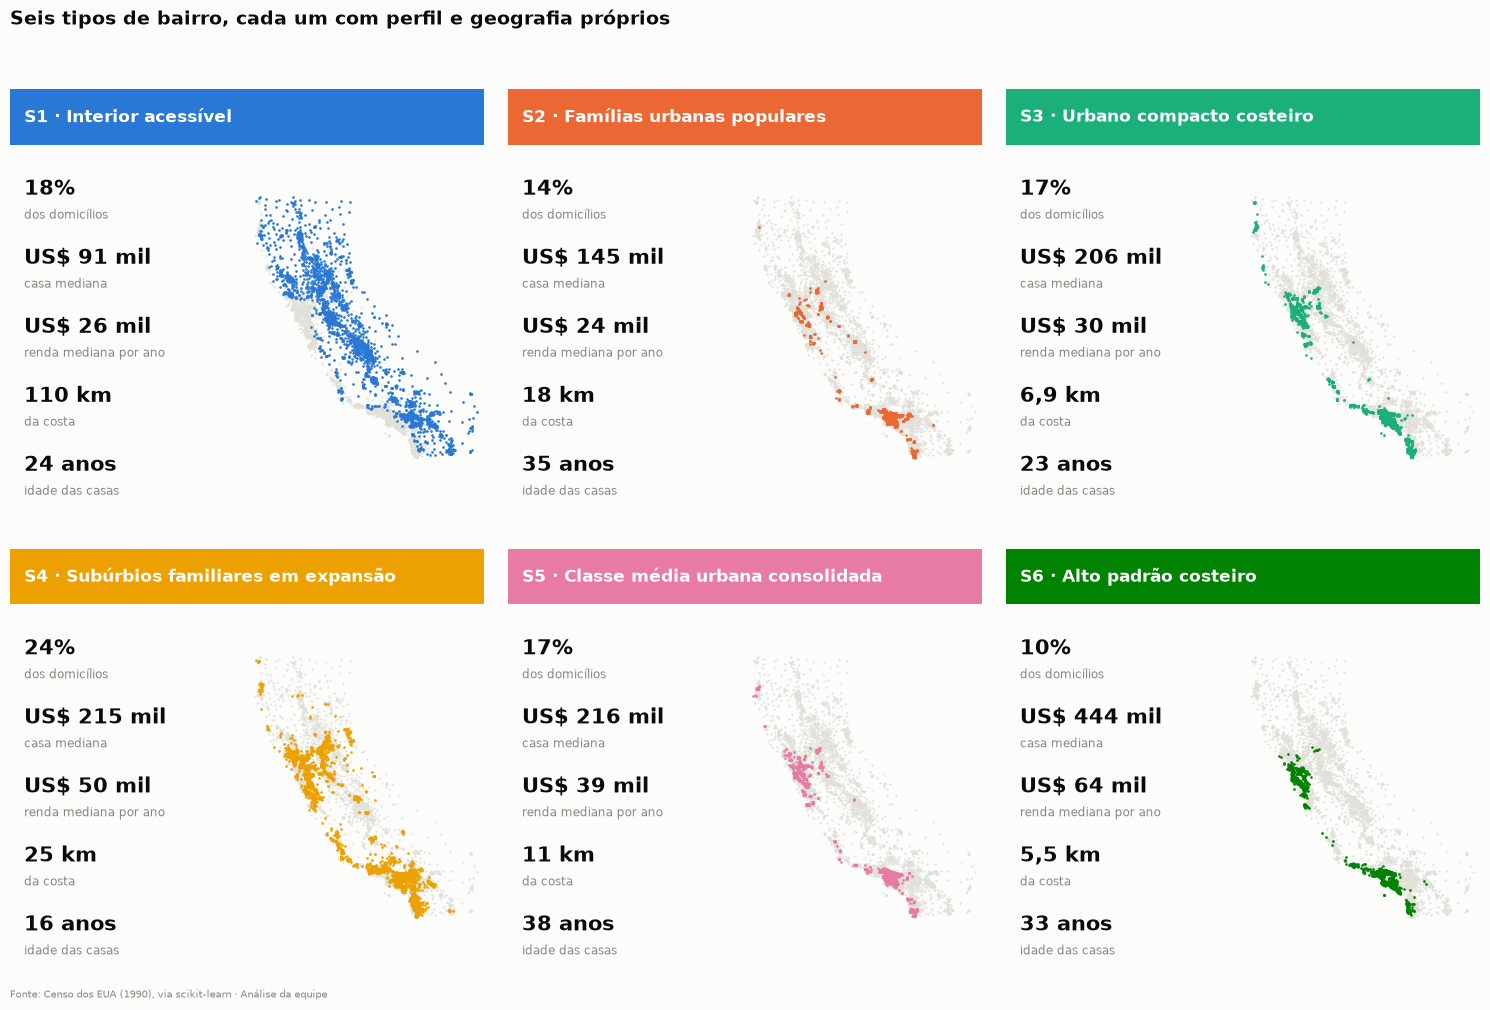

In [60]:
# Nomes de negócio dos segmentos, definidos a partir dos perfis acima
SEGMENT_NAMES = {
    1: "Interior acessível",
    2: "Famílias urbanas populares",
    3: "Urbano compacto costeiro",
    4: "Subúrbios familiares em expansão",
    5: "Classe média urbana consolidada",
    6: "Alto padrão costeiro",
}
segment_name = segment.map(SEGMENT_NAMES).rename("nome_segmento")
SEG_LABEL = {s: f"S{s} · {SEGMENT_NAMES[s]}" for s in SEGMENTS}
profile.insert(0, "nome", pd.Series(SEGMENT_NAMES))

# Painel executivo: um cartão por segmento, com os indicadores principais e um mini-mapa
fig = plt.figure(figsize=(15, 10))
cards = fig.add_gridspec(2, 3, left=0.01, right=0.99, top=0.9, bottom=0.03, hspace=0.12, wspace=0.05)
for i, s in enumerate(SEGMENTS):
    card = cards[i // 3, i % 3].subgridspec(2, 2, height_ratios=[0.16, 1], width_ratios=[1, 1], hspace=0.05,
                                            wspace=0.02)
    header, kpis, mini = fig.add_subplot(card[0, :]), fig.add_subplot(card[1, 0]), fig.add_subplot(card[1, 1])
    p = profile.loc[s]
    header.set_facecolor(SEG_COLOR[s])
    header.set_xticks([])
    header.set_yticks([])
    for spine in header.spines.values():
        spine.set_visible(False)
    header.text(0.03, 0.5, SEG_LABEL[s], color="white", fontsize=12, fontweight="bold", va="center",
                transform=header.transAxes)
    kpis.set_axis_off()
    indicators = [(f"{br(p['pct_domicilios'])}%", "dos domicílios"),
                  (f"US$ {br(p['valor_mediano_usd'] / 1000)} mil", "casa mediana"),
                  (f"US$ {br(p['renda_mediana_usd'] / 1000)} mil", "renda mediana por ano"),
                  (f"{br(p['dist_costa_km'], 1 if p['dist_costa_km'] < 10 else 0)} km", "da costa"),
                  (f"{br(p['idade_casas_anos'])} anos", "idade das casas")]
    for j, (value, label) in enumerate(indicators):
        y = 0.9 - j * 0.2
        kpis.text(0.06, y, value, fontsize=15, fontweight="bold", color=INK, va="center", transform=kpis.transAxes)
        kpis.text(0.06, y - 0.075, label, fontsize=8.5, color=GRAY, va="center", transform=kpis.transAxes)
    inside = segment == s
    mini.scatter(df_feat.loc[~inside, "Longitude"], df_feat.loc[~inside, "Latitude"], s=0.3, color="#e1e0d9")
    mini.scatter(df_feat.loc[inside, "Longitude"], df_feat.loc[inside, "Latitude"], s=0.8, color=SEG_COLOR[s])
    style_map(mini)
action_title(fig, "Seis tipos de bairro, cada um com perfil e geografia próprios")
finish(fig, tight=False)

Os números a seguir são medianas dos block groups de cada segmento.

---

### S1 · Interior acessível
**18,4% dos domicílios (1,9 milhão) · casas de US\$ 91 mil · renda de US\$ 26 mil**

- **Quem mora:** famílias de renda baixa a média, com 2,8 pessoas por domicílio.
- **Onde:** Vale Central e norte do estado, a **110 km da costa** (64% no interior profundo). Cidades de referência: Bakersfield, Fresno, Redding e Chico. O entorno é rural ou de cidades médias (395 hab./km²).
- **Imóvel:** casas de tamanho médio (5,3 cômodos), com 24 anos de idade mediana.
- **Preço:** o mais baixo do estado e o **mais acessível** (3,6 anos de renda). Preços concentrados entre US\$ 70 mil e US\$ 117 mil.
- **Em uma frase:** a casa própria acessível, longe do mar.

### S2 · Famílias urbanas populares
**14,0% dos domicílios (1,4 milhão), mas 5,5 milhões de pessoas · casas de US\$ 145 mil · renda de US\$ 24 mil**

- **Quem mora:** famílias grandes (**3,8 pessoas por domicílio**, a maior) e a menor renda per capita do estado (US\$ 6.200 por pessoa).
- **Onde:** **64% em Los Angeles County** (Los Angeles, Huntington Park, Inglewood), no entorno **mais denso** do estado (3.927 hab./km²), a 12 km de uma grande cidade.
- **Imóvel:** moradias pequenas (4,1 cômodos) e antigas (35 anos). Quase nenhuma construção nova (1,3%).
- **Preço:** US\$ 145 mil, ou 5,7 anos de renda. Comprar é difícil para quem mora lá.
- **Em uma frase:** muita gente em pouco espaço, nos bairros populares das metrópoles.

### S3 · Urbano compacto costeiro
**17,1% dos domicílios (1,8 milhão) · casas de US\$ 206 mil · renda de US\$ 30 mil**

- **Quem mora:** domicílios **pequenos (2,1 pessoas, o menor)**: solteiros, casais sem filhos, jovens profissionais e aposentados.
- **Onde:** a **7 km do mar** (43% a menos de 5 km), em Los Angeles (27%), na Baía de San Francisco (24%) e em San Diego (17%). Cidades de referência: San Diego, Santa Monica e Culver City.
- **Imóvel:** apartamentos e moradias compactas (4,1 cômodos, com a maior proporção de quartos sobre cômodos). Este segmento tem mais domicílios por block group que qualquer outro: são prédios.
- **Preço:** **o menos acessível: 7,0 anos de renda.** Quem mora ali, em boa parte, aluga.
- **Em uma frase:** morar pequeno perto do mar, pagando caro pela localização.

### S4 · Subúrbios familiares em expansão
**23,6% dos domicílios (2,4 milhões, o maior segmento) · casas de US\$ 215 mil · renda de US\$ 50 mil**

- **Quem mora:** famílias de renda média-alta (3,0 pessoas por domicílio).
- **Onde:** subúrbios a **25 km da costa** e 46 km de uma grande cidade, em todas as regiões (Baía, San Diego, Inland Empire, Central Coast). Cidades de referência: Santa Clarita, Poway, Simi Valley e Santa Rosa. O entorno é de baixa densidade (1.026 hab./km²).
- **Imóvel:** casas **grandes (6,3 cômodos) e novas (16 anos, a menor idade)**. **23% dos block groups têm casas de até 10 anos.**
- **Preço:** US\$ 215 mil, mas acessível para os moradores (4,2 anos de renda).
- **Em uma frase:** a casa grande e nova da família que trocou a cidade pelo subúrbio, onde o mercado está crescendo.

### S5 · Classe média urbana consolidada
**16,7% dos domicílios (1,7 milhão) · casas de US\$ 216 mil · renda de US\$ 39 mil**

- **Quem mora:** classe média (2,7 pessoas por domicílio).
- **Onde:** bairros tradicionais de Los Angeles (42%) e da Baía de San Francisco (34%), a 11 km do mar, em entorno denso (2.936 hab./km²). Cidades de referência: San Francisco, Daly City e Culver City.
- **Imóvel:** casas de tamanho médio (5,2 cômodos) e **as mais antigas (38 anos)**. **Nenhum block group com casas novas**: é um estoque totalmente consolidado.
- **Preço:** US\$ 216 mil, ou 5,3 anos de renda.
- **Em uma frase:** o bairro tradicional de casas antigas, onde o negócio é revenda e reforma.

### S6 · Alto padrão costeiro
**10,2% dos domicílios (1,0 milhão), mas 21% do valor do estoque · casas de US\$ 444 mil ou mais · renda de US\$ 64 mil**

- **Quem mora:** a maior renda (US\$ 64 mil por domicílio; US\$ 25 mil per capita, quatro vezes a de S2).
- **Onde:** **a 5,5 km do mar** (47% a menos de 5 km), na Baía de San Francisco (38%), em Los Angeles (35%) e em Orange County (12%). Cidades de referência: Santa Monica, San Rafael e Redondo Beach.
- **Imóvel:** **as maiores casas (6,5 cômodos)**, com 33 anos de idade mediana.
- **Preço:** mediana de US\$ 444 mil, e **38% no teto de US\$ 500 mil**: o preço real é maior do que os dados mostram.
- **Em uma frase:** o litoral de luxo das metrópoles.

## 8.5 Técnicas avançadas

### (a) Clusterização hierárquica: diferentes níveis de granularidade

Um gestor de marketing pode querer **poucos** grupos para a comunicação institucional e **mais** grupos para campanhas locais. Aplicamos o clustering hierárquico de Ward sobre os **centróides** dos segmentos, o que mostra quais segmentos são "primos" e como eles se juntam em macro-segmentos.

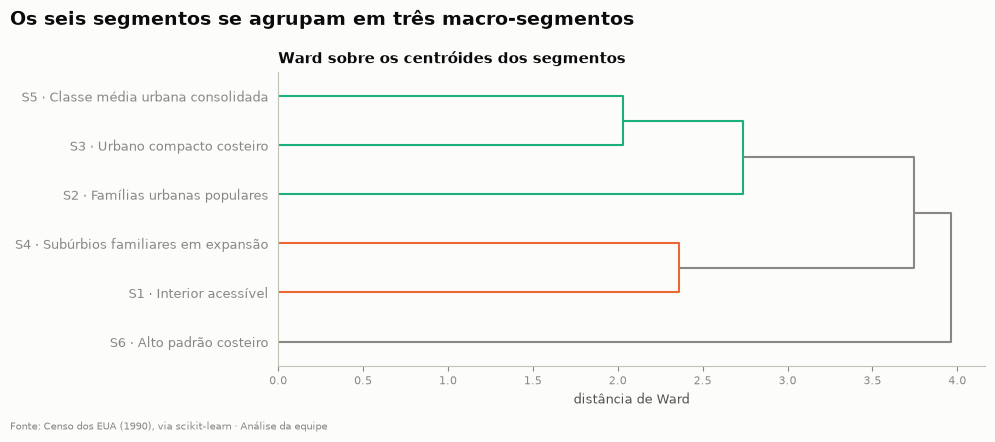

Macro-segmento,Segmento,% dos domicílios
1,S1 · Interior acessível,"18,4%"
1,S4 · Subúrbios familiares em expansão,"23,6%"
2,S2 · Famílias urbanas populares,"14,0%"
2,S3 · Urbano compacto costeiro,"17,1%"
2,S5 · Classe média urbana consolidada,"16,7%"
3,S6 · Alto padrão costeiro,"10,2%"


In [61]:
# Ward sobre os centróides: mostra quais segmentos são parecidos entre si
centroid_links = linkage(centroids.to_numpy(), method="ward")

fig, ax = plt.subplots(figsize=(10, 4.2))
dendrogram(centroid_links, labels=[SEG_LABEL[s] for s in SEGMENTS], orientation="right", ax=ax,
           color_threshold=centroid_links[-2, 2] * 0.999, above_threshold_color=GRAY, leaf_font_size=9)
ax.set_title("Ward sobre os centróides dos segmentos")
ax.set_xlabel("distância de Ward")
ax.grid(False)
action_title(fig, "Os seis segmentos se agrupam em três macro-segmentos")
finish(fig)

# Corte em 3 macro-segmentos
macro = pd.Series(fcluster(centroid_links, t=3, criterion="maxclust"), index=SEGMENTS, name="macro_segmento")
macro_table = (pd.DataFrame({"macro_segmento": macro, "segmento": [SEG_LABEL[s] for s in SEGMENTS],
                             "pct_domicilios": profile["pct_domicilios"].round(1)})
               .sort_values("macro_segmento"))
exec_table(macro_table, formats={"macro_segmento": "int", "pct_domicilios": "pct"},
           labels={"macro_segmento": "Macro-segmento", "segmento": "Segmento", "pct_domicilios": "% dos domicílios"})

**Três macro-segmentos**, úteis para a comunicação institucional e para a estrutura das equipes:

| Macro-segmento | Segmentos | Domicílios | O que os une |
|---|---|---|---|
| **1. Casas fora dos centros** | S1 e S4 | 42% | casas espaçosas, longe do mar e dos centros; a diferença é a renda |
| **2. Núcleo urbano** | S2, S3 e S5 | 48% | bairros densos e consolidados das metrópoles; a diferença é o perfil do domicílio |
| **3. Alto padrão** | S6 | 10% | um mercado à parte, distante de todos os outros |

**Os níveis de granularidade ficam claros:**

- **3 macro-segmentos** para a estratégia corporativa;
- **6 segmentos** para marketing e alocação de equipes;
- **subsegmentos** (abaixo) para campanhas locais.

### (b) Clusterização recursiva: subsegmentos dentro de um segmento

Escolhemos o segmento **mais heterogêneo** entre os grandes (menor silhouette média entre os que têm pelo menos 12% dos block groups) e aplicamos o K-Means **dentro dele**. Isso responde a uma pergunta prática: *vale a pena tratar esse segmento como um bloco único, ou ele esconde mercados diferentes?*

Segmento analisado: S3 · Urbano compacto costeiro (2.635 block groups)
Melhor número de subsegmentos pela silhouette: 2


k,2,3,4,5
silhouette,0.199,0.176,0.172,0.153


Subsegmento,Block groups,Renda mediana,Valor mediano,Idade das casas,Cômodos,Pessoas/domicílio,Distância da costa,Densidade (hab./km²)
S3.1,1.740,US$ 31 mil,US$ 186 mil,19,"4,3","2,2","9,2 km",2.026
S3.2,895,US$ 27 mil,US$ 272 mil,33,"3,7","1,9","3,9 km",2.946


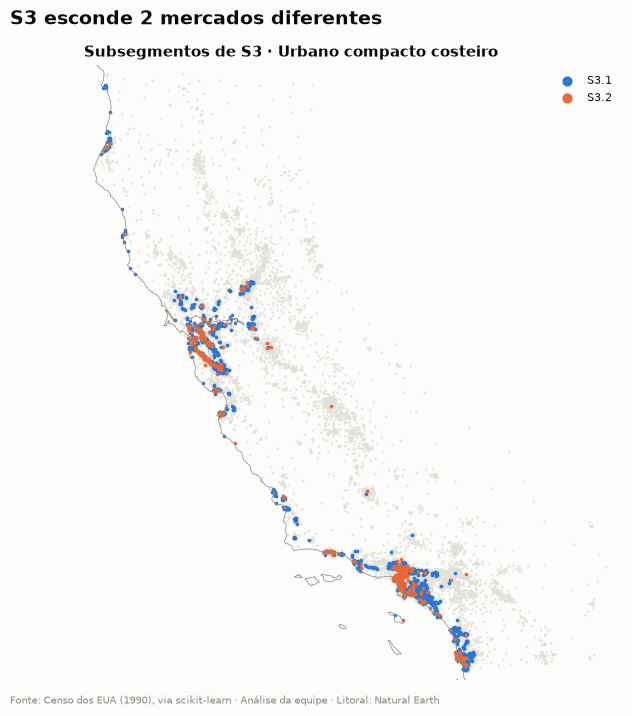

In [62]:
# Segmento mais heterogêneo entre os grandes (>= 12% dos block groups): menor silhouette média
large = separation[separation["block_groups"] >= 0.12 * len(Z)]
target_segment = int(large["silhouette_media"].idxmin())
inside = segment == target_segment
Z_inside = Z[inside]

# Número de subsegmentos escolhido pela silhouette dentro do segmento
sub_rows = []
for k in range(2, 6):
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z_inside)
    sub_rows.append({"k": k, "silhouette": silhouette_score(Z_inside, labels, sample_size=6_000,
                                                            random_state=RANDOM_STATE)})
sub_scores = pd.DataFrame(sub_rows).set_index("k")
K_SUB = int(sub_scores["silhouette"].idxmax())
print(f"Segmento analisado: {SEG_LABEL[target_segment]} ({br(inside.sum())} block groups)")
print(f"Melhor número de subsegmentos pela silhouette: {K_SUB}")
display(sub_scores.round(3).T)

# Subsegmentos numerados pelo valor mediano das casas
sub_model = KMeans(n_clusters=K_SUB, n_init=10, random_state=RANDOM_STATE).fit(Z_inside)
sub_order = df_feat.loc[inside, "MedHouseVal"].groupby(sub_model.labels_).median().sort_values().index
sub_label = pd.Series(sub_model.labels_, index=Z_inside.index).map(
    {old: f"S{target_segment}.{new}" for new, old in enumerate(sub_order, start=1)})

# Perfil dos subsegmentos em unidades naturais
sub_profile = (seg.loc[inside].groupby(sub_label)
               .agg(block_groups=("MedInc", "size"),
                    renda_mediana_usd=("MedInc", lambda s: 10_000 * s.median()),
                    valor_mediano_usd=("MedHouseVal", lambda s: 100_000 * s.median()),
                    idade_casas_anos=("HouseAge", "median"),
                    comodos=("AveRooms", "median"),
                    pessoas_por_domicilio=("AveOccup", "median"),
                    dist_costa_km=("dist_coast_km", "median"),
                    densidade_hab_km2=("pop_density_3km", "median")))
display(exec_table(sub_profile.reset_index(names="subsegmento"),
                   formats={"block_groups": "int", "renda_mediana_usd": "usd_mil", "valor_mediano_usd": "usd_mil",
                            "idade_casas_anos": "int", "comodos": "dec1", "pessoas_por_domicilio": "dec1",
                            "dist_costa_km": "km", "densidade_hab_km2": "int"},
                   labels={"subsegmento": "Subsegmento", "block_groups": "Block groups",
                           "renda_mediana_usd": "Renda mediana", "valor_mediano_usd": "Valor mediano",
                           "idade_casas_anos": "Idade das casas", "comodos": "Cômodos",
                           "pessoas_por_domicilio": "Pessoas/domicílio", "dist_costa_km": "Distância da costa",
                           "densidade_hab_km2": "Densidade (hab./km²)"}))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(df_feat.loc[~inside, "Longitude"], df_feat.loc[~inside, "Latitude"], s=0.5, color="#e1e0d9")
for i, name in enumerate(sorted(sub_label.unique())):
    sel = sub_label[sub_label == name].index
    ax.scatter(df_feat.loc[sel, "Longitude"], df_feat.loc[sel, "Latitude"], s=2.5, color=PALETTE[i], label=name)
coast.plot(ax=ax, color=GRAY, linewidth=0.5)
style_map(ax, f"Subsegmentos de {SEG_LABEL[target_segment]}")
ax.legend(loc="upper right", markerscale=4)
action_title(fig, f"S{target_segment} esconde {K_SUB} mercados diferentes")
finish(fig, SOURCE_NOTE + " · Litoral: Natural Earth")

**S3 esconde dois mercados.** Dentro dele, a silhouette com 2 subsegmentos é de **0,20**, o dobro da silhouette de S3 na segmentação geral (0,10):

| | S3.1 · Compactos novos | S3.2 · Apartamentos à beira-mar |
|---|---|---|
| Block groups | 1.740 | 895 |
| Idade das casas | 19 anos | 33 anos |
| Distância da costa | 9 km | **4 km** |
| Valor mediano | US\$ 186 mil | **US\$ 273 mil** |
| Renda mediana | US\$ 31 mil | US\$ 27 mil |
| Pessoas por domicílio | 2,2 | 1,9 |

- **S3.1:** condomínios e apartamentos mais novos, espalhados pelas regiões metropolitanas, com preço moderado.
- **S3.2:** apartamentos antigos colados ao mar, concentrados em San Francisco, no oeste de Los Angeles e no litoral de San Diego. São caríssimos para a renda de quem mora lá (10 anos de renda): **mercado de aluguel e de investidores**.

**Recomendação:** tratar S3 com **duas ofertas**. Em S3.1, o foco é o primeiro imóvel próprio; em S3.2, o foco é a gestão de aluguel e o investidor.

### (c) Ensemble de clustering: o núcleo estável e as zonas de transição

Combinamos os três algoritmos que segmentam todo o mercado (K-Means, GMM e Ward). Como cada algoritmo numera seus grupos de forma arbitrária, primeiro **alinhamos os rótulos** ao K-Means com o algoritmo húngaro (que encontra a correspondência de máxima sobreposição). Depois, cada block group recebe um **voto de consenso**:

- **Núcleo estável (3 de 3):** os três algoritmos concordam. São os block groups que representam o segmento "puro".
- **Confirmado pela maioria (2 de 3):** um algoritmo discorda, mas a maioria confirma o segmento do K-Means.
- **Contestado (só o K-Means):** os outros dois algoritmos discordam do K-Means. São bairros na fronteira entre dois segmentos, que podem migrar com o tempo.

Nível de concordância,% dos block groups
núcleo estável (3 de 3),"51,4%"
confirmado pela maioria (2 de 3),"42,1%"
contestado (só o K-Means),"6,5%"


Segmento,núcleo estável (3 de 3),confirmado pela maioria (2 de 3),contestado (só o K-Means),Concordância do GMM,Concordância do Ward
S1 · Interior acessível,"69,3%","29,7%","1,0%","69,6%","98,7%"
S2 · Famílias urbanas populares,"59,1%","39,0%","1,9%","59,5%","97,8%"
S3 · Urbano compacto costeiro,"59,4%","30,3%","10,2%","66,1%","83,1%"
S4 · Subúrbios familiares em expansão,"10,2%","77,9%","11,9%","13,9%","84,3%"
S5 · Classe média urbana consolidada,"47,7%","41,7%","10,6%","59,5%","77,7%"
S6 · Alto padrão costeiro,"76,8%","21,3%","1,9%","83,8%","91,1%"


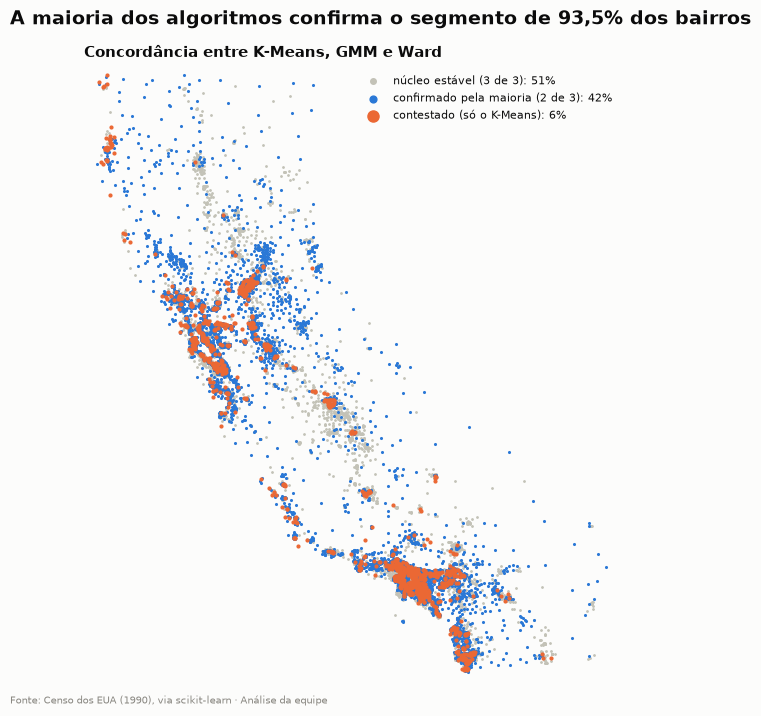

In [63]:
def align_to_segments(labels):
    """Renomeia os rótulos de outro algoritmo para o segmento do K-Means com maior sobreposição."""
    table = pd.crosstab(pd.Series(labels, index=Z.index), segment)
    rows, cols = linear_sum_assignment(-table.to_numpy())
    mapping = {table.index[r]: table.columns[c] for r, c in zip(rows, cols)}
    return pd.Series(labels, index=Z.index).map(mapping)


# Rótulos dos três algoritmos alinhados à numeração do K-Means
votes = pd.DataFrame({"kmeans": segment, "gmm": align_to_segments(gmm_labels),
                      "ward": align_to_segments(ward_labels)})
support = (votes[["gmm", "ward"]].eq(segment, axis=0)).sum(axis=1) + 1     # algoritmos que concordam com o K-Means
AGREEMENT_LEVELS = {3: "núcleo estável (3 de 3)", 2: "confirmado pela maioria (2 de 3)", 1: "contestado (só o K-Means)"}
agreement_level = support.map(AGREEMENT_LEVELS)
agreement = support == 3

# Nível de concordância por segmento e concordância de cada algoritmo com o K-Means
ensemble = (pd.crosstab(segment, agreement_level, normalize="index")[list(AGREEMENT_LEVELS.values())] * 100).rename_axis(columns=None)
ensemble["concordancia_GMM_pct"] = 100 * (votes["gmm"] == segment).groupby(segment).mean()
ensemble["concordancia_Ward_pct"] = 100 * (votes["ward"] == segment).groupby(segment).mean()
ensemble = ensemble.rename(index=SEG_LABEL)
display(exec_table(agreement_level.value_counts(normalize=True).mul(100).rename("pct").reset_index(),
                   formats={"pct": "pct"}, labels={"index": "Nível de concordância", "pct": "% dos block groups"}))
display(exec_table(ensemble.reset_index(names="segmento"),
                   formats={c: "pct" for c in ensemble.columns},
                   labels={"segmento": "Segmento", "concordancia_GMM_pct": "Concordância do GMM",
                           "concordancia_Ward_pct": "Concordância do Ward"},
                   highlight=AGREEMENT_LEVELS[3]))

fig, ax = plt.subplots(figsize=(7, 7))
for level, color, size in [(3, LIGHT_GRAY, 1), (2, BLUE, 1.5), (1, ORANGE, 4)]:
    sel = support == level
    ax.scatter(df_feat.loc[sel, "Longitude"], df_feat.loc[sel, "Latitude"], s=size, color=color,
               label=f"{AGREEMENT_LEVELS[level]}: {br(100 * sel.mean())}%")
style_map(ax, "Concordância entre K-Means, GMM e Ward")
ax.legend(loc="upper right", markerscale=4)
action_title(fig, f"A maioria dos algoritmos confirma o segmento de {br(100 * (support >= 2).mean(), 1)}% dos bairros")
finish(fig)

**A segmentação do K-Means é confirmada pela maioria dos algoritmos em 93,5% dos block groups:**

- **51,4% formam o núcleo estável:** os três algoritmos concordam.
- **42,1% são confirmados pela maioria:** quase sempre é o GMM que discorda, sozinho. Isso é coerente com a sua silhouette baixa (seção 6.6). O Ward concorda com o K-Means em 78% a 99% dos block groups de cada segmento.
- **Só 6,5% são contestados**, com GMM e Ward discordando do K-Means. Estes são os **bairros de transição**.

**Por segmento:**

- **S6, S1 e S2 são os mais sólidos:** de 1% a 2% contestados, e núcleos estáveis de 77%, 69% e 59%.
- **S4, S5 e S3 têm as fronteiras mais difusas:** cerca de 10% a 12% contestados.
- **S4 tem só 10% de núcleo estável:** o GMM o divide de outra forma (concorda em apenas 14%), mas o Ward concorda em 84%. **S4 é amplo e merece sub-segmentação**, assim como S3.

**Uso prático:** os bairros contestados são os primeiros a **migrar de segmento** quando o bairro muda, por exemplo com uma valorização ou com a chegada de novas famílias. Eles devem receber comunicação mista e monitoramento a cada atualização dos dados. A coluna `concordancia_algoritmos` do arquivo exportado identifica cada um deles.

> **Insight** · S3, S4 e S5 custam o mesmo (cerca de US\$ 210 mil) e são clientes opostos.
>
> **Decisão** · Três níveis de granularidade: 3 macro-segmentos, 6 segmentos e subsegmentos onde o segmento esconde mercados diferentes.
>
> **Para o negócio** · Os bairros contestados (6,5%) são os primeiros a mudar de segmento e merecem monitoramento.

---
# 9. Estratégias de Negócio por Segmento

Descrever os segmentos não basta: precisamos transformar esse conhecimento em **ações concretas**. Esta seção constrói, a partir dos dados, os indicadores de que um comitê de investimento e marketing precisa para decidir onde e como atuar.

## 9.1 Tamanho de mercado

In [64]:
# Tamanho de mercado: domicílios, população e valor estimado do estoque (domicílios x valor mediano)
seg["valor_estoque_usd"] = seg["households"] * seg["MedHouseVal"] * 100_000
market = pd.DataFrame({
    "segmento": [SEG_LABEL[s] for s in SEGMENTS],
    "domicilios": grouped["households"].sum().round(),
    "pct_domicilios": profile["pct_domicilios"],
    "populacao": grouped["Population"].sum(),
    "valor_estoque_usd_bi": seg.groupby("segmento")["valor_estoque_usd"].sum() / 1e9,
}).set_index("segmento")
market["pct_valor_estoque"] = 100 * market["valor_estoque_usd_bi"] / market["valor_estoque_usd_bi"].sum()
exec_table(market.reset_index(),
           formats={"domicilios": "int", "pct_domicilios": "pct", "populacao": "int",
                    "valor_estoque_usd_bi": "usd_bi", "pct_valor_estoque": "pct"},
           labels={"segmento": "Segmento", "domicilios": "Domicílios", "pct_domicilios": "% dos domicílios",
                   "populacao": "População", "valor_estoque_usd_bi": "Valor do estoque",
                   "pct_valor_estoque": "% do valor"},
           highlight="pct_valor_estoque", caption="Tamanho de mercado de cada segmento (valores de 1990)")

Segmento,Domicílios,% dos domicílios,População,Valor do estoque,% do valor
S1 · Interior acessível,1.895.590,"18,4%",5.360.418,"US$ 189,5 bi","8,6%"
S2 · Famílias urbanas populares,1.447.166,"14,0%",5.520.490,"US$ 218,6 bi","10,0%"
S3 · Urbano compacto costeiro,1.764.629,"17,1%",3.762.312,"US$ 404,0 bi","18,4%"
S4 · Subúrbios familiares em expansão,2.428.166,"23,6%",7.359.428,"US$ 536,1 bi","24,5%"
S5 · Classe média urbana consolidada,1.720.333,"16,7%",4.655.212,"US$ 392,6 bi","17,9%"
S6 · Alto padrão costeiro,1.049.715,"10,2%",2.665.923,"US$ 451,1 bi","20,6%"


- **O mercado total tem 10,3 milhões de domicílios e um estoque estimado em US\$ 2,2 trilhões** (valores de 1990).
- **S4 é o maior mercado** nas duas medidas: 23,6% dos domicílios e 24,5% do valor.
- **S6 tem só 10,2% dos domicílios, mas 20,6% do valor do estoque.** Cada transação vale, em média, mais que o dobro da dos demais segmentos.
- **S1 e S2 juntos têm 32% dos domicílios, mas só 19% do valor.** São mercados de volume, e não de valor.

**Implicação:** a imobiliária precisa decidir entre **volume** (S1, S2, S4) e **valor por transação** (S6, S3, S5). Os segmentos permitem fazer essa escolha de forma explícita.

## 9.2 Oportunidades de investimento: crescimento e subvalorização

**Crescimento.** Os dados são uma fotografia de 1990, sem série histórica. Usamos como indicador de crescimento a **participação de block groups com casas de até 10 anos**: onde se construiu muito recentemente, há expansão urbana, demanda nova e terrenos sendo incorporados.

**Áreas subvalorizadas.** Para cada block group, estimamos o **valor esperado** das casas a partir das suas características (renda, idade, tamanho, ocupação, distância da costa, densidade, acesso a grandes cidades e localização), com um modelo de *gradient boosting*. Cada previsão é feita **sem que o modelo tenha visto aquele block group** (validação cruzada em 5 partes). Um block group cujo valor real está **20% ou mais abaixo do esperado** é marcado como **subvalorizado**: tem fundamentos de um bairro mais caro, mas preço de um mais barato. Block groups no teto de US\$ 500 mil ficam fora dessa marcação, porque o valor real deles é desconhecido.

> Este é o único passo supervisionado do projeto. Ele não altera os segmentos: é uma ferramenta de apoio para priorizar oportunidades **dentro** deles.

In [65]:
# Modelo de valor esperado: gradient boosting com previsão fora da amostra (validação cruzada em 5 partes)
VALUE_MODEL_FEATURES = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "AveOccup", "Population",
                        "dist_coast_km", "pop_density_3km", "dist_big_city_km", "Latitude", "Longitude"]
value_model = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, random_state=RANDOM_STATE)
log_value = np.log(df_feat["MedHouseVal"])
predicted_log = cross_val_predict(value_model, df_feat[VALUE_MODEL_FEATURES], log_value,
                                  cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))
print(f"Qualidade do modelo de valor esperado (R², validação cruzada): {r2_score(log_value, predicted_log):.3f}")

# Razão entre preço real e esperado; subvalorizado = 20% ou mais abaixo do esperado (fora do teto)
seg["valor_esperado_usd"] = np.exp(predicted_log) * 100_000
seg["preco_vs_esperado"] = seg["MedHouseVal"] * 100_000 / seg["valor_esperado_usd"]
seg["subvalorizado"] = (seg["preco_vs_esperado"] <= 0.8) & ~seg["no_teto"]
seg["sobrevalorizado"] = (seg["preco_vs_esperado"] >= 1.25) & ~seg["no_teto"]

# Indicadores de crescimento, oportunidade e risco de preço por segmento
opportunity = pd.DataFrame({
    "segmento": [SEG_LABEL[s] for s in SEGMENTS],
    "pct_casas_ate_10_anos": profile["pct_casas_ate_10_anos"],
    "pct_subvalorizados": 100 * seg.groupby("segmento")["subvalorizado"].mean(),
    "domicilios_em_areas_subvalorizadas": seg[seg["subvalorizado"]].groupby("segmento")["households"].sum().reindex(SEGMENTS, fill_value=0).round(),
    "pct_sobrevalorizados": 100 * seg.groupby("segmento")["sobrevalorizado"].mean(),
    "anos_de_renda_por_casa": profile["anos_de_renda_por_casa"],
    "dispersao_preco_IQR_sobre_mediana": (profile["valor_p75_usd"] - profile["valor_p25_usd"]) / profile["valor_mediano_usd"],
    "pct_no_teto_500k": profile["pct_no_teto_500k"],
}).set_index("segmento")
exec_table(opportunity.reset_index(),
           formats={"pct_casas_ate_10_anos": "pct", "pct_subvalorizados": "pct",
                    "domicilios_em_areas_subvalorizadas": "int", "pct_sobrevalorizados": "pct",
                    "anos_de_renda_por_casa": "dec1", "dispersao_preco_IQR_sobre_mediana": "dec2",
                    "pct_no_teto_500k": "pct"},
           labels={"segmento": "Segmento", "pct_casas_ate_10_anos": "Casas de até 10 anos",
                   "pct_subvalorizados": "Subvalorizados",
                   "domicilios_em_areas_subvalorizadas": "Domicílios em áreas subvalorizadas",
                   "pct_sobrevalorizados": "Sobrevalorizados", "anos_de_renda_por_casa": "Anos de renda por casa",
                   "dispersao_preco_IQR_sobre_mediana": "Dispersão de preço (IQR ÷ mediana)",
                   "pct_no_teto_500k": "No teto de US$ 500 mil"},
           highlight="pct_subvalorizados")

Qualidade do modelo de valor esperado (R², validação cruzada): 0.870


Segmento,Casas de até 10 anos,Subvalorizados,Domicílios em áreas subvalorizadas,Sobrevalorizados,Anos de renda por casa,Dispersão de preço (IQR ÷ mediana),No teto de US$ 500 mil
S1 · Interior acessível,"7,9%","11,5%",167.327,"10,3%","3,6","0,51","0,0%"
S2 · Famílias urbanas populares,"1,3%","6,7%",103.072,"6,5%","5,7","0,43","0,1%"
S3 · Urbano compacto costeiro,"7,7%","16,3%",279.590,"14,3%","7,0","0,57","2,1%"
S4 · Subúrbios familiares em expansão,"23,0%","7,6%",147.409,"8,6%","4,2","0,49","0,3%"
S5 · Classe média urbana consolidada,"0,0%","6,4%",94.823,"6,1%","5,3","0,42","0,6%"
S6 · Alto padrão costeiro,"3,1%","1,6%",16.958,"8,4%","6,2","0,30","38,0%"


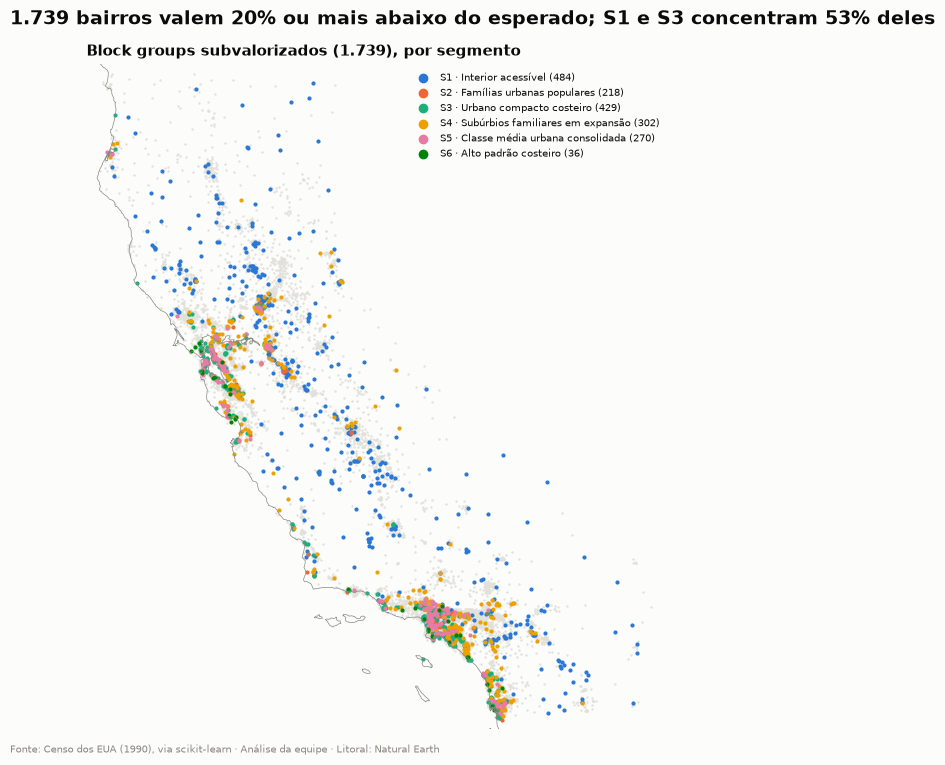

In [66]:
# Mapa dos block groups subvalorizados, coloridos pelo segmento
fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.scatter(df_feat["Longitude"], df_feat["Latitude"], s=0.5, color="#e1e0d9")
under = seg[seg["subvalorizado"]]
for s in SEGMENTS:
    sel = under[under["segmento"] == s]
    ax.scatter(sel["Longitude"], sel["Latitude"], s=4, color=SEG_COLOR[s], label=f"{SEG_LABEL[s]} ({br(len(sel))})")
coast.plot(ax=ax, color=GRAY, linewidth=0.5)
style_map(ax, f"Block groups subvalorizados ({br(len(under))}), por segmento")
ax.legend(loc="upper right", markerscale=3, fontsize=7)
counts = under["segmento"].value_counts()
top_share = 100 * counts.iloc[:2].sum() / len(under)
action_title(fig, f"{br(len(under))} bairros valem 20% ou mais abaixo do esperado; "
                  f"S{counts.index[0]} e S{counts.index[1]} concentram {br(top_share)}% deles")
finish(fig, SOURCE_NOTE + " · Litoral: Natural Earth")

- **O modelo de valor esperado é confiável:** R² de 0,87 na validação cruzada. A diferença entre preço real e esperado é informativa, e não ruído do modelo.
- **Cerca de 1.700 block groups (8,5%) estão subvalorizados**, com preço 20% ou mais abaixo do que os seus fundamentos indicam.
- **S3 tem a maior oportunidade:** **16% dos seus block groups estão subvalorizados** (cerca de 280 mil domicílios), em San Diego, Burbank e Culver City. É também o segmento com a maior dispersão de preço (IQR de 57% da mediana) e com mais casos sobrevalorizados (14%). Os preços de S3 ainda não se ajustaram aos fundamentos.
- **S1 vem em segundo** (cerca de 12%, em Redding, Bakersfield e Yuba City): cidades do interior com fundamentos melhores que o preço.
- **S4 combina crescimento com oportunidade:** 23% de casas novas e cerca de 8% de subvalorizados.
- **S6 quase não tem subvalorizados (menos de 2%)**, mas isso é em parte um efeito do teto: o preço real de 38% dos seus block groups é desconhecido.

> **Atenção:** "cidade de referência" é a cidade mais próxima numa lista das maiores cidades do estado. Em Los Angeles, nomes como Burbank e Culver City representam bairros vizinhos a essas cidades, e não só os seus limites oficiais.

## 9.3 Matriz de priorização

Combinamos quatro critérios, cada um normalizado de 0 a 1 entre os segmentos:

| Critério | Medida | Por que importa |
|---|---|---|
| **Crescimento** | % de block groups com casas de até 10 anos | demanda nova e lançamentos |
| **Oportunidade de preço** | % de block groups subvalorizados | espaço para valorização e captação de imóveis |
| **Tamanho em clientes** | número de domicílios | alcance de marketing e volume de transações |
| **Tamanho em valor** | valor estimado do estoque (US\$) | a comissão é proporcional ao preço: receita potencial |

O **índice de atratividade** é a média simples dos quatro, sem pesos escolhidos a dedo.

Segmento,Crescimento,Oportunidade de preço,Tamanho em clientes,Tamanho em valor,Índice de atratividade
S4 · Subúrbios familiares em expansão,"1,00","0,41","1,00","1,00","0,85"
S3 · Urbano compacto costeiro,"0,34","1,00","0,52","0,62","0,62"
S1 · Interior acessível,"0,35","0,68","0,61","0,00","0,41"
S5 · Classe média urbana consolidada,"0,00","0,33","0,49","0,59","0,35"
S6 · Alto padrão costeiro,"0,13","0,00","0,00","0,75","0,22"
S2 · Famílias urbanas populares,"0,06","0,35","0,29","0,08","0,19"


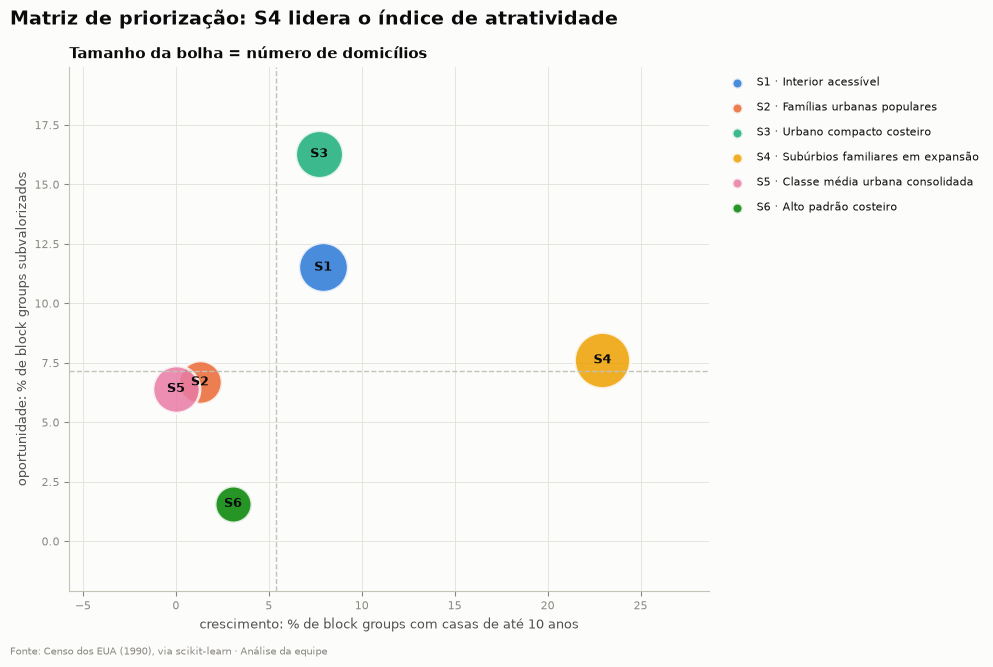

In [67]:
# Normaliza um critério para a faixa 0 a 1 entre os segmentos
def minmax(series):
    return (series - series.min()) / (series.max() - series.min())


# Índice de atratividade = média simples dos quatro critérios normalizados
priority = pd.DataFrame({
    "crescimento": minmax(opportunity["pct_casas_ate_10_anos"]),
    "oportunidade_de_preco": minmax(opportunity["pct_subvalorizados"]),
    "tamanho_em_clientes": minmax(market["domicilios"]),
    "tamanho_em_valor": minmax(market["valor_estoque_usd_bi"]),
})
priority["indice_atratividade"] = priority.mean(axis=1)
priority = priority.sort_values("indice_atratividade", ascending=False)
display(exec_table(priority.reset_index(),
                   formats={c: "dec2" for c in priority.columns},
                   labels={"segmento": "Segmento", "crescimento": "Crescimento",
                           "oportunidade_de_preco": "Oportunidade de preço", "tamanho_em_clientes": "Tamanho em clientes",
                           "tamanho_em_valor": "Tamanho em valor", "indice_atratividade": "Índice de atratividade"},
                   highlight="indice_atratividade"))

# Matriz de priorização: crescimento x oportunidade, bolha proporcional aos domicílios
fig, ax = plt.subplots(figsize=(10, 6.5))
for s in SEGMENTS:
    name = SEG_LABEL[s]
    x, y = opportunity.loc[name, "pct_casas_ate_10_anos"], opportunity.loc[name, "pct_subvalorizados"]
    ax.scatter(x, y, s=market.loc[name, "domicilios"] / 1_500, color=SEG_COLOR[s], alpha=0.85,
               edgecolor=SURFACE, linewidth=2, label=name)
    ax.annotate(f"S{s}", (x, y), ha="center", va="center", fontsize=9, fontweight="bold", color=INK)
ax.axvline(opportunity["pct_casas_ate_10_anos"].median(), color=LIGHT_GRAY, linestyle="--", linewidth=1)
ax.axhline(opportunity["pct_subvalorizados"].median(), color=LIGHT_GRAY, linestyle="--", linewidth=1)
ax.set_title("Tamanho da bolha = número de domicílios")
ax.set_xlabel("crescimento: % de block groups com casas de até 10 anos")
ax.set_ylabel("oportunidade: % de block groups subvalorizados")
ax.margins(0.25)
legend = ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), labelspacing=1.2)
for handle in legend.legend_handles:
    handle.set_sizes([60])
leader = priority.index[0]
action_title(fig, f"Matriz de priorização: {leader.split(' · ')[0]} lidera o índice de atratividade")
finish(fig)

**Ranking de atratividade:**

1. **S4 · Subúrbios familiares em expansão (0,85):** lidera três dos quatro critérios. É o maior mercado em clientes e em valor, e o que mais cresce (23% de casas novas). É a **prioridade número 1 de investimento**.
2. **S3 · Urbano compacto costeiro (0,62):** a maior oportunidade de preço (16% subvalorizados), com valor de estoque relevante. É a **prioridade para investidores e captação**.
3. **S1 · Interior acessível (0,41):** grande em clientes, com boa oportunidade de preço (cerca de 12%), mas o menor valor de estoque. É um **mercado de volume**.
4. **S5 · Classe média urbana consolidada (0,35):** valor alto, mas sem crescimento (0% de casas novas). É um mercado de **revenda**.
5. **S6 · Alto padrão costeiro (0,22):** pequeno em clientes e sem subvalorização visível, mas com **o segundo maior valor de estoque**. A prioridade é **margem**, e não expansão.
6. **S2 · Famílias urbanas populares (0,19):** baixo crescimento e baixo valor. É um mercado de **acesso à moradia**, que pede um modelo de negócio próprio (aluguel e financiamento).

No gráfico, o quadrante superior direito (crescimento e oportunidade acima da mediana) reúne **S3, S1 e S4**. S4 está no limite da oportunidade de preço, mas isolado à direita: é a maior fronteira de crescimento. **S2, S5 e S6** ficam no quadrante inferior esquerdo, onde a estratégia é de manutenção e margem, e não de expansão.

## 9.4 Alocação de orçamento de marketing e equipes de vendas

Uma regra simples e auditável: o peso de cada segmento é a sua **participação nos domicílios** multiplicada por **(0,5 + índice de atratividade)**. Assim, todo segmento recebe atenção proporcional ao seu tamanho, e os segmentos mais atrativos recebem até 3× mais por domicílio. Para ilustrar, distribuímos um orçamento anual de **US\$ 10 milhões** e uma equipe de **100 corretores**.

In [68]:
# Orçamento anual e tamanho da equipe usados no exemplo
BUDGET_USD = 10_000_000
SALES_TEAM = 100

# O peso de cada segmento é a sua participação nos domicílios vezes (0,5 + atratividade)
allocation = pd.DataFrame({"pct_domicilios": market["pct_domicilios"],
                           "indice_atratividade": priority["indice_atratividade"]})
allocation["peso"] = allocation["pct_domicilios"] * (0.5 + allocation["indice_atratividade"])
allocation["pct_orcamento"] = 100 * allocation["peso"] / allocation["peso"].sum()
allocation["orcamento_usd"] = (BUDGET_USD * allocation["pct_orcamento"] / 100).round(-3)
# Corretores: parte inteira da cota de cada segmento + as vagas restantes para as maiores frações
raw_team = SALES_TEAM * allocation["pct_orcamento"] / 100
team = np.floor(raw_team).astype(int)
team[(raw_team - team).sort_values(ascending=False).index[:SALES_TEAM - team.sum()]] += 1
allocation["corretores"] = team
allocation["onde_posicionar_as_equipes"] = location["cidades_de_referencia"].rename(index=SEG_LABEL)
allocation = allocation.sort_values("pct_orcamento", ascending=False)
exec_table(allocation.drop(columns="peso").reset_index(names="segmento"),
           formats={"pct_domicilios": "pct", "indice_atratividade": "dec2", "pct_orcamento": "pct",
                    "orcamento_usd": "usd", "corretores": "int"},
           labels={"segmento": "Segmento", "pct_domicilios": "% dos domicílios",
                   "indice_atratividade": "Atratividade", "pct_orcamento": "% do orçamento",
                   "orcamento_usd": "Orçamento anual", "corretores": "Corretores",
                   "onde_posicionar_as_equipes": "Onde posicionar as equipes"},
           highlight="pct_orcamento", caption="Proposta de alocação: US$ 10 milhões e 100 corretores")

Segmento,% dos domicílios,Atratividade,% do orçamento,Orçamento anual,Corretores,Onde posicionar as equipes
S4 · Subúrbios familiares em expansão,"23,6%","0,85","32,2%",US$ 3.218.000,32,"Santa Clarita, Poway, Simi Valley, Santa Rosa"
S3 · Urbano compacto costeiro,"17,1%","0,62","19,3%",US$ 1.934.000,19,"San Diego, Burbank, Culver City, Santa Monica"
S1 · Interior acessível,"18,4%","0,41","16,9%",US$ 1.688.000,17,"Bakersfield, Redding, Fresno, Chico"
S5 · Classe média urbana consolidada,"16,7%","0,35","14,3%",US$ 1.433.000,14,"San Francisco, Burbank, Culver City, Daly City"
S2 · Famílias urbanas populares,"14,0%","0,19","9,8%",US$ 984.000,10,"Los Angeles, Huntington Park, Burbank, Inglewood"
S6 · Alto padrão costeiro,"10,2%","0,22","7,4%",US$ 743.000,8,"Santa Monica, Culver City, San Rafael, Redondo Beach"


**Proposta para um orçamento anual de US\$ 10 milhões e 100 corretores:**

| Segmento | Orçamento | Corretores | Onde posicionar as equipes |
|---|---|---|---|
| S4 · Subúrbios familiares em expansão | US\$ 3,2 milhões (32%) | 32 | Santa Clarita, Poway, Simi Valley, Santa Rosa |
| S3 · Urbano compacto costeiro | US\$ 1,9 milhão (19%) | 19 | San Diego, Santa Monica, Culver City, Burbank |
| S1 · Interior acessível | US\$ 1,7 milhão (17%) | 17 | Bakersfield, Fresno, Redding, Chico |
| S5 · Classe média urbana consolidada | US\$ 1,4 milhão (14%) | 14 | San Francisco, Daly City, Culver City, Burbank |
| S2 · Famílias urbanas populares | US\$ 1,0 milhão (10%) | 10 | Los Angeles, Huntington Park, Inglewood |
| S6 · Alto padrão costeiro | US\$ 0,7 milhão (7%) | 8 | Santa Monica, San Rafael, Redondo Beach, Culver City |

- **S4 recebe 32% do orçamento com 24% dos domicílios:** é o segmento mais atrativo e recebe um reforço proporcional.
- **S6 recebe 7% com 10% dos domicílios**, porque o marketing de alto padrão é de **relacionamento** (indicações, eventos, corretores especializados) e custa menos por cliente que o marketing de massa. A receita, porém, é alta: cada um dos 8 corretores de S6 trabalha com imóveis de cerca de US\$ 450 mil ou mais.
- **A regra é transparente e ajustável.** Se a diretoria quiser privilegiar a margem em vez do crescimento, basta mudar os pesos do índice, e o código recalcula toda a alocação.

## 9.5 Estratégias por segmento

Cada estratégia parte do perfil do segmento (seção 8) e termina num **KPI mensurável**, para que a empresa saiba se funcionou.

| | Posicionamento | Produto e serviço | Precificação | Canais de marketing | KPI principal |
|---|---|---|---|---|---|
| **S1 · Interior acessível** | "a casa própria ao seu alcance" | primeira casa, financiamento facilitado, parcerias com bancos regionais | preço é decisivo: destacar parcela mensal e custo total | rádio e mídia local, portais com filtro de preço, parcerias com empregadores regionais | nº de contratos de 1ª casa; taxa de aprovação de financiamento |
| **S2 · Famílias urbanas populares** | "mais espaço para a sua família" | aluguel, locação com opção de compra, programas de habitação, imóveis com mais quartos | aluguel e parcelas acessíveis; transparência total de custos | comunicação em espanhol e inglês, lideranças comunitárias, redes sociais, WhatsApp | nº de contratos de locação; inadimplência abaixo da meta |
| **S3 · Urbano compacto costeiro** | "viva perto do mar" (moradores) e "renda garantida" (investidores) | **S3.1:** primeiro imóvel compacto; **S3.2:** gestão de aluguel e carteira para investidores | usar o valor esperado (seção 9.2) para captar imóveis subvalorizados | digital (portais, redes sociais), conteúdo para investidores | nº de imóveis subvalorizados captados; rentabilidade de aluguel dos investidores |
| **S4 · Subúrbios familiares em expansão** | "a casa da sua família, num bairro que cresce" | lançamentos, casas novas, parcerias com incorporadoras, troca de imóvel (vender o apartamento e comprar a casa) | preço de lançamento com valorização esperada; pacotes de troca | eventos de lançamento, Google e redes sociais com segmentação por família, escolas | participação nas vendas de lançamentos; tempo médio de venda |
| **S5 · Classe média urbana consolidada** | "o bairro de que você gosta, renovado" | revenda, avaliação de imóvel, reformas e reformas para venda | precificação por comparação com vendas vizinhas; destacar o potencial pós-reforma | marketing de bairro (mala direta, placas, corretor local), indicações | nº de captações de revenda; desconto médio sobre o preço pedido |
| **S6 · Alto padrão costeiro** | "exclusividade à beira-mar" | atendimento personalizado, imóveis fora do mercado aberto (*off-market*), relocação, gestão patrimonial | preço premium; avaliação individual (o teto do Censo esconde o valor real) | indicações, eventos privados, revistas e mídia de luxo, *concierge* | comissão média por transação; satisfação (NPS) dos clientes |

**Investimento:**

- **S4 (crescimento):** comprar terrenos e fazer parcerias com incorporadoras nas cidades com mais lançamentos.
- **S3 (subvalorização):** captar os cerca de 1.700 block groups subvalorizados do arquivo exportado. Os cerca de 280 mil domicílios de S3 em áreas subvalorizadas são o primeiro alvo.
- **S6 (proteção de valor):** manter presença qualificada, sem expansão agressiva.

## 9.6 Respostas diretas às perguntas de negócio

As perguntas sugeridas para a análise de negócio, respondidas com os resultados das seções 8 e 9:

| Pergunta | Resposta | Evidência |
|---|---|---|
| **Qual cluster oferece o melhor ROI potencial?** | **S3** para compra e valorização; **S4** para lançamentos | S3 tem a maior proporção de subvalorizados (cerca de 16%): comprar 20% abaixo do valor esperado significa um ganho de pelo menos 25% se o preço convergir para os fundamentos (1 ÷ 0,8 − 1). S4 tem o maior mercado e 23% de casas novas: demanda comprovada para lançamentos |
| **Onde estão as áreas subvalorizadas?** | S3 (San Diego, Burbank, Culver City) e S1 (Redding, Bakersfield, Yuba City) | Mapa da seção 9.2 e coluna `subvalorizado` do arquivo exportado |
| **Quais segmentos estão em crescimento?** | **S4**, muito à frente de S1 e S3 | 23% dos block groups de S4 com casas de até 10 anos, contra 8% em S1 e S3 e 0% em S5 |
| **Existe espaço para preço premium?** | Sim, em **S6** e nos apartamentos à beira-mar de **S3.2** | S6 tem a menor dispersão de preço do mercado (IQR de 30% da mediana) e 38% no teto: o preço alto é a regra, e não a exceção. S3.2 custa 10 anos de renda dos moradores: quem compra é o investidor |
| **Onde aplicar descontos estratégicos?** | Nos block groups **sobrevalorizados** (sobretudo em S3, cerca de 14%) e em **S1** | Imóveis acima do valor esperado demoram mais a vender: um preço realista reduz o tempo de venda. Em S1, o mais sensível a preço (3,6 anos de renda), descontos e financiamento aceleram a conversão |
| **Que amenidades cada segmento valoriza?** | S4: quartos extras, quintal, garagem, escolas. S3: localização, transporte, lazer, plantas compactas. S2: mais quartos por custo baixo. S5: modernização. S6: vista, privacidade, segurança | Inferido do perfil (tamanho da família, cômodos, densidade, distância do mar). **São hipóteses a validar** com pesquisa junto aos clientes |
| **Qual o risco de cada cluster?** | **Maior em S3**, menor em S6 e S5 | S3 tem a maior dispersão de preço (IQR de 57% da mediana), a maior fatia de sub e sobrevalorizados e 10% de bairros contestados pelo ensemble: maior risco e maior retorno. S6 e S5 têm os preços mais previsíveis (dispersão de 30% e 42%) |
| **Há oportunidades de *cross-selling* e de retenção?** | Sim, ao longo da **jornada do cliente** | O solteiro ou casal de S3 (2,1 pessoas, apartamento) tende a virar a família de S4 (3,0 pessoas, casa grande): o programa de troca de imóvel retém o cliente de S3 e o leva para S4. Em S5, a venda de serviços de reforma; em S6, a gestão patrimonial; em S3.2, a gestão de aluguel |

## 9.7 Como a imobiliária aplica a segmentação no dia a dia

A segmentação só gera valor se chegar ao CRM e às equipes. Deixamos dois artefatos prontos:

1. **Um arquivo** com o segmento de cada block group, o nome do segmento, o nível de concordância entre os algoritmos e a marcação de subvalorização, para cruzar com a base de clientes e imóveis.
2. **Uma função** que classifica **novos** block groups (ou atualizações do Censo) no segmento certo, aplicando exatamente o mesmo tratamento, as mesmas features e o mesmo modelo.

In [69]:
# Arquivo para o CRM: segmento, nome, concordância, subvalorização e localização de cada block group
export = pd.DataFrame({
    "segmento": segment, "nome_segmento": segment_name, "concordancia_algoritmos": agreement_level,
    "subvalorizado": seg["subvalorizado"], "valor_esperado_usd": seg["valor_esperado_usd"].round(-2),
    "valor_mediano_usd": df_feat["MedHouseVal"] * 100_000, "renda_mediana_usd": df_feat["MedInc"] * 10_000,
    "domicilios": df_feat["households"].round(), "dist_costa_km": df_feat["dist_coast_km"].round(2),
    "faixa_costeira": df_feat["coastal_class"], "latitude": df_feat["Latitude"], "longitude": df_feat["Longitude"],
    "condado": df_feat["county"], "regiao": df_feat["region"], "cidade_de_referencia": df_feat["nearest_city"],
})
export_path = DATA_DIR / "segmentos_california.csv"
export.to_csv(export_path, index_label="block_group_id")
print(f"Arquivo salvo: {export_path} ({len(export):,} linhas)")
export.head(3)

Arquivo salvo: data\segmentos_california.csv (20,555 linhas)


,segmento,nome_segmento,concordancia_algoritmos,subvalorizado,valor_esperado_usd,valor_mediano_usd,renda_mediana_usd,domicilios,dist_costa_km,faixa_costeira,latitude,longitude,condado,regiao,cidade_de_referencia
0,6,Alto padrão costeiro,núcleo estável (3 de 3),False,"384,900.000","452,600.000","83,252.000",126.000,6.760,Costeira (5–25 km),37.880,-122.230,Contra Costa,San Francisco Bay Area,Berkeley
1,6,Alto padrão costeiro,núcleo estável (3 de 3),False,"398,800.000","358,500.000","83,014.000","1,138.000",7.160,Costeira (5–25 km),37.860,-122.220,Contra Costa,San Francisco Bay Area,Berkeley
2,6,Alto padrão costeiro,núcleo estável (3 de 3),False,"412,200.000","352,100.000","72,574.000",177.000,5.220,Costeira (5–25 km),37.850,-122.240,Alameda,San Francisco Bay Area,Berkeley


In [70]:
def assign_segment(new_block_groups):
    """Classifica novos block groups (com as colunas originais do Censo) num segmento de mercado."""
    data = new_block_groups.copy()
    # Recalcula as features geográficas usadas no modelo
    data["dist_coast_km"] = distance_to_coast_km(data["Latitude"], data["Longitude"], data.index)
    data["pop_density_3km"] = density_3km(np.radians(data[["Latitude", "Longitude"]].to_numpy()))
    # Mesmo tratamento de outliers e transformações do treino
    features = pd.concat([treat_outliers(data[df_clean.columns]),
                          treat_new_features(data[["dist_coast_km", "pop_density_3km"]])], axis=1)[FINAL_FEATURES]
    # Mesmo scaler e mesmo K-Means; o rótulo é renumerado como nos segmentos
    raw_labels = km_final.predict(pd.DataFrame(final_scaler.transform(features), columns=FINAL_FEATURES,
                                               index=features.index))
    segments = pd.Series(raw_labels, index=data.index).map(RELABEL)
    return pd.DataFrame({"segmento": segments, "nome_segmento": segments.map(SEGMENT_NAMES)})


# Teste: a função deve reproduzir o segmento dos block groups já classificados
check_rows = df_clean.sample(500, random_state=RANDOM_STATE)
reassigned = assign_segment(check_rows)
print(f"Teste de consistência: {(reassigned['segmento'] == segment.loc[check_rows.index]).mean():.1%} "
      "dos 500 block groups recebem o mesmo segmento")

# Exemplo de uso com dois block groups hipotéticos
new_example = pd.DataFrame({"MedInc": [9.5, 2.6], "HouseAge": [15, 22], "AveRooms": [7.2, 5.4],
                            "AveBedrms": [1.05, 1.08], "Population": [1_100, 1_200], "AveOccup": [2.8, 2.9],
                            "Latitude": [33.62, 36.80], "Longitude": [-117.85, -119.75],
                            "MedHouseVal": [4.6, 0.78]}, index=["Irvine (exemplo)", "Fresno (exemplo)"])
assign_segment(new_example)

Teste de consistência: 100.0% dos 500 block groups recebem o mesmo segmento


,segmento,nome_segmento
Irvine (exemplo),6,Alto padrão costeiro
Fresno (exemplo),1,Interior acessível


> **Para o negócio** · S4 recebe cerca de um terço do orçamento e das equipes; S3 vira frente de investimento; S6 vira operação de luxo.
>
> **Decisão** · A segmentação está pronta para o CRM: um arquivo com o segmento de cada bairro e uma função que classifica bairros novos.

---
# 10. Conclusão Final

### 1. Qualidade dos clusters

A segmentação final tem **6 segmentos obtidos com o K-Means** sobre 7 features padronizadas, e a qualidade foi avaliada por quatro lentes:

- **Métricas internas:** silhouette de 0,185, contra −0,01 com rótulos aleatórios; inércia 52% menor que a do acaso; Davies-Bouldin de 1,53.
- **Estabilidade:** ARI de 0,94 em 30 reamostragens bootstrap, e Jaccard acima de 0,93 em todos os segmentos.
- **Concordância entre métodos:** o Ward encontra praticamente os mesmos segmentos (ARI de 0,75), e a maioria dos algoritmos confirma o segmento de 93,5% dos block groups.
- **Coerência geográfica:** sem usar latitude e longitude, os segmentos formam padrões claros no mapa e aparecem em várias metrópoles.

A silhouette moderada **não é um defeito da segmentação**, mas uma característica do mercado, e a teoria explica por quê:

- **Silhouette num contínuo:** a silhouette compara a distância média de um ponto ao próprio cluster (*a*) com a distância ao cluster vizinho (*b*). Num mercado contínuo, os bairros da borda ficam quase à mesma distância dos dois segmentos (*a* ≈ *b*), o que puxa a média para baixo, por melhor que seja a partição.
- **O DBSCAN confirmou a falta de vazios:** ele procura regiões densas separadas por regiões vazias e encontrou um único grupo. O PCA também mostrou uma única nuvem.
- **O K-Means era o algoritmo adequado:** ele minimiza a variância dentro dos grupos e supõe grupos compactos de tamanhos parecidos. Por isso preparamos os dados para isso (log, winsorização e padronização), e os segmentos ficaram equilibrados (11% a 20% dos block groups).
- **Estabilidade:** pelo critério de Hennig (Jaccard acima de 0,75), todos os segmentos são estáveis.

**Os clusters fazem sentido e são acionáveis:**

- cada segmento tem pelo menos 10% dos domicílios;
- cada um tem um nome de negócio, uma localização (cidades de referência) e uma estratégia própria com KPI;
- um bairro novo pode ser classificado automaticamente.

Os 6,5% de bairros contestados ficam identificados para tratamento à parte.

### 2. Principais insights de negócio

1. **Preço não define o cliente.** S3, S4 e S5 têm o mesmo preço mediano (cerca de US\$ 210 mil), mas são mercados opostos: apartamentos compactos perto do mar, casas novas de famílias no subúrbio e casas antigas da classe média. A segmentação atual por faixa de preço mistura esses três clientes.
2. **A proximidade do mar vale por si só.** O preço cai de US\$ 256 mil (até 5 km) para US\$ 87 mil (mais de 80 km), enquanto a renda dos moradores quase não muda.
3. **O crescimento está nos subúrbios.** S4 tem 23% de casas novas e é o maior mercado do estado em domicílios (24%) e em valor (25%).
4. **O alto padrão é pequeno em clientes e enorme em valor.** S6 tem 10% dos domicílios e 21% do valor do estoque.
5. **Há oportunidades de preço concentradas.** 16% dos block groups de S3 e 12% dos de S1 valem 20% ou mais abaixo do que os seus fundamentos indicam.
6. **Os segmentos são tipos de bairro, e não cidades.** Toda metrópole tem uma mistura de segmentos, então a estratégia deve ser por segmento, aplicada em várias cidades.

### 3. Limitações

- **Dados de 1990:** os perfis e os valores absolutos mudaram muito desde então. A *metodologia* continua válida, mas os números precisam ser atualizados.
- **Unidade de análise:** cada linha é um block group (a mediana de uma vizinhança), e não um cliente ou um imóvel. Dentro de um bairro há diversidade que não vemos.
- **Valores no teto:** 38% de S6 está no teto de US\$ 500 mil. O preço real e a subvalorização desse segmento são desconhecidos.
- **Sem série histórica:** o "crescimento" é aproximado pela idade das casas, e não por uma variação de preços ou de população.
- **Escolhas de modelagem:** a seleção das features, o número de segmentos e o índice de atratividade envolvem julgamento de negócio, documentado em cada etapa. Outras escolhas razoáveis levariam a segmentos parecidos, mas não idênticos.
- **Modelo de valor esperado:** é correlacional (R² de 0,87). "Subvalorizado" significa "barato para os fundamentos medidos", e pode haver fatores não medidos (como escolas e segurança).

### 4. Próximos passos

1. **Atualizar os dados** com a American Community Survey mais recente e aplicar a mesma pipeline (a função `assign_segment` já está pronta).
2. **Incorporar dados internos:** preços de transação, tempo de venda, perfil dos clientes do CRM e qualidade das escolas.
3. **Sub-segmentar S4 e S3**, os segmentos com fronteiras mais difusas, para campanhas locais.
4. **Monitorar a migração entre segmentos** a cada atualização, começando pelos 6,5% contestados.
5. **Testar as estratégias:** campanhas A/B por segmento, medindo os KPIs propostos.

### 5. Aplicabilidade prática

A segmentação está **pronta para uso**:

- **O arquivo** `data/segmentos_california.csv` traz o segmento, o nome, o nível de concordância entre algoritmos e a marcação de subvalorização de cada block group, para cruzar com a base de imóveis e clientes.
- **A função** `assign_segment()` classifica qualquer bairro novo com o mesmo tratamento e o mesmo modelo. Ela reproduz 100% dos segmentos num teste com 500 block groups.
- **O orçamento e as equipes** podem ser recalculados em segundos se a diretoria mudar os pesos.

### Os resultados atendem às expectativas do negócio?

As três metas da introdução foram avaliadas assim:

| Meta | O que os resultados permitem afirmar |
|---|---|
| **Conversão de 12% para 25 a 30%** | Não pode ser medida com dados do Censo: depende de dados de vendas. A segmentação entrega o que essa meta exige: mensagem, canal e produto específicos para seis públicos que hoje recebem a mesma abordagem (por exemplo, S3, S4 e S5, que têm o mesmo preço e perfis opostos). **Validação recomendada:** um piloto com campanhas A/B por segmento, medindo a conversão antes e depois |
| **Tempo de venda 40% menor** | Também depende de dados internos. Os resultados atacam duas causas de demora: imóveis com preço acima dos fundamentos (o modelo de valor esperado identifica os sobrevalorizados) e corretores no lugar errado (a alocação por segmento e cidade) |
| **US\$ 50 a 100 milhões em nichos subexplorados** | **Atendida em ordem de grandeza.** A análise encontrou cerca de 1.700 block groups subvalorizados, com perto de 800 mil domicílios, concentrados em S3 e S1. Captar só 500 imóveis ao preço mediano de S3 (cerca de US\$ 200 mil, em valores de 1990) já representaria cerca de US\$ 100 milhões |

**Conclusão sobre as expectativas:** o modelo cumpre o que um modelo não supervisionado pode cumprir. Ele encontrou segmentos estáveis, interpretáveis e com tamanho e oportunidade quantificados. As metas de conversão e de tempo de venda passam a ter um plano de teste concreto, com os KPIs da seção 9.5.

### 6. Recomendações finais

1. **Substituir a segmentação por cidade e faixa de preço pelos 6 segmentos**, mantendo os 3 macro-segmentos para a comunicação institucional.
2. **Priorizar S4 · Subúrbios familiares em expansão:** cerca de um terço do orçamento e das equipes, com foco em lançamentos e na troca de imóvel.
3. **Criar uma frente de investimento em S3**, usando o modelo de valor esperado para captar imóveis subvalorizados e oferecer gestão de aluguel.
4. **Tratar S6 como uma operação de luxo**: equipe pequena e especializada, foco em margem e relacionamento.
5. **Adaptar o modelo de negócio a S1 e S2:** volume e acessibilidade (financiamento, locação e programas de habitação).
6. **Medir e revisar:** acompanhar os KPIs de cada segmento e reexecutar a segmentação a cada nova base de dados.

### 7. O que aprendemos na disciplina e como isso impacta o nosso trabalho

- **Em aprendizado não supervisionado, as decisões de preparação são o próprio modelo.** Não há um "gabarito" que corrija escolhas ruins. Quais features entram, como os outliers são tratados e qual scaler é usado definem o que significa "parecido". Vimos isso na prática: sem scaling, uma única coluna decidia 94% a 100% da distância.
- **Nenhuma métrica sozinha escolhe o número de clusters.** Cotovelo, silhouette, Davies-Bouldin e estabilidade apontaram valores diferentes. A decisão boa combina as métricas com a utilidade para o negócio, e a estabilidade por bootstrap foi decisiva para descartar o k = 5.
- **Cada algoritmo tem uma ideia diferente do que é um grupo.** Testar K-Means, DBSCAN, Ward e GMM revelou uma característica do próprio mercado (ele é contínuo) que um único algoritmo não teria mostrado.
- **O valor está na tradução para o negócio.** Os segmentos só se tornaram úteis quando viraram nomes, perfis em dólares e quilômetros, mapas, orçamento e KPIs.
- **Impacto no nosso trabalho:** levaremos para as nossas áreas o hábito de documentar cada decisão de dados, de validar a estabilidade antes de recomendar uma ação e de transformar a análise em uma ferramenta reutilizável (o arquivo e a função de classificação), e não em um relatório único.